# Astroturfing detection: Reddit, migration and the 2026 UK local elections

Code for *Contemporary astroturfing detection: The value of a mixed-methods approach in an era of LLM-generated content*. The notebook collects migration-related comments from UK political subreddits around the 7 May 2026 local elections (8 March – 8 June 2026), classifies their stance towards migrants with StanceBERTa and a local LLM (Ministral-14B), and tests the anti-migrant comments, and the accounts that posted them, for features of astroturfing. Its sections follow the paper.

| Section | Research question | In the paper |
|---|---|---|
| Data collection and stance detection | | Data & Provenance; Methods & Implementation |
| RQ1 | Using the contextual clues of the original post and two previous comments, can local LLMs be implemented to improve stance detection towards migrants on UK-based political subreddits? | RQ1 results; Table C2 |
| RQ2 | Is content analysis still a useful method of astroturfing detection when the prevalent use of LLMs in misinformation pipelines renders traditional linguistic tells obsolete? | Figures 3, 4, A1 and A2; persuasive pivot |
| RQ3 | Did anti-migrant discourse surge on Reddit in the two weeks prior to the election, and who drove it? | Figures 5–8; network and behaviour results |

**Running the notebook**
1. Use a Python 3.13 environment with the packages imported below. The LLMs run locally with MLX, which needs Apple silicon. RQ2 needs spaCy's `en_core_web_sm` model and the PyMUSAS English tagger (`en_dual_none_contextual`).
2. Paths, study dates and switches are set in the **Settings** cell. With every switch set to `False` (the default), the notebook reproduces the paper's results from the saved data in about 5 minutes on an M4 Pro MacBook Pro. Setting a switch to `True` re-runs that step (run times are given next to each switch).
3. The Reddit API is used only when data are re-collected. Credentials are read from a `.env` file (see `.env.example`) and never appear in the notebook.

**Data and ethics.** All comments analysed were posted publicly. Results are reported in aggregate: the notebook does not print usernames or comment text, and individual accounts are not identified. Three bots (AutoModerator, ukbot-nicolabot, RemindMeBot), three news outlets' official accounts and one referral-code spam account are excluded throughout.

## Setup

In [1]:
# Libraries used throughout the notebook (libraries needed by a single cell are imported in that cell).
import os
os.environ['USE_TF'] = '0'   # stops transformers importing TensorFlow; StanceBERTa runs on PyTorch

import sys
import re
import json
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import praw
import prawcore
import torch
from dotenv import load_dotenv
from transformers import pipeline
from tqdm.notebook import tqdm   # progress bars

try:   # local LLMs through MLX (Apple silicon only); without MLX the LLM cells use the saved labels
    from mlx_lm import load, generate
    from mlx_lm.sample_utils import make_sampler
except ImportError:
    load = generate = make_sampler = None

In [2]:
# Settings: file locations, study dates, switches and chart colours. Every other cell takes its parameters from here.

# --- Folders and files ---
BASE_DIR = Path.cwd()                                         # the folder containing this notebook
OUTPUT_DIR = BASE_DIR / 'outputs' / 'run_8Mar_to_8Jun_2026'   # the study's data; results are saved here too
HISTORY_RESULTS_DIR = OUTPUT_DIR / 'results_arctic_shift'     # results from the complete comment histories (RQ3)
HISTORY_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_CSV = OUTPUT_DIR / 'Election_Combined_DF_RECOLLECTED.csv'                  # UK-relevant comments and their posts
STANCE_FILE = OUTPUT_DIR / 'all_stances_processed_with_added_terms.csv'         # StanceBERTa labels for every comment
LLM_OUTPUT_FILE = OUTPUT_DIR / '8March_to_8June_anti_migrant_LLM_verified.csv'  # Ministral labels for the 'Against' comments
AUDIT_FILE = OUTPUT_DIR / 'combined_users_audit_results.csv'                    # account creation dates and status
THREAD_REPLIES_FILE = OUTPUT_DIR / 'thread_reply_links.csv'                     # who replied to whom in the collected threads
ARCTIC_DIR = OUTPUT_DIR / 'arctic_shift'
ARCTIC_RAW = ARCTIC_DIR / 'arctic_shift_comments_8Mar_to_8Jun.csv'              # complete comment histories, as downloaded
TIMELINE_FILE = HISTORY_RESULTS_DIR / 'timeline_arctic_shift_8Mar_to_8Jun.csv'  # the same, prepared for analysis
DELETION_ARCTIC_FILE = ARCTIC_DIR / 'deletion_flags_arctic_36h.csv'             # deleted or removed within 36 hours (Arctic Shift)
DELETION_REDDIT_FILE = ARCTIC_DIR / 'deletion_status_reddit_now.csv'            # status when re-checked through the Reddit API
GOLD_STANDARD_FILE = BASE_DIR / 'outputs' / 'gold_standard_prompt5_results.csv' # 60 human-labelled comments with their context
MODEL_COMPARISON_DIR = BASE_DIR / 'outputs' / 'model_comparison'               # each model's answers on the gold standard

# --- Study period ---
ANALYSIS_START = pd.Timestamp('2026-03-08')   # first day
SURGE_START    = pd.Timestamp('2026-04-23')   # first day of the final two weeks before polling day
ELECTION_DAY   = pd.Timestamp('2026-05-07')   # polling day (included in the final two weeks)
ANALYSIS_END   = pd.Timestamp('2026-06-08')   # last day: one month after polling day, as a second baseline

# --- Data collection (used only when RECOLLECT_DATA = True) ---
SEARCH_SORTS = ['relevance', 'top', 'comments', 'new']   # Reddit search orders
SEARCH_TIME_FILTER = 'year'                              # Reddit search cannot filter by date: the study period is applied afterwards
SEARCH_LIMIT = 200                                       # posts per search term and search order

# --- Switches: False uses the saved data and reproduces the paper; True re-runs the step ---
RECOLLECT_DATA = False             # search Reddit again (overwrites INPUT_CSV, so the sample will change)
RUN_STANCEBERTA = False            # re-label the migration comments with StanceBERTa (about 1 minute)
RUN_LLM = False                    # re-label StanceBERTa's 'Against' comments with Ministral-14B (about 3 seconds per comment)
LLM_TEST_ROWS = None               # e.g. 5 to test the LLM cell on a few comments; None = all
RUN_GOLD_STANDARD_TESTS = False    # re-run the model comparison and context test (about 5 minutes; Ministral needs about 8 GB free)
RUN_ACCOUNT_AUDIT = False          # look up account creation dates and status through the Reddit API (1-2 hours)
MAX_USERS = None                   # e.g. 20 to test the account audit on a few accounts; None = all
RUN_ARCTIC_SHIFT_PULL = False      # download the accounts' complete comment histories from Arctic Shift (several hours)
RUN_DELETION_CHECK = False         # re-check every archived comment for deletion or removal (several hours)
RUN_SIMILARITY_EMBEDDINGS = False  # recompute the sentence embeddings for the near-identical wording check (slow)

# Bots and news outlets' official accounts: excluded throughout
EXCLUDED_ACCOUNTS = {'AutoModerator', 'ukbot-nicolabot', 'RemindMeBot',      # bots
                     'theipaper', 'bloomberg', 'TimesandSundayTimes'}         # news outlets' official accounts
# One account that repeated the same referral-code spam is excluded too. Its username is stored only as a SHA-256 hash,
# since no usernames are published; the cell that loads the comments adds it to EXCLUDED_ACCOUNTS.
SPAM_ACCOUNT_HASHES = {'314030ee8f7bcb932ac6954dfed7e5b9c2f9171ae4a9f786c1e98462678cbb29'}

# --- Chart colours and labels ---
ANTI_MIGRANT_COLOUR = '#d62728'   # red: anti-migrant comments and surge accounts
CONTROL_COLOUR = '#1f77b4'        # blue: control
ANTI_MIGRANT_LABEL = 'Anti-Migrant'
CONTROL_LABEL = 'Control'

# --- RQ2: PyMUSAS ---
PYMUSAS_CONTROL = 'non_migration'    # 'non_migration' = UK-relevant comments that do not mention migration (as in the paper);
                                     # 'other_stances' = migration comments not labelled Anti-migrant (holds the topic constant)
PYMUSAS_MIN_WORDS = 30               # comments shorter than this are excluded from both corpora
PYMUSAS_MATCH_WORD_COUNTS = False    # True = randomly reduce the larger corpus to the smaller one's word count (robustness check)
SPACY_MODEL = 'en_core_web_sm'       # spaCy model name, or a path to an installed copy

### Reddit API connection

In [3]:
# Connects to the Reddit API (read-only) when a step needs it. Credentials are read from the .env file (copy
# .env.example and add a Reddit app's details), so they never appear in the notebook.
NEEDS_REDDIT = RECOLLECT_DATA or RUN_ACCOUNT_AUDIT or RUN_DELETION_CHECK or not THREAD_REPLIES_FILE.exists()
reddit = None

if NEEDS_REDDIT:
    load_dotenv(BASE_DIR / '.env')
    missing_keys = [k for k in ['REDDIT_CLIENT_ID', 'REDDIT_CLIENT_SECRET', 'REDDIT_USER_AGENT'] if not os.getenv(k)]
    if missing_keys:
        raise RuntimeError(f"Missing {missing_keys}: copy .env.example to .env and add your Reddit app's details.")

    # This is the first step in accessing Reddit, using my credentials
    # from the account I created and naming the study
    reddit = praw.Reddit(
        client_id=os.getenv('REDDIT_CLIENT_ID'),
        client_secret=os.getenv('REDDIT_CLIENT_SECRET'),
        user_agent=os.getenv('REDDIT_USER_AGENT')
    )
    print(f"Connected to Reddit (read-only: {reddit.read_only})")
else:
    print("The Reddit API is not needed with these settings: all Reddit data are loaded from saved files.")

The Reddit API is not needed with these settings: all Reddit data are loaded from saved files.


## Data collection
Posts are found through Reddit's search with PRAW, then every comment on each post is collected. These cells run only when `RECOLLECT_DATA = True`; otherwise the saved dataset (`INPUT_CSV`) is used, so the results match the paper.

In [4]:
# Search terms used to find posts.
# Searching for posts within the Reddit API that contain these terms:
search_terms = [
    "Reform UK", "Nigel Farage", "migration crisis",
    "illegal immigrants", "British sovereignty",
    "take back control", "stop the boats", "migrant invasion",
    "great replacement", "Brexit betrayal", "christ is king"
]

In [5]:
# Searches 12 UK subreddits for posts matching each search term, in each order in SEARCH_SORTS (up to SEARCH_LIMIT
# posts per term and order). A post found by more than one search is kept once.
if RECOLLECT_DATA:
    # using PRAW to search through popular UK-specific political or news-based subreddits
    posts = []
    for term, sort in [(t, s) for t in search_terms for s in SEARCH_SORTS]:
        print(f"Searching for: {term} (sorted by {sort})")
        for submission in reddit.subreddit("ukpolitics+unitedkingdom+uknews+britishproblems+AskUK+London+bbcnews+BritishPolitics+Scotland+MHoCConservatives+tories+reformUK"
    ).search(term, sort=sort, time_filter=SEARCH_TIME_FILTER, limit=SEARCH_LIMIT):  # Above are the subreddits searched
            posts.append({
                "id": submission.id,
                "title": submission.title,
                "selftext": submission.selftext,
                "author": str(submission.author),
                "subreddit": str(submission.subreddit),
                "score": submission.score,
                "num_comments": submission.num_comments,
                "created_utc": datetime.fromtimestamp(submission.created_utc)
            })
    df = pd.DataFrame(posts) # Collecting the posts into a dataframe with the above representing the different columns
    print(f"Collected {len(df)} posts total.")

    df = df.drop_duplicates(subset='id', keep='first')  # one row per post
    print(f"{len(df)} unique posts after removing posts found by more than one search term.")
else:
    print("Skipped: RECOLLECT_DATA is False, so the saved dataset is used instead.")

Skipped: RECOLLECT_DATA is False, so the saved dataset is used instead.


In [6]:
# Keeps posts made between ANALYSIS_START and ANALYSIS_END inclusive (Reddit's search cannot filter by date).
if RECOLLECT_DATA:
    # 1. Define the end date (set in Settings)
    end_date = ANALYSIS_END

    # 2. Define the start date (set in Settings)
    start_date = ANALYSIS_START

    # 3. Ensure 'created_utc' is in datetime format
    # (Adding this check to prevent errors if the CSV loaded them as strings)
    df['created_utc'] = pd.to_datetime(df['created_utc'])

    # 4. Filter for posts within the study period
    df = df[(df['created_utc'] >= start_date) & (df['created_utc'] < end_date + timedelta(days=1))]

    print(f"Analysis Window: {start_date.date()} to {end_date.date()}")
    print(f"Number of posts in the study period: {len(df)}")
else:
    print("Skipped: RECOLLECT_DATA is False.")

Skipped: RECOLLECT_DATA is False.


In [7]:
# Collects every comment on each post, with the ID of the comment or post it replies to (parent_id), then cleans the
# text for keyword filtering and StanceBERTa (URLs, punctuation and capitals removed). The LLM is given the raw
# comment text instead (see the Ministral cell).
if RECOLLECT_DATA:
    # This cell is to collect the comments as after initial data collection I realised posts are predominantly
    # re-posts of news articles and therefore less likely to be where astroturfing happens.
    comments = []

    print("Collecting comments...")

    for submission_id in df["id"]:
        try:
            submission_obj = reddit.submission(id=submission_id)
            submission_obj.comments.replace_more(limit=0)

            for comment in submission_obj.comments.list():
                comments.append({
                    "parent_post_id": submission_id,
                    "comment_id": comment.id,
                    "parent_id": comment.parent_id,  # t1_... = reply to a comment, t3_... = reply to the post
                    "comment_body": comment.body,
                    "author": str(comment.author),
                    "score": comment.score,
                    "created_utc": datetime.fromtimestamp(comment.created_utc),
                    "subreddit": str(submission_obj.subreddit)
                })

        except Exception as e:
            print(f"Error collecting comments for {submission_id}: {e}")
            continue

    df_comments = pd.DataFrame(comments)
    df_comments = df_comments.drop_duplicates(subset='comment_id', keep='first')  # each comment once
    print(f"Collected {len(df_comments)} unique comments total.")
else:
    print("Skipped: RECOLLECT_DATA is False.")

# I then cleaned the text using regular expression
# to replace all common URL formats from the dataframe, all
# special characters and punctuation from the text and converted all
# characters in the text string to lower case so the data was ready for NLP and stance detection via an ML algorithm
def clean_text(text):
    text = re.sub(r"http\S+|www\S+|https\S+", "", str(text))
    text = re.sub(r"[^A-Za-z0-9\s]", "", text)
    text = text.lower()
    return text

# this then creates a new column in my dataframe that concatenates the title of the
# post with the 'selftext' reddit's name for the actual post, and applies the text cleaning
# function I defined above. It also runs this function through the comment body for the separate
# dataframe for the comments
if RECOLLECT_DATA:
    df["clean_text"] = (df["title"] + " " + df["selftext"]).apply(clean_text)
    df_comments["clean_text"] = df_comments["comment_body"].apply(clean_text)

Skipped: RECOLLECT_DATA is False.


In [8]:
# Keeps posts and comments that mention UK politics (e.g. UK, Westminster, Keir Starmer, small boats), since many
# search results concerned US politics.
if RECOLLECT_DATA:
    # Here are keywords and entities linked to UK discourse and migrant scapegoating discourse
    # r" means raw string and prevents Python from treating \ as an escape, \b are the word boundaries
    uk_keywords = [
        r"\bUK\b", r"\bBritain\b", r"\bBritish\b", r"\bEngland\b",
        r"\bScotland\b", r"\bWales\b", r"\bNorthern Ireland\b",
        r"\bWestminster\b", r"\bKemi Badenoch\b", r"\bKeir Starmer\b",
        r"\bNigel Farage\b", r"\bReform UK\b", r"\bBrexit\b",
        r"\bHome Office\b", r"\bChannel crossings\b", r"\bsmall boats\b",
        r"\bStop the Boats\b", r"\bShabana Mahmood\b"
    ]

    def contains_uk_keywords(text):
        text = str(text) # treats everything as a string
        return any(re.search(pattern, text, flags=re.IGNORECASE) for pattern in uk_keywords) # searches for the above words

    # Applies the filters above to check the post title, using the bitwise OR operator
    # to mark a post as relevant if it occurs in the title or the body
    df["uk_keyword_flag"] = (
        df["title"].apply(contains_uk_keywords) |
        df["selftext"].apply(contains_uk_keywords)
    )

    # Same logic as above but for comments
    df_comments["uk_keyword_flag"] = (
        df_comments["comment_body"].apply(contains_uk_keywords)
    )

    # Keep only rows where the flag is true for both the posts dataframe and the dataframe of comments and drops everything else
    df_uk = df[df["uk_keyword_flag"]]
    df_comments_uk = df_comments[df_comments["uk_keyword_flag"]]

    print(f"Filtered down to {len(df_uk)} UK-relevant posts from {len(df)} total.")
    print(f"Filtered down to {len(df_comments_uk)} UK-relevant comments from {len(df_comments)} total.")
else:
    print("Skipped: RECOLLECT_DATA is False.")

Skipped: RECOLLECT_DATA is False.


In [9]:
# Joins each comment to the post it was made on and saves the combined table to INPUT_CSV.
if RECOLLECT_DATA:
    # This cell was to merge the two dataframes of posts and comments into one single dataframe for simpler analysis
    df_uk_renamed = df_uk.rename(columns={'id': 'parent_post_id'})

    # These are all the columns I'm keeping from the posts dataframe
    post_columns_to_keep = [
        'parent_post_id',
        'title',
        'subreddit',
        'author',
        'score',
        'created_utc',
        'clean_text'  # This is the combined post and self-text column that has been cleaned
    ]

    # Using the .merge function of pandas I merged the two dataframes
    # keeping the columns above from the posts dataframe and adding all the comments columns
    # on the left hand side of the dataframe
    df_combined = pd.merge(
        df_comments_uk,
        df_uk_renamed[post_columns_to_keep],
        on='parent_post_id',
        how='left',
        suffixes=('_comment', '_post'),
        validate='many_to_one'  # stops with an error if a post appears twice (which would duplicate its comments)
    )

    df_combined.to_csv(INPUT_CSV, index=False)
    print(f"Saved {len(df_combined)} comments to {INPUT_CSV.name}")
else:
    print("Skipped: RECOLLECT_DATA is False.")

Skipped: RECOLLECT_DATA is False.


## UK-relevant comments and migration flags

In [10]:
# Loads the collected comments, keeping each comment once and only those written by ANALYSIS_END
# (6,093 UK-relevant comments).
if not RECOLLECT_DATA:
    df_combined = pd.read_csv(INPUT_CSV, parse_dates=['created_utc_comment', 'created_utc_post'])

rows_before = len(df_combined)

# Comments can arrive on a post long after it was made: keep only those written by the end of the window
late = df_combined['created_utc_comment'] >= ANALYSIS_END + pd.Timedelta(days=1)
if late.any():
    print(f"Leaving out {late.sum()} comments written after {ANALYSIS_END.date()}")
df_combined = df_combined[~late]
df_combined = df_combined.drop(columns=['Unnamed: 0'], errors='ignore')
df_combined = df_combined.drop_duplicates(subset='comment_id', keep='first').reset_index(drop=True)

print(f"{len(df_combined)} unique comments loaded ({rows_before - len(df_combined)} duplicates removed)")
print(f"Comment dates run from {df_combined['created_utc_comment'].min()} to {df_combined['created_utc_comment'].max()}")

# Adds the referral-code spam account (stored as a hash in Settings) to EXCLUDED_ACCOUNTS
import hashlib
authors = pd.unique(df_combined[['author_comment', 'author_post']].values.ravel())
EXCLUDED_ACCOUNTS |= {a for a in authors if isinstance(a, str) and hashlib.sha256(a.encode()).hexdigest() in SPAM_ACCOUNT_HASHES}

Leaving out 43 comments written after 2026-06-08
6093 unique comments loaded (43 duplicates removed)
Comment dates run from 2026-03-08 14:12:57 to 2026-06-08 23:59:18


In [11]:
# Flags (without removing) comments that use Christian-nationalist language, given its documented intersection with
# the migrant-scapegoating narratives studied here. The flag is carried through to the stance-detection step.
#  Christian-nationalist terms and organisations (the list was extended after close reading)
christian_nat_patterns = r"""(?ix)\b(
    christian\s+nationalis(m|t)s? |
    christian\s+nation |
    judeo[-\s]?christian(\s+(values|heritage))? |
    christian(\s+(values|heritage)) |
    biblical\s+values |
    god[-\s]?given |
    war\s+on\s+christians? |
    persecuted\s+christians? |
    religious\s+(freedom|liberty) |
    secular(\s+agenda)? |
    militant\s+secularism |
    faith\s+and\s+family |
    (traditional\s+)?family\s+values |
    pro[-\s]?life |
    sanctity\s+of\s+life |
    gender\s+ideology |
    parents?\s+rights |
    protect\s+our\s+children |
    single[-\s]?sex(\s+spaces)? |
    biological\s+sex |
    church\s+of\s+england | cofe | anglican |
    christian\s+institute | christian\s+concern |
    spuc | society\s+for\s+the\s+protection\s+of\s+unborn\s+children |
    alliance\s+defending\s+freedom | adf\s+uk |
    christ\s+is\s+king | deus\s+vult | abortion
)\b"""

# This was to tag the dataframe without dropping any rows so that
# the flags travel with the comments into the StanceBERTa step
import warnings
with warnings.catch_warnings():   # the brackets in the pattern only group alternatives, which pandas warns about
    warnings.simplefilter('ignore', UserWarning)
    df_combined["christian_nat_flag"] = (
        df_combined["clean_text_comment"]
        .astype(str)
        .str.contains(christian_nat_patterns, regex=True, na=False)
    )

print(f"Christian-nationalist flagged comments in df_combined: {df_combined['christian_nat_flag'].sum()}")

Christian-nationalist flagged comments in df_combined: 115


In [12]:
# Flags comments that mention migration; only these comments go on to stance detection.
# After manually checking through the df_combined dataset I found that I needed stricter
# regex heuristics relating to migration. I applied the same filtering technique as for the UK keywords

# The list includes terms that close reading showed were common ways of discussing migration without the word itself
# (e.g. "small boats", "hotels", "dinghies", "deport", "ECHR"). Religious terms (e.g. Muslim, Islam) are deliberately
# excluded: religion is a separate topic, and including them would make the PyMUSAS religion results (RQ2) circular.
migration_patterns = (r"\b(?:migrant|migrants|migration|immigration|immigrant|immigrants|asylum|refugee|refugees|illegals|invasion"
                      r"|small boats?|boats|dinghy|dinghies|channel crossings?|crossings|hotels?|deport\w*"
                      r"|foreign(?:ers?| nationals?| criminals?)|echr|rwanda|detention)\b")

# I applied this only to the cleaned text comment of the dataframe as per my analyses having moved from
# posts (which were predominantly re-posts of news articles) to comments - where Reddit's own moderation
# says is more likely where astroturfing occurs

df_combined["migration_flag"] = (
    df_combined["clean_text_comment"]
    .astype(str)
    .str.contains(migration_patterns, regex=True, na=False)
)

print(f"stricter migration pattern flagged comments in df_combined: {df_combined['migration_flag'].sum()}")

stricter migration pattern flagged comments in df_combined: 1063


## Stance detection: StanceBERTa, then Ministral-14B
StanceBERTa (Gajewska, 2023) gives a first-pass stance for every migration comment. Comments it labels *Against* with at least 90% confidence are then re-classified by Ministral-14B, which also sees the original post and the two preceding comments.

In [13]:
# First-pass stance detection. StanceBERTa labels each migration comment Against / Pro / Neutral; labels below 90%
# confidence become "Can't Tell". The 'Against' comments go on to Ministral in the next cell. Uses the cleaned text.
# With RUN_STANCEBERTA = False the labels saved in STANCE_FILE are used instead.

# Confidence thresholds from 0.6 upwards were tested; 0.90 gave the most accurate labels
CONFIDENCE_THRESHOLD = 0.9

BATCH_SIZE = 128  # Increased to 128 for M4 Pro optimization

# This ensures df_combined is a totally independent object in memory
df_combined = df_combined.copy()

if RUN_STANCEBERTA:
    # Check available engine
    if torch.backends.mps.is_available():
        assigned_device = "mps"     # Uses Mac M4 Pro GPU
    elif torch.cuda.is_available():
        assigned_device = 0         # Uses NVIDIA GPU
    else:
        assigned_device = -1        # Defaults to standard CPU

    print(f"1. Loading StanceBERTa model on device: {assigned_device}")

    # Initialize the AI pipeline
    stance_classifier = pipeline(
        "text-classification",
        model="eevvgg/StanceBERTa",
        tokenizer="eevvgg/StanceBERTa",
        device=assigned_device,
        truncation=True
    )

    # --- ISOLATING MIGRATION COMMENTS ---
    # Create a mask for rows where the migration flag is True
    flagged_mask = df_combined['migration_flag'] == True

    # Extract ONLY the flagged comments into a list for the pipeline
    comments_to_classify = df_combined.loc[flagged_mask, 'clean_text_comment'].astype(str).tolist()

    print(f"2. Classifying {len(comments_to_classify)} flagged comments using batch size {BATCH_SIZE}...")

    # Feed only the filtered comments into the pipeline
    raw_results = []
    for result in tqdm(stance_classifier(comments_to_classify, batch_size=BATCH_SIZE), total=len(comments_to_classify)):
        raw_results.append(result)

    # Initialize columns with default values so un-flagged rows aren't left blank/NaN
    df_combined['original_label'] = 'Not Analyzed'
    df_combined['confidence_score'] = 0.0
    df_combined['stance_prediction'] = 'Not Flagged'

    # Map the model's results back to ONLY the flagged rows in the main dataframe
    df_combined.loc[flagged_mask, 'original_label'] = [r['label'] for r in raw_results]
    df_combined.loc[flagged_mask, 'confidence_score'] = [r['score'] for r in raw_results]

    # Mapping function updated to ignore un-analyzed rows
    def map_and_filter_stance(row):
        label = row['original_label']
        score = row['confidence_score']

        # Skip comments that weren't flagged by regex
        if label == 'Not Analyzed':
            return 'Not Flagged'

        # Apply confidence threshold
        if score < CONFIDENCE_THRESHOLD:
            return "Can't Tell"

        # Translate technical labels to research categories
        mapping = {
            'negative': 'Against',
            'positive': 'Pro',
            'neutral': 'Neutral'
        }
        return mapping.get(label, 'ERROR')

    # Apply the mapping function across the dataframe
    df_combined['stance_prediction'] = df_combined.apply(map_and_filter_stance, axis=1)

    # Save ALL comments (flagged, unflagged, and stance-predicted)
    df_combined.to_csv(STANCE_FILE, index=False)
    print(f"3. Saved the labels for all {len(df_combined)} comments to {STANCE_FILE.name}")
else:
    saved_labels = pd.read_csv(STANCE_FILE, usecols=['comment_id', 'migration_flag', 'original_label', 'confidence_score', 'stance_prediction'])
    if not saved_labels.set_index('comment_id')['migration_flag'].reindex(df_combined['comment_id']).eq(df_combined['migration_flag'].values).all():
        raise ValueError("The migration flags differ from those the saved labels were made with: set RUN_STANCEBERTA = True.")
    df_combined = df_combined.drop(columns=['original_label', 'confidence_score', 'stance_prediction'], errors='ignore').merge(
        saved_labels.drop(columns='migration_flag'), on='comment_id', how='left', validate='one_to_one')
    print(f"RUN_STANCEBERTA is False: loaded the saved StanceBERTa labels from {STANCE_FILE.name}")

# Create a filtered dataframe for 'Against' only
df_anti_migrant_filtered = df_combined[df_combined['stance_prediction'] == 'Against'].copy()
print(df_combined['stance_prediction'].value_counts().to_string())

RUN_STANCEBERTA is False: loaded the saved StanceBERTa labels from all_stances_processed_with_added_terms.csv
stance_prediction
Not Flagged    5030
Against         737
Neutral         160
Can't Tell      143
Pro              23


In [14]:
# Second-pass stance detection with Ministral-14B (4-bit, MLX) at temperature 0, on every comment StanceBERTa labelled
# 'Against'. The prompt (Prompt 5 in Table C1) gives the original post, the comment before the one being replied to,
# the comment being replied to and the target comment, and asks for one word: Anti-migrant, Pro-migrant or Neutral.
# The comments are given as raw text, so punctuation, emphasis and quotation are preserved; the post is the cleaned text.
# load_ministral() works around an incompatibility between Ministral 3's tokenizer file (written for transformers 5)
# and transformers 4.x, and applies Mistral's corrected pre-tokenisation rule (fix_mistral_regex).
# With RUN_LLM = False the labels saved in LLM_OUTPUT_FILE are used instead.
import mlx_lm.tokenizer_utils as mlx_tokenizer_utils
from transformers import PreTrainedTokenizerFast

def load_ministral(model_id):
    try:
        return load(model_id)
    except ValueError as e:
        if 'TokenizersBackend' not in str(e):
            raise
        print("   (transformers 4.x detected: loading the tokenizer with the compatibility fix)")
        original_auto_tokenizer = mlx_tokenizer_utils.AutoTokenizer
        mlx_tokenizer_utils.AutoTokenizer = PreTrainedTokenizerFast
        try:
            return load(model_id, tokenizer_config={'extra_special_tokens': {}, 'fix_mistral_regex': True})
        finally:
            mlx_tokenizer_utils.AutoTokenizer = original_auto_tokenizer

if RUN_LLM and load is None:
    raise RuntimeError('RUN_LLM needs MLX (Apple silicon): set RUN_LLM = False to use the saved labels.')

if RUN_LLM:
    from tqdm import tqdm as tqdm_text  # plain-text progress bar for .progress_apply

    # 1. Prep context from the whole thread, ordered by time within each post
    print("1. Sorting and shifting for context...")
    df_thread = df_combined.sort_values(by=['parent_post_id', 'created_utc_comment']).copy()
    df_thread['prev_comment_1'] = df_thread.groupby('parent_post_id')['comment_body'].shift(1).fillna("No previous comment")
    df_thread['prev_comment_2'] = df_thread.groupby('parent_post_id')['comment_body'].shift(2).fillna("No previous comment")

    # Where parent_id is available, use the comment actually being replied to (and the one before it)
    if 'parent_id' in df_thread.columns:
        id_to_body = dict(zip('t1_' + df_thread['comment_id'].astype(str), df_thread['comment_body']))
        id_to_parent = dict(zip('t1_' + df_thread['comment_id'].astype(str), df_thread['parent_id']))
        df_thread['prev_comment_1'] = df_thread['parent_id'].map(id_to_body).fillna("No previous comment (replying to the post)")
        df_thread['prev_comment_2'] = df_thread['parent_id'].map(id_to_parent).map(id_to_body).fillna("No previous comment")

    df_anti_migrant_filtered = df_anti_migrant_filtered.drop(columns=['prev_comment_1', 'prev_comment_2'], errors='ignore').merge(
        df_thread[['comment_id', 'prev_comment_1', 'prev_comment_2']],
        on='comment_id', how='left', validate='one_to_one'
    )
    df_anti_migrant_filtered = df_anti_migrant_filtered.sort_values(by=['parent_post_id', 'created_utc_comment'])

    if LLM_TEST_ROWS:
        df_anti_migrant_filtered = df_anti_migrant_filtered.head(LLM_TEST_ROWS).copy()
        print(f"   TEST MODE: only classifying {LLM_TEST_ROWS} comments")

    # 2. Load Model
    print("2. Loading Ministral-3-14B-Instruct-2512-4bit...")
    model_id = "mlx-community/Ministral-3-14B-Instruct-2512-4bit"
    model, tokenizer = load_ministral(model_id)

    # --- THE SYSTEM PROMPT (Silent Logic Rules) ---
    SYSTEM_PROMPT = """You are an expert researcher in UK political discourse and online misinformation.
Classify the target Reddit comment as: Anti-migrant, Pro-migrant, or Neutral.

LOGICAL RULES FOR CLASSIFICATION:
- The Concession Pivot: Conceding a pro-migrant point but attacking pro-migrant advocates is Anti-migrant.
- Meta-Discourse: Defending anti-immigration voters from accusations of "racism" or "sneering" is Anti-migrant.
- Sarcasm & Pretense: Dry irony or complaints about "hotels" and "dinghies" is Anti-migrant.
- Implicature & Presupposition: Look beyond literal meaning. If the user acts like they agree just to mock the people making the point, it is Anti-migrant.

INSTRUCTIONS:
Output ONLY ONE WORD indicating your final classification:
Anti-migrant
Pro-migrant
Neutral

Do not include any reasoning, formatting, JSON, or internal thoughts."""

    def verify_with_mistral(row):
        post_text = row.get('clean_text_post')
        post = str(post_text)[:300] if pd.notna(post_text) else 'No context'
        c1 = str(row.get('prev_comment_1', ''))[:300]
        c2 = str(row.get('prev_comment_2', ''))[:300]
        target = str(row['comment_body'])[:800]

        # --- THE USER PROMPT ---
        USER_PROMPT = f"""--- CONTEXTUAL TIMELINE ---
1. ORIGINAL POST: "{post}"
2. OLDER COMMENT: "{c2}"
3. DIRECT REPLY: "{c1}"
4. TARGET COMMENT: "{target}"

--- TASK ---
Based on the logical rules, what is the underlying political alignment of the Target Comment?
Output ONLY: Anti-migrant, Pro-migrant, or Neutral."""

        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": USER_PROMPT}
        ]
        prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

        sampler = make_sampler(temp=0.0)

        # Max tokens at 10 for near-instant classification
        response = generate(
            model,
            tokenizer,
            prompt=prompt,
            max_tokens=10,
            sampler=sampler,
            verbose=False
        )

        return response.strip()

    # 3. Run the LLM Evaluation
    print("3. Running Fast Verification...")
    tqdm_text.pandas(desc="Analyzing Stance")
    df_anti_migrant_filtered['raw_llm_output'] = df_anti_migrant_filtered.progress_apply(verify_with_mistral, axis=1)

    # 4. Fast String Parsing (No JSON)
    print("4. Mapping labels...")
    def parse_and_map_output(raw_str):
        clean_str = str(raw_str).strip().lower()

        if 'anti' in clean_str:
            return pd.Series(["Yes", "Anti-migrant"])
        elif 'pro' in clean_str:
            return pd.Series(["No", "Pro-migrant"])
        elif 'neutral' in clean_str:
            return pd.Series(["Don't Know", "Neutral"])
        else:
            return pd.Series(["Error", "Error"])

    df_anti_migrant_filtered[['supports_model', 'llm_mapped_label']] = df_anti_migrant_filtered['raw_llm_output'].apply(parse_and_map_output)

    # 5. Statistical Summary
    agreement_counts = df_anti_migrant_filtered['supports_model'].value_counts()
    total_valid = len(df_anti_migrant_filtered[df_anti_migrant_filtered['supports_model'] != 'Error'])

    if total_valid > 0:
        yes_count = agreement_counts.get('Yes', 0)
        no_count = agreement_counts.get('No', 0)
        dk_count = agreement_counts.get("Don't Know", 0)

        agreement_percentage = (yes_count / total_valid) * 100

        print("\n==================================================")
        print("  Fast LLM vs ML Model Agreement Results")
        print("==================================================")
        print(f"Total Comments Evaluated: {total_valid}")
        print(f"LLM Agrees ('Yes'):       {yes_count}")
        print(f"LLM Disagrees ('No'):     {no_count}")
        print(f"LLM is Unsure:            {dk_count}")
        print(f"Overall Agreement Rate:   {agreement_percentage:.1f}%")
        print("==================================================\n")
else:
    df_anti_migrant_filtered = pd.read_csv(LLM_OUTPUT_FILE, parse_dates=['created_utc_comment'], encoding='utf-8-sig')
    print(f"RUN_LLM is False: loaded the saved LLM labels for {len(df_anti_migrant_filtered)} comments from {LLM_OUTPUT_FILE.name}")

RUN_LLM is False: loaded the saved LLM labels for 739 comments from 8March_to_8June_anti_migrant_LLM_verified.csv


In [15]:
# Saves Ministral's labels (when re-run) and keeps them as df_anti_migrant_LLM_verified. The file holds every
# 'Against' comment with its LLM label; later cells count only those labelled Anti-migrant.
if RUN_LLM:
    df_anti_migrant_filtered.to_csv(LLM_OUTPUT_FILE, encoding='utf-8-sig', index=False)
    print(f"Saved {len(df_anti_migrant_filtered)} labelled comments to {LLM_OUTPUT_FILE.name}")

df_anti_migrant_LLM_verified = df_anti_migrant_filtered
print(df_anti_migrant_LLM_verified['llm_mapped_label'].value_counts().to_string())

llm_mapped_label
Anti-migrant    575
Pro-migrant     114
Neutral          50


In [16]:
# Lists any comment whose LLM answer could not be mapped to one of the three labels (comment IDs only).
nan_rows = df_anti_migrant_LLM_verified[
    df_anti_migrant_LLM_verified['llm_mapped_label'].isna() | (df_anti_migrant_LLM_verified['llm_mapped_label'] == 'Error')
]
print(f"{len(nan_rows)} comments with an unreadable LLM answer")
if len(nan_rows):
    print(nan_rows[['comment_id', 'raw_llm_output']].to_string(index=False))

0 comments with an unreadable LLM answer


## RQ1: LLMs in stance classification towards migrants
Using the contextual clues of the original post and two previous comments, can local LLMs be implemented to improve stance detection towards migrants? The labels for the 739 comments come from the stance-detection cells above. Here each model is compared with 60 human-annotated comments (the gold standard), using the same prompt as the Ministral cell (Prompt 5 in Table C1) at temperature 0. This reproduces Table C2, apart from the Prompt 4 row and the exploratory rows marked *.
* **Model comparison**: StanceBERTa (which labelled all 60 comments *Against*), Qwen3.5-4B (thinking mode off), Mistral-7B-Instruct-v0.3 and Ministral-14B.
* **Context test**: Ministral-14B shown only the target comment, without the post and the two previous comments.

In [17]:
# Model comparison and context test (Table C2). Accuracy = share of the 60 comments where the model matches the human
# label; precision = share of the model's Anti-migrant labels that the annotator also labelled Anti-migrant; recall =
# share of the 30 human Anti-migrant comments the model found. Ministral-14B with and without context is compared
# comment by comment with McNemar's exact test. With RUN_GOLD_STANDARD_TESTS = False the saved answers are used;
# with True each model is run in turn, one in memory at a time.
import gc
from statsmodels.stats.contingency_tables import mcnemar

GOLD_PROMPT = """You are an expert researcher in UK political discourse and online misinformation.
Classify the target Reddit comment as: Anti-migrant, Pro-migrant, or Neutral.

LOGICAL RULES FOR CLASSIFICATION:
- The Concession Pivot: Conceding a pro-migrant point but attacking pro-migrant advocates is Anti-migrant.
- Meta-Discourse: Defending anti-immigration voters from accusations of "racism" or "sneering" is Anti-migrant.
- Sarcasm & Pretense: Dry irony or complaints about "hotels" and "dinghies" is Anti-migrant.
- Implicature & Presupposition: Look beyond literal meaning. If the user acts like they agree just to mock the people making the point, it is Anti-migrant.

INSTRUCTIONS:
Output ONLY ONE WORD indicating your final classification:
Anti-migrant
Pro-migrant
Neutral

Do not include any reasoning, formatting, JSON, or internal thoughts."""

gold = pd.read_csv(GOLD_STANDARD_FILE)
MODEL_COMPARISON_DIR.mkdir(exist_ok=True)
RUNS = {   # name: (model id, show the post and previous comments?)
    'Qwen3.5-4B': ('Qwen/Qwen3.5-4B', True),
    'Mistral-7B-v0.3': ('mlx-community/Mistral-7B-Instruct-v0.3-4bit', True),
    'Ministral-14B': ('mlx-community/Ministral-3-14B-Instruct-2512-4bit', True),
    'Ministral-14B (no context)': ('mlx-community/Ministral-3-14B-Instruct-2512-4bit', False),
}

def gold_prompt(row, with_context):
    target = str(row['comment_body'])[:800]
    if not with_context:
        return f'''--- TARGET COMMENT ---\n"{target}"\n\n--- TASK ---\nBased on the logical rules, what is the underlying political alignment of the Target Comment?\nOutput ONLY: Anti-migrant, Pro-migrant, or Neutral.'''
    post = str(row['clean_text_post'])[:300] if pd.notna(row['clean_text_post']) else 'No context'
    return f'''--- CONTEXTUAL TIMELINE ---
1. ORIGINAL POST: "{post}"
2. OLDER COMMENT: "{str(row['prev_comment_2'])[:300]}"
3. DIRECT REPLY: "{str(row['prev_comment_1'])[:300]}"
4. TARGET COMMENT: "{target}"

--- TASK ---
Based on the logical rules, what is the underlying political alignment of the Target Comment?
Output ONLY: Anti-migrant, Pro-migrant, or Neutral.'''

def to_label(raw):
    s = str(raw).lower()
    return 'Anti-migrant' if 'anti' in s else 'Pro-migrant' if 'pro' in s else 'Neutral' if 'neutral' in s else 'Error'

def run_on_gold(model_id, with_context):
    model, tok = load_ministral(model_id) if 'Ministral' in model_id else load(model_id)
    sampler = make_sampler(temp=0.0); labels = []
    for _, row in gold.iterrows():
        user = gold_prompt(row, with_context)
        msgs = [{'role': 'system', 'content': GOLD_PROMPT}, {'role': 'user', 'content': user}]
        try:   # Qwen 3.x: thinking mode off, so it answers with the label directly
            prompt = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)
        except TypeError:
            prompt = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        except Exception:   # Mistral-7B's template has no system role: put the instructions in the user message
            prompt = tok.apply_chat_template([{'role': 'user', 'content': GOLD_PROMPT + '\n\n' + user}], tokenize=False, add_generation_prompt=True)
        labels.append(to_label(generate(model, tok, prompt=prompt, max_tokens=10, sampler=sampler, verbose=False)))
    del model, tok; gc.collect()
    return labels

answers = pd.DataFrame({'comment_id': gold['comment_id'], 'human': gold['human'], 'StanceBERTa (ML)': 'Anti-migrant'})
saved = MODEL_COMPARISON_DIR / 'gold_standard_all_model_answers.csv'
if RUN_GOLD_STANDARD_TESTS:
    for name, (model_id, ctx) in RUNS.items():
        print(f'Running {name}...'); answers[name] = run_on_gold(model_id, ctx)
    answers.to_csv(saved, index=False)
elif saved.exists():
    answers = pd.read_csv(saved)
else:   # answers saved by the earlier runs, one file per model
    answers['Qwen3.5-4B'] = pd.read_csv(MODEL_COMPARISON_DIR / 'results_qwen35_4b.csv')['label']
    answers['Mistral-7B-v0.3'] = pd.read_csv(MODEL_COMPARISON_DIR / 'results_mistral7b.csv')['label']
    abl = pd.read_csv(MODEL_COMPARISON_DIR / 'results_context_ablation.csv')
    answers['Ministral-14B'] = abl['label_notebook']; answers['Ministral-14B (no context)'] = abl['label_no_context']
    answers.to_csv(saved, index=False)
    print('RUN_GOLD_STANDARD_TESTS is False: showing the saved answers.')

rows = []
for name in ['StanceBERTa (ML)'] + list(RUNS):
    lab = answers[name]; correct = lab == answers['human']; anti = lab == 'Anti-migrant'
    rows.append({'Model': name, 'Correct (of 60)': int(correct.sum()), 'Accuracy': f'{correct.mean():.1%}',
                 'Anti-migrant precision': f"{(answers['human'][anti] == 'Anti-migrant').mean():.0%}",
                 'Anti-migrant recall': f"{(anti & (answers['human'] == 'Anti-migrant')).sum() / (answers['human'] == 'Anti-migrant').sum():.0%}",
                 'Neutral labels': int((lab == 'Neutral').sum()), 'Unreadable answers': int((lab == 'Error').sum())})
display(pd.DataFrame(rows))

# Does the context help? Compare Ministral with and without it, comment by comment
w = answers['Ministral-14B'] == answers['human']; n = answers['Ministral-14B (no context)'] == answers['human']
p = mcnemar([[(w & n).sum(), (w & ~n).sum()], [(~w & n).sum(), (~w & ~n).sum()]], exact=True).pvalue
print(f"Context test: with context {w.sum()}/60, without {n.sum()}/60. Context fixed {(w & ~n).sum()} comments and broke {(~w & n).sum()} "
      f"(McNemar p = {p:.2f}; not significant at n = 60).")

,Model,Correct (of 60),Accuracy,Anti-migrant precision,Anti-migrant recall,Neutral labels,Unreadable answers
0,StanceBERTa (ML),30,50.0%,50%,100%,0,0
1,Qwen3.5-4B,31,51.7%,52%,100%,2,0
2,Mistral-7B-v0.3,34,56.7%,57%,100%,1,0
3,Ministral-14B,37,61.7%,61%,93%,3,0
4,Ministral-14B (no context),34,56.7%,57%,97%,5,0


Context test: with context 37/60, without 34/60. Context fixed 6 comments and broke 3 (McNemar p = 0.51; not significant at n = 60).


## RQ2: Astroturfing detection
Is content analysis still a useful method of astroturfing detection when the prevalent use of LLMs in misinformation pipelines renders traditional linguistic tells obsolete? Comments are tagged with the UCREL Semantic Analysis System (USAS) through PyMUSAS and two corpora are compared:
- **Anti-Migrant**: comments labelled Anti-migrant by Ministral-14B;
- **Control**: UK-relevant comments from the same threads and period that do not mention migration (`PYMUSAS_CONTROL = 'other_stances'` uses migration comments with other stances instead).

Both corpora are limited to comments of at least 30 words (515 and 3,406 comments), and tags are compared as relative frequencies. The section follows the paper: religious vocabulary (Figures 3, A1 and A2), AI-ese (Figure 4) and the persuasive pivot. spaCy's small English model is needed once: `python -m spacy download en_core_web_sm`.

In [18]:
# Builds the two corpora and cleans their text for tagging: normalises quotes and dashes, removes URLs, non-ASCII
# symbols and r/ mentions, and keeps capitalisation. Also defines the root-word groupings (custom_conflate) used by
# Figure 3 and the pie charts, and the context rule for 'fundamentalist' (add_religion_context).
import unicodedata


def clean_text_for_tagging(text):
    # Normalize unicode (fixes smart quotes, etc.)
    text = unicodedata.normalize('NFKC', text)
    # Standardize dashes and remove odd symbols
    text = text.replace('—', ' - ').replace('–', ' - ')
    # Strip non-ASCII (removes the symbols causing NoneType errors)
    text = re.sub(r'[^\x00-\x7F]+', ' ', text)
    # Remove URLs (the biggest tagger killer)
    text = re.sub(r'http\S+|www\.\S+', '', text)
    # Remove Reddit sub mentions like /r/unitedkingdom
    text = re.sub(r'/r/\S+', '', text)
    # Fix weird spacing but KEEP the Case (no .lower()!)
    return " ".join(text.split())


def custom_conflate(word):
    # Root-word groupings, e.g. muslim / muslims / islam / islamic -> islam
    word = str(word).lower()
    # Grouping Islam & Muslim
    if 'islam' in word or 'muslim' in word:
        return 'islam'
    # Grouping Jewish & Kosher
    elif 'jew' in word or 'kosher' in word:
        return 'jewish'
    # Grouping Christian & Catholic (+ Evangelical, Anglican and Fundamentalist; 'fundamentalist' next to
    # 'Islamic' / 'Muslim' counts as Islam instead - see add_religion_context below)
    elif any(w in word for w in ['christian', 'catholic', 'evangel', 'anglican', 'fundamentalis']):
        return 'christian'
    # Grouping Hell & Hells
    elif word in ('hell', 'hells'):
        return 'hell'
    elif 'religi' in word:  # Catches religion, religious, religiously
        return 'religion'
    elif 'magic' in word:   # Catches magic, magical, magically
        return 'magic'
    elif 'sacrific' in word:  # Catches sacrifice, sacrificed, sacrificing, sacrificial
        return 'sacrifice'
    else:
        return word


def add_religion_context(df_tokens, ambiguous=('fundamentalis',), window=3):
    # Words like 'fundamentalist' take the religion named next to them (up to 3 words either side, same comment):
    # 'Islamic fundamentalist' -> counted as Islam, 'fundamentalist Christians' -> counted as Christian.
    # With no religion nearby the word is left alone (custom_conflate then counts it as Christian).
    df_tokens = df_tokens.reset_index(drop=True)
    texts = df_tokens['text'].astype(str).str.lower()
    ids = df_tokens['comment_id'].astype(str)
    hits = df_tokens.index[(df_tokens['USAS_tags'] == 'S9') & texts.str.startswith(ambiguous)]
    for i in hits:
        near = [texts[j] for j in range(max(0, i - window), min(len(df_tokens), i + window + 1)) if j != i and ids[j] == ids[i]]
        religion = (next((w for w in near if 'islam' in w or 'muslim' in w), None)
                    or next((w for w in near if any(r in w for r in ['christian', 'catholic', 'evangel', 'anglican'])), None))
        if religion:
            df_tokens.loc[i, 'text'] = f"{religion} {df_tokens.loc[i, 'text']}"
            df_tokens.loc[i, 'lemma'] = f"{religion} {df_tokens.loc[i, 'lemma']}"
    return df_tokens


# 1. The two corpora
if 'df_anti_migrant_LLM_verified' not in globals() or 'migration_flag' not in df_combined.columns:
    raise RuntimeError("RQ2 uses the labelled comments: run the cells above, down to the Ministral cells, first.")
pm_base = df_combined[['comment_id', 'comment_body', 'migration_flag']].merge(
    df_anti_migrant_LLM_verified[['comment_id', 'llm_mapped_label']], on='comment_id', how='left', validate='one_to_one')
is_anti = pm_base['llm_mapped_label'] == 'Anti-migrant'
is_migration = pm_base['migration_flag'].astype(bool)
df_pm_anti = pm_base[is_anti]
if PYMUSAS_CONTROL == 'non_migration':
    df_pm_control = pm_base[~is_migration]
elif PYMUSAS_CONTROL == 'other_stances':
    df_pm_control = pm_base[is_migration & ~is_anti]
else:
    raise ValueError("PYMUSAS_CONTROL must be 'non_migration' or 'other_stances'")
print(f"Control corpus: '{PYMUSAS_CONTROL}'")

corpora = pd.concat([
    pd.DataFrame({'Corpus': ANTI_MIGRANT_LABEL, 'comment_id': df_pm_anti['comment_id'],
                  'comment_body': df_pm_anti['comment_body'].astype(str)}),
    pd.DataFrame({'Corpus': CONTROL_LABEL, 'comment_id': df_pm_control['comment_id'],
                  'comment_body': df_pm_control['comment_body'].astype(str)}),
], ignore_index=True)

# 2. Drop duplicates and deleted/removed placeholders, then clean
corpora = corpora.drop_duplicates(subset=['Corpus', 'comment_id'])
corpora = corpora[~corpora['comment_body'].str.strip().isin(['[removed]', '[deleted]'])]
corpora['clean_text'] = corpora['comment_body'].apply(clean_text_for_tagging)
corpora['words'] = corpora['clean_text'].str.split().str.len()
size_before = corpora.groupby('Corpus')['words'].agg(comments='size', words='sum')

# 3. Leave out very short comments (same rule for both corpora)
corpora = corpora[corpora['words'] >= PYMUSAS_MIN_WORDS]

# 4. Optionally shrink the bigger corpus to the smaller one's word count (random but repeatable)
if PYMUSAS_MATCH_WORD_COUNTS:
    target_words = corpora.groupby('Corpus')['words'].sum().min()
    matched = []
    for corpus, group in corpora.groupby('Corpus'):
        shuffled = group.sample(frac=1, random_state=42)
        matched.append(shuffled[(shuffled['words'].cumsum() - shuffled['words']) < target_words])
    corpora = pd.concat(matched, ignore_index=True)

size_after = corpora.groupby('Corpus')['words'].agg(comments='size', words='sum')
print(pd.concat({'before filtering': size_before, f'after (min {PYMUSAS_MIN_WORDS} words'
                 f"{', word counts matched' if PYMUSAS_MATCH_WORD_COUNTS else ''})": size_after}, axis=1).to_string())

Control corpus: 'non_migration'


             before filtering         after (min 30 words)        
                     comments   words             comments   words
Corpus                                                            
Anti-Migrant              573   77946                  515   76753
Control                  5030  335645                 3406  307088


In [19]:
# Tags every comment with spaCy and the PyMUSAS rule-based tagger, giving one row per word: its text, lemma, part of
# speech and first (most likely) USAS tag. Punctuation and spaces are skipped and untagged words get Z99. Comments are
# tagged one at a time so that each word keeps its comment ID. The table is cached in OUTPUT_DIR under a fingerprint
# of the corpora, so it is reused only when the corpora are identical.
corpus_fingerprint = pd.util.hash_pandas_object(corpora[['Corpus', 'comment_id', 'clean_text']], index=False).sum()
PYMUSAS_TOKENS_FILE = OUTPUT_DIR / f"pymusas_tagged_tokens_{abs(int(corpus_fingerprint)) % 10**10:010d}.csv"

nlp = None
try:
    import spacy
    # spaCy provides tokens, lemmas and parts of speech; the PyMUSAS rule-based tagger then adds the USAS tags
    try:
        nlp = spacy.load(SPACY_MODEL, exclude=['parser', 'ner'])
    except OSError:   # not installed in this environment: use a copy installed in another conda environment, if any
        copies = sorted(Path(sys.prefix).glob('envs/*/lib/python*/site-packages/en_core_web_sm/en_core_web_sm-*'))
        if not copies:
            raise
        nlp = spacy.load(copies[-1], exclude=['parser', 'ner'])
    english_tagger_pipeline = spacy.load('en_dual_none_contextual')
    nlp.add_pipe('pymusas_rule_based_tagger', source=english_tagger_pipeline)
    print(f"spaCy {spacy.__version__} + PyMUSAS ready: {nlp.pipe_names}")
except OSError as e:
    print(f"spaCy model missing ({e}).\nRun  !python -m spacy download en_core_web_sm  in a new cell, then re-run this cell.")

df_tokens = None
if PYMUSAS_TOKENS_FILE.exists():
    df_tokens = pd.read_csv(PYMUSAS_TOKENS_FILE, keep_default_na=False)
    print(f"Loaded {len(df_tokens)} tagged words from {PYMUSAS_TOKENS_FILE.name} (identical corpora)")
elif nlp is not None:
    rows = []
    docs = nlp.pipe(corpora['clean_text'].tolist(), batch_size=64)
    for (corpus, comment_id), doc in tqdm(zip(corpora[['Corpus', 'comment_id']].itertuples(index=False, name=None), docs),
                                          total=len(corpora), desc='Tagging comments'):
        for t in doc:
            # This gets rid of the punctuation and the \n\n spaces
            if t.is_punct or t.is_space:
                continue
            tags = t._.pymusas_tags
            rows.append((corpus, comment_id, t.text, t.lemma_, t.pos_, tags[0] if tags else 'Z99'))
    df_tokens = pd.DataFrame(rows, columns=['Corpus', 'comment_id', 'text', 'lemma', 'POS', 'USAS_tags'])
    df_tokens.to_csv(PYMUSAS_TOKENS_FILE, index=False)
    print(f"Tagged {len(df_tokens)} words; saved to {PYMUSAS_TOKENS_FILE.name}")

if df_tokens is not None:
    df_tokens = add_religion_context(df_tokens)  # e.g. 'Islamic fundamentalist' -> Islam (defined in the load cell)
    print(df_tokens.groupby('Corpus').agg(comments=('comment_id', 'nunique'), words=('text', 'size')).to_string())

spaCy 3.8.7 + PyMUSAS ready: ['tok2vec', 'tagger', 'attribute_ruler', 'lemmatizer', 'pymusas_rule_based_tagger']
Loaded 392307 tagged words from pymusas_tagged_tokens_0497499269.csv (identical corpora)
              comments   words
Corpus                        
Anti-Migrant       515   78528
Control           3406  313779


In [20]:
# Keyness: which USAS tags occur unusually often in one corpus relative to the other (log-likelihood; Rayson &
# Garside, 2000). Critical values: 3.84 (p < 0.05), 6.63 (p < 0.01) and 10.83 (p < 0.001). Prints the twelve most
# key tags and the four AI-ese marker tags; the full table, with p-values and per-corpus percentages, is saved. These
# p-values treat every word as independent; the paper reports the comment-level p-values from the Figure 4 cell.
from scipy import stats

AI_ESE_TAGS = ['A5.1+', 'A7', 'A7+', 'X2.1']   # Z5 (grammatical bin: function words) is not used as a marker


def keyness_table(df_tokens):
    # Count occurrences of each tag
    tag_counts = df_tokens.groupby(['USAS_tags', 'Corpus']).size().unstack(fill_value=0)
    for corpus in [ANTI_MIGRANT_LABEL, CONTROL_LABEL]:
        if corpus not in tag_counts:
            tag_counts[corpus] = 0

    # Total tokens per corpus
    total_anti = tag_counts[ANTI_MIGRANT_LABEL].sum()
    total_control = tag_counts[CONTROL_LABEL].sum()
    total_both = total_anti + total_control

    # Expected frequencies
    tag_counts['Total_Tag'] = tag_counts[ANTI_MIGRANT_LABEL] + tag_counts[CONTROL_LABEL]
    tag_counts['Exp_Anti'] = total_anti * (tag_counts['Total_Tag'] / total_both)
    tag_counts['Exp_Control'] = total_control * (tag_counts['Total_Tag'] / total_both)

    # Log-likelihood calculation
    def calc_ll(obs, exp):
        obs_safe = np.where(obs == 0, 1e-5, obs)
        return obs * np.log(obs_safe / exp)

    tag_counts['LL_Anti'] = calc_ll(tag_counts[ANTI_MIGRANT_LABEL], tag_counts['Exp_Anti'])
    tag_counts['LL_Control'] = calc_ll(tag_counts[CONTROL_LABEL], tag_counts['Exp_Control'])
    tag_counts['Log_Likelihood'] = 2 * (tag_counts['LL_Anti'] + tag_counts['LL_Control'])
    tag_counts['p_value'] = stats.chi2.sf(tag_counts['Log_Likelihood'], df=1)
    tag_counts[f'% {ANTI_MIGRANT_LABEL}'] = 100 * tag_counts[ANTI_MIGRANT_LABEL] / total_anti
    tag_counts[f'% {CONTROL_LABEL}'] = 100 * tag_counts[CONTROL_LABEL] / total_control

    # Identify the "Key" corpus
    tag_counts['Overused_In'] = np.where(tag_counts[ANTI_MIGRANT_LABEL] > tag_counts['Exp_Anti'], ANTI_MIGRANT_LABEL, CONTROL_LABEL)
    return tag_counts.sort_values(by='Log_Likelihood', ascending=False)


if df_tokens is None:
    print("Skipped: run the tagging cell first.")
else:
    keyness = keyness_table(df_tokens)
    show_cols = [ANTI_MIGRANT_LABEL, CONTROL_LABEL, f'% {ANTI_MIGRANT_LABEL}', f'% {CONTROL_LABEL}', 'Log_Likelihood', 'p_value', 'Overused_In']
    print("Top Statistically Significant Tags:")
    print(keyness[show_cols].head(12).round(4).to_string())
    print("\nAI-ese marker tags:")
    print(keyness.reindex(AI_ESE_TAGS)[show_cols].round(4).to_string())
    keyness.to_csv(OUTPUT_DIR / 'pymusas_keyness_log_likelihood.csv')

Top Statistically Significant Tags:
Corpus      Anti-Migrant  Control  % Anti-Migrant  % Control  Log_Likelihood  p_value   Overused_In
USAS_tags                                                                                          
M1/M7                407       19          0.5183     0.0061       1162.5596      0.0  Anti-Migrant
M1/M7/S2mf           180        2          0.2292     0.0006        557.9642      0.0  Anti-Migrant
M1/S2mf              154       21          0.1961     0.0067        376.4027      0.0  Anti-Migrant
M2/G1.1              100        2          0.1273     0.0006        302.9235      0.0  Anti-Migrant
Z1mf                1004     6470          1.2785     2.0620        222.6856      0.0       Control
Z2                  1301     7604          1.6567     2.4234        175.5216      0.0       Control
Z8m                  274     2196          0.3489     0.6999        141.1043      0.0       Control
M1                   764     1807          0.9729     0.5759    

### Religious vocabulary (Figures 3, A1 and A2)
Words tagged S9 (religion and the supernatural), grouped by root word.

In [21]:
# Figure 3: religious and supernatural (S9) root words in each corpus, as a percentage of that corpus's S9 words.
# Words are grouped with custom_conflate (e.g. muslim / muslims / islam / islamic -> Islam; Jewish + kosher -> Jewish;
# Christian + Catholic -> Christian; religion / religious -> Religion). Raw counts are printed because each percentage
# rests on few words. ROOT_WORD_COLUMN = 'lemma' groups lemmas rather than word forms, as the pie charts do.
# The chart is saved as HTML (and as PNG when the vl-convert-python package is installed).
import altair as alt
alt.renderers.enable('mimetype')   # embeds the chart in the notebook output

ROOT_WORD_COLUMN = 'text'


if df_tokens is None:
    print("Skipped: run the tagging cell first.")
else:
    # 1. Filter for the S9 tag, then group into root words and capitalise for the graph
    df_s9 = df_tokens[df_tokens['USAS_tags'] == 'S9'].copy()
    df_s9['text'] = df_s9[ROOT_WORD_COLUMN].apply(custom_conflate).str.capitalize()

    # 2. Group and count
    word_counts = df_s9.groupby(['Corpus', 'text']).size().reset_index(name='Raw_Count')

    # 3. Normalise frequency (%) within the S9 category
    total_s9_per_corpus = word_counts.groupby('Corpus')['Raw_Count'].transform('sum')
    word_counts['Frequency (%)'] = (word_counts['Raw_Count'] / total_s9_per_corpus) * 100

    # 4. Get top 10 from both corpora to ensure we don't miss Control's priorities
    top_anti = word_counts[word_counts['Corpus'] == ANTI_MIGRANT_LABEL].nlargest(10, 'Frequency (%)')['text']
    top_control = word_counts[word_counts['Corpus'] == CONTROL_LABEL].nlargest(10, 'Frequency (%)')['text']
    top_words = pd.concat([top_anti, top_control]).drop_duplicates()
    plot_data = word_counts[word_counts['text'].isin(top_words)]

    print("S9 words in each corpus:", df_s9.groupby('Corpus').size().to_dict())
    print(plot_data.pivot_table(index='text', columns='Corpus', values='Raw_Count', fill_value=0)
          .astype(int).sort_values(ANTI_MIGRANT_LABEL, ascending=False).to_string())

    # 5. Build the chart with BOLD conditional formatting
    chart = alt.Chart(plot_data).mark_bar().encode(
        x=alt.X('text:N',
                sort=alt.EncodingSortField(field="Frequency (%)", op="max", order="descending"),
                title='Root Word (S9: Religious / Supernatural)',
                axis=alt.Axis(
                    labelAngle=-45,
                    # Vega-Lite expression for bolding specific words
                    labelFontWeight={'expr': "datum.value == 'Islam' || datum.value == 'Christian' || datum.value == 'Jewish' ? 'bold' : 'normal'"}
                )),
        y=alt.Y('Frequency (%):Q', title='Relative Frequency (%) within S9 Tag'),
        xOffset=alt.XOffset('Corpus:N', sort=[ANTI_MIGRANT_LABEL, CONTROL_LABEL]),
        color=alt.Color('Corpus:N',
                        scale=alt.Scale(domain=[ANTI_MIGRANT_LABEL, CONTROL_LABEL],
                                        range=[ANTI_MIGRANT_COLOUR, CONTROL_COLOUR]),
                        legend=alt.Legend(title="Dataset")),
        tooltip=['text', 'Corpus', 'Raw_Count', alt.Tooltip('Frequency (%):Q', format='.1f')]
    ).properties(
        width=750,
        height=400,
        title='Comparative Lexical Distribution in S9 Semantic Category (Normalised)'
    ).configure_axis(
        labelFontSize=12,
        titleFontSize=14
    ).configure_title(
        fontSize=17,
        anchor='start',
        offset=15
    )

    chart.save(str(OUTPUT_DIR / 'figure3_S9_comparison.html'))
    try:
        chart.save(str(OUTPUT_DIR / 'figure3_S9_comparison.png'), scale_factor=2)
    except Exception:
        pass   # PNG export needs vl-convert-python
    display(chart)

S9 words in each corpus: {'Anti-Migrant': 74, 'Control': 440}
Corpus     Anti-Migrant  Control
text                            
Islam                25      107
Religion             15      170
Christian            10       62
Hell                  7       12
Magic                 7       12
Jewish                3       16
Mythical              3        0
Sacrifice             2        7
Sacred                1        1
Worship               1        5
Heaven                0        3
Holy                  0        3


<VegaLite 5 object>

If you see this message, it means the renderer has not been properly enabled
for the frontend that you are using. For more information, see
https://altair-viz.github.io/user_guide/display_frontends.html#troubleshooting


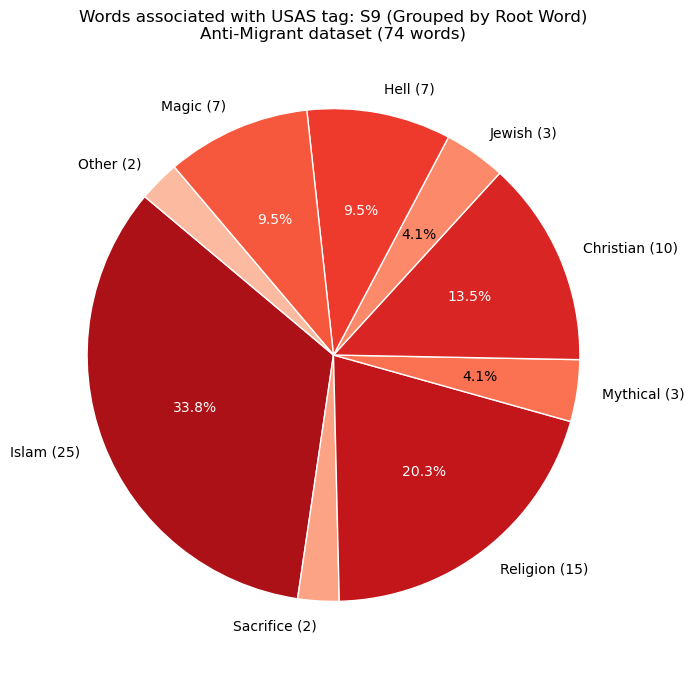

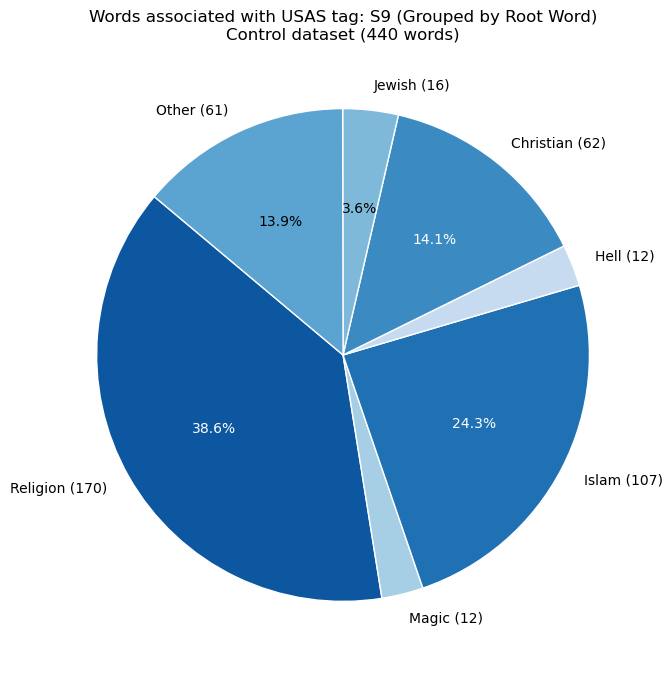

In [22]:
# Figures A1 and A2: S9 words in each corpus by root word (lemma, grouped with custom_conflate), with words under 2%
# combined as 'Other'. Thin slices are spread between larger ones, labels give word counts, and percentages are shown
# on slices of 3% or more. Saved as PNGs in OUTPUT_DIR.
import matplotlib.pyplot as plt
from matplotlib import colormaps


def visualise_from_USAS_tag(df_final, tag, corpus_label, colour_map):
    list_of_matches = []

    for lemma in df_final.loc[df_final['USAS_tags'] == tag, 'lemma']:
        # Grab the Lemma instead of raw text, group it into its root word and capitalize it
        clean_word = custom_conflate(lemma).capitalize()

        list_of_matches.append(clean_word)

    # 1. Check if we actually found any matches
    if not list_of_matches:
        print(f"No words found for tag '{tag}' in the {corpus_label} dataset. Cannot create pie chart.")
        return None

    # 2. Create the series and count frequencies
    match_series = pd.Series(list_of_matches).value_counts()

    # 3. Group items under 2% into 'Other'
    total_matches = match_series.sum()
    threshold = total_matches * 0.02  # Calculate what 2% is
    main_series = match_series[match_series >= threshold].copy()
    other_sum = match_series[match_series < threshold].sum()
    if other_sum > 0:
        main_series['Other'] = other_sum

    # 4. Spread the thin slices between the big ones (biggest, smallest, 2nd biggest, ...), keeping 'Other' last
    words = [w for w in main_series.index if w != 'Other']
    spread = []
    while words:
        spread.append(words.pop(0))
        if words:
            spread.append(words.pop())
    if 'Other' in main_series.index:
        spread.append('Other')
    main_series = main_series[spread]

    # 5. Plot the pie chart in shades of the corpus colour (darkest = most common word)
    rank = main_series.rank(method='first', ascending=False).astype(int) - 1
    palette = colormaps[colour_map](np.linspace(0.85, 0.25, len(main_series)))
    shades = [palette[r] for r in rank]
    fig, ax = plt.subplots(figsize=(8, 8))
    wedges, labels, autotexts = ax.pie(main_series.values,
                                       labels=[f"{w} ({n})" for w, n in main_series.items()],
                                       autopct=lambda pct: f'{pct:.1f}%' if pct >= 3 else '',
                                       startangle=140, colors=shades, wedgeprops={'edgecolor': 'white'})
    for autotext, shade in zip(autotexts, shades):
        # white percentages on dark slices, black on light ones
        autotext.set_color('white' if (0.299 * shade[0] + 0.587 * shade[1] + 0.114 * shade[2]) < 0.55 else 'black')
    ax.set_title(f"Words associated with USAS tag: {tag} (Grouped by Root Word)\n{corpus_label} dataset ({total_matches} words)")
    plt.savefig(OUTPUT_DIR / f"figure_pie_{tag}_{corpus_label.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
    plt.show()
    return main_series


if df_tokens is None:
    print("Skipped: run the tagging cell first.")
else:
    for corpus_label, colour_map in [(ANTI_MIGRANT_LABEL, 'Reds'), (CONTROL_LABEL, 'Blues')]:
        visualise_from_USAS_tag(df_tokens[df_tokens['Corpus'] == corpus_label], 'S9', corpus_label, colour_map)

### AI-ese (Figure 4)
Four USAS tags associated with LLM-generated text, tested with each comment as one unit.

       Anti-Migrant  Control  p_value  keyness_p (words independent)
tag                                                                 
A5.1+        0.1999   0.2419   0.0804                         0.0265
A7           0.0484   0.0618   0.2405                         0.1558
A7+          1.2390   1.3656   0.0555                         0.0057
X2.1         0.5272   0.4449   0.0492                         0.0028


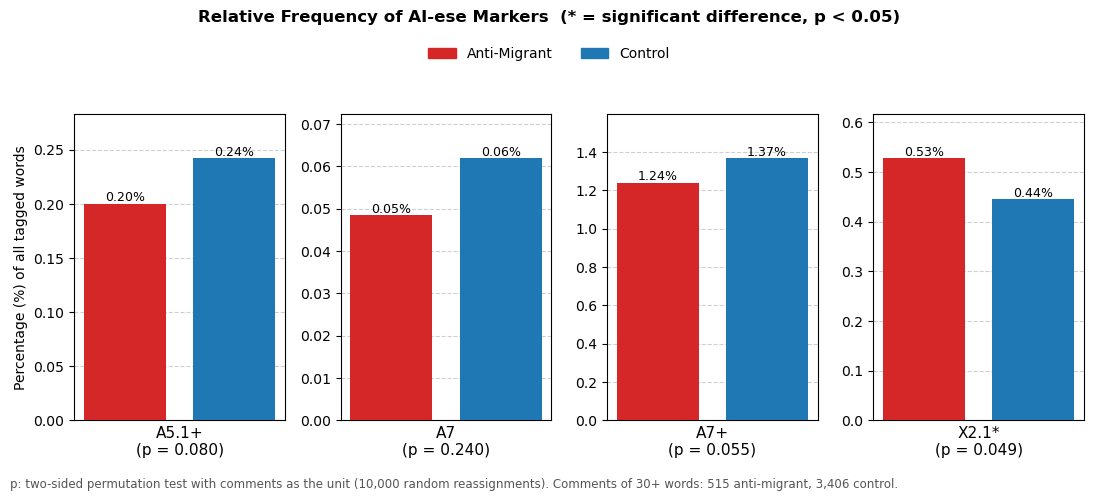

In [23]:
# Figure 4: frequency of the four AI-ese marker tags as a percentage of all tagged words in each corpus: A5.1+
# (evaluation: good), A7 (probability), A7+ (certainty) and X2.1 (thought and belief). The grammatical bin (Z5) is not
# used: it covers function words such as 'the' and 'of', whose frequency mainly reflects comment length and register.
# Words cluster within comments, so differences are tested with each comment as the unit: a two-sided permutation test
# that reassigns comments to the two corpora at random 10,000 times (Lijffijt et al., 2016). Each panel has its own
# y-axis, starting at zero.
from matplotlib.patches import Patch

if df_tokens is None:
    print("Skipped: run the tagging cell first.")
else:
    per_comment = df_tokens.groupby(['comment_id', 'Corpus']).size().rename('tokens').reset_index()
    for tag in AI_ESE_TAGS:
        per_comment[tag] = per_comment['comment_id'].map(df_tokens[df_tokens['USAS_tags'] == tag].groupby('comment_id').size()).fillna(0)
    is_anti_c = (per_comment['Corpus'] == ANTI_MIGRANT_LABEL).values
    rng = np.random.default_rng(42)
    shuffles = np.array([rng.permutation(is_anti_c) for _ in range(10000)])
    den = per_comment['tokens'].values.astype(float)

    rows = []
    for tag in AI_ESE_TAGS:
        num = per_comment[tag].values.astype(float)
        rate_a, rate_c = num[is_anti_c].sum() / den[is_anti_c].sum(), num[~is_anti_c].sum() / den[~is_anti_c].sum()
        a_num, a_den = shuffles @ num, shuffles @ den
        ratios = (a_num / a_den) / ((num.sum() - a_num) / (den.sum() - a_den))
        p = (np.sum(np.abs(np.log(ratios)) >= abs(np.log(rate_a / rate_c))) + 1) / (len(ratios) + 1)
        rows.append({'tag': tag, ANTI_MIGRANT_LABEL: 100 * rate_a, CONTROL_LABEL: 100 * rate_c, 'p_value': p,
                     'keyness_p (words independent)': keyness.loc[tag, 'p_value']})
    ai_ese = pd.DataFrame(rows).set_index('tag')
    print(ai_ese.round(4).to_string())
    ai_ese.to_csv(OUTPUT_DIR / 'figure4_ai_ese_markers.csv')

    fig, axes = plt.subplots(1, len(AI_ESE_TAGS), figsize=(11, 4.93))
    for i, (ax, (tag, r)) in enumerate(zip(axes, ai_ese.iterrows())):
        values = [r[ANTI_MIGRANT_LABEL], r[CONTROL_LABEL]]
        ax.bar([0, 1], values, width=0.75, color=[ANTI_MIGRANT_COLOUR, CONTROL_COLOUR], zorder=3)
        for x, v in enumerate(values):
            ax.text(x, v, f'{v:.2f}%', ha='center', va='bottom', fontsize=9)
        ax.set_xlabel(f"{tag}{'*' if r['p_value'] < 0.05 else ''}\n(p = {r['p_value']:.3f})", fontsize=11)
        ax.set_xticks([])
        ax.set_ylim(0, max(values) * 1.17)
        ax.yaxis.grid(True, linestyle='--', alpha=0.6, zorder=0)
        if i == 0:
            ax.set_ylabel('Percentage (%) of all tagged words')
    fig.suptitle('Relative Frequency of AI-ese Markers  (* = significant difference, p < 0.05)', fontweight='bold', fontsize=12)
    fig.legend(handles=[Patch(color=ANTI_MIGRANT_COLOUR, label=ANTI_MIGRANT_LABEL), Patch(color=CONTROL_COLOUR, label=CONTROL_LABEL)],
               loc='upper center', bbox_to_anchor=(0.5, 0.93), ncol=2, frameon=False)
    n_a, n_c = int(is_anti_c.sum()), int((~is_anti_c).sum())
    fig.text(0.01, 0.01, f'p: two-sided permutation test with comments as the unit (10,000 random reassignments). '
             f'Comments of 30+ words: {n_a} anti-migrant, {n_c:,} control.', fontsize=8.5, color='#555555')
    plt.tight_layout(rect=(0, 0.04, 1, 0.86))
    plt.savefig(OUTPUT_DIR / 'figure4_final.png', dpi=200)
    plt.show()


### Persuasive pivot
Comments that open with emotional language and close with cognition and certainty words.

In [24]:
# Persuasive pivot: in each comment of 15+ words, the first half is compared with the second. A pivot opens with
# emotional tags (E3-, E2-, A5.1-, A12-, E4, S1.1) and closes with more cognition and certainty tags (X2.1, A7+). The
# grammatical bin (Z5) is not counted as 'logic': it covers function words, which made up over a third of each half.
# Without Z5 the logic tags are about eleven times rarer, so the two logic thresholds (originally a 5-point rise and a
# 10% second-half density) are scaled down by the measured ratio of the two base rates; the emotion threshold is
# unchanged. The share of pivots in the two corpora is compared with a chi-square test. Uses the raw comment text.
# 1. Define the Global Tag Lists (The "Logic" and "Emotion" markers)
LOGIC_TAGS = ['X2.1', 'A7+']
ORIGINAL_LOGIC_TAGS = ['X2.1', 'Z5', 'A7+']   # used only to measure how much rarer the logic tags are without Z5
EMOTION_TAGS = ['E3-', 'E2-', 'A5.1-', 'A12-', 'E4', 'S1.1']
MIN_TOKENS = 15  # Lowered threshold to 15 to catch more conversational pivots


def has_tag(token, tag_list):
    tags = token._.pymusas_tags if hasattr(token._, 'pymusas_tags') and token._.pymusas_tags else []
    return any(any(tag.startswith(x) for x in tag_list) for tag in tags)


def densities(chunk):
    n = len(chunk)
    return (sum(has_tag(t, LOGIC_TAGS) for t in chunk) / n, sum(has_tag(t, ORIGINAL_LOGIC_TAGS) for t in chunk) / n,
            sum(has_tag(t, EMOTION_TAGS) for t in chunk) / n)


def halves(doc):
    tokens = [t for t in doc if not t.is_punct and not t.is_space]
    if len(tokens) < MIN_TOKENS:
        return None
    midpoint = len(tokens) // 2
    return densities(tokens[:midpoint]), densities(tokens[midpoint:])


if nlp is None:
    print("Skipped: needs the spaCy + PyMUSAS pipeline from the tagging cell (see the message there).")
else:
    rows = []
    docs = nlp.pipe(corpora['comment_body'].tolist(), batch_size=64)
    for (corpus, comment_id), doc in tqdm(zip(corpora[['Corpus', 'comment_id']].itertuples(index=False, name=None), docs),
                                          total=len(corpora), desc='Checking for pivots'):
        h = halves(doc)
        if h:
            (fl, fl_orig, fe), (sl, sl_orig, se) = h
            rows.append({'Corpus': corpus, 'comment_id': comment_id, 'fh_logic': fl, 'sh_logic': sl, 'fh_logic_with_Z5': fl_orig,
                         'sh_logic_with_Z5': sl_orig, 'fh_emotion': fe, 'sh_emotion': se})
    df_pivot_results = pd.DataFrame(rows)

    # Scale the logic thresholds to the lower base rate of the logic tags without Z5
    scale = (df_pivot_results[['fh_logic', 'sh_logic']].values.mean()
             / df_pivot_results[['fh_logic_with_Z5', 'sh_logic_with_Z5']].values.mean())
    LOGIC_SHIFT_MIN, SECOND_HALF_LOGIC_MIN, EMOTION_SHIFT_MIN = 0.05 * scale, 0.10 * scale, 0.03
    print(f"Logic tags are {1 / scale:.1f} times rarer without Z5: logic thresholds {LOGIC_SHIFT_MIN:.4f} (rise) "
          f"and {SECOND_HALF_LOGIC_MIN:.4f} (second-half density); emotion threshold {EMOTION_SHIFT_MIN}")

    # Detection logic: logic increases in the second half, emotion decreases from the first half, and the second half
    # contains logic tags
    df_pivot_results['is_persuasive_pivot'] = (
        (df_pivot_results['sh_logic'] - df_pivot_results['fh_logic'] > LOGIC_SHIFT_MIN)
        & (df_pivot_results['fh_emotion'] - df_pivot_results['sh_emotion'] > EMOTION_SHIFT_MIN)
        & (df_pivot_results['sh_logic'] > SECOND_HALF_LOGIC_MIN))
    df_pivot_results.to_csv(OUTPUT_DIR / 'persuasive_pivot_analysis.csv', index=False)

    summary = df_pivot_results.groupby('Corpus')['is_persuasive_pivot'].agg(analysed='size', pivots='sum')
    summary['comments in corpus'] = corpora['Corpus'].value_counts()
    summary['% of analysed'] = (100 * summary['pivots'] / summary['analysed']).round(2)
    print(summary.to_string())

    contingency = [[summary.loc[c, 'pivots'], summary.loc[c, 'analysed'] - summary.loc[c, 'pivots']]
                   for c in [ANTI_MIGRANT_LABEL, CONTROL_LABEL]]
    chi2, p_pivot, _, _ = stats.chi2_contingency(contingency)
    print(f"\nChi-square = {chi2:.2f}, p = {p_pivot:.3f}")


Checking for pivots:   0%|          | 0/3921 [00:00<?, ?it/s]

Logic tags are 11.5 times rarer without Z5: logic thresholds 0.0043 (rise) and 0.0087 (second-half density); emotion threshold 0.03
              analysed  pivots  comments in corpus  % of analysed
Corpus                                                           
Anti-Migrant       515      35                 515           6.80
Control           3406     287                3406           8.43

Chi-square = 1.37, p = 0.242


## RQ3: UK local election relevance
Did anti-migrant discourse surge on Reddit in the two weeks prior to the election, and who drove it?

### The anti-migrant share (Figures 5 and 6)
The daily share of UK-relevant comments labelled Anti-migrant is compared before 23 April, in the final two weeks (23 April – 7 May) and after polling day, then split into how much of the conversation was about migration and how much of that was hostile.

Original size: 6093 | Cleaned size: 6093


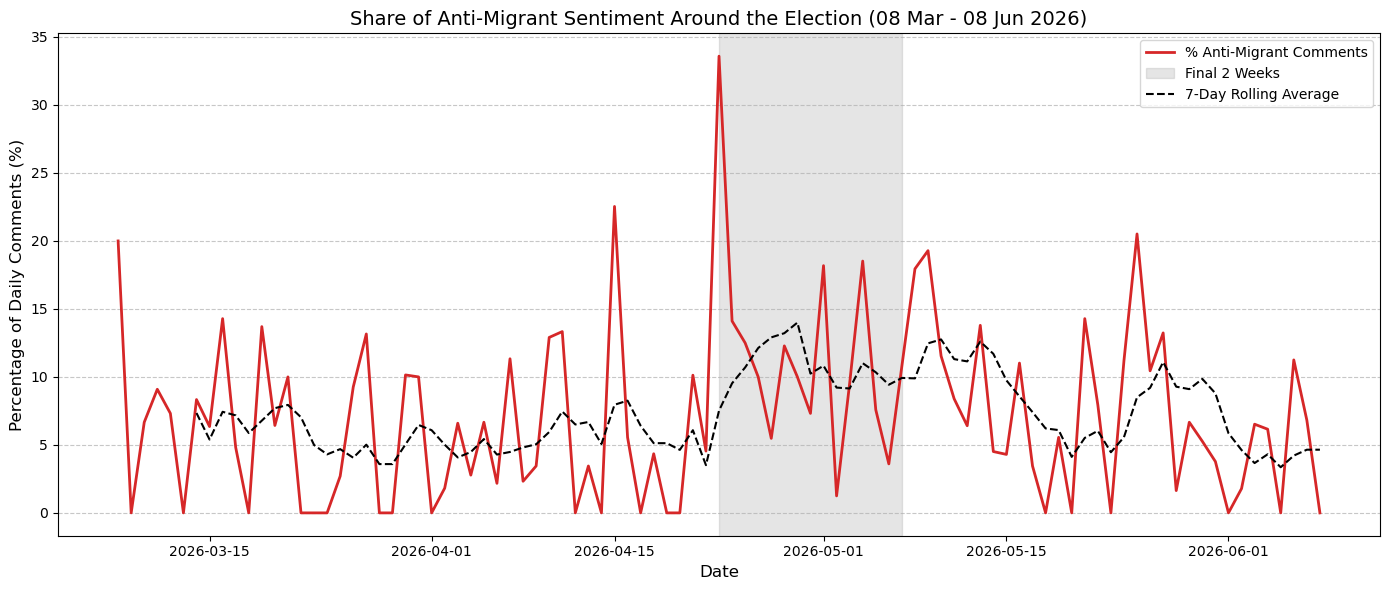


--- Statistical Summary ---
Avg daily share BEFORE April 23 (46 days): 5.8%
Avg daily share April 23 - May 7 (15 days): 11.7%
Avg daily share AFTER polling day (32 days): 7.3%
Mann-Whitney U on daily shares: U = 518, one-sided p = 0.0019
Pooled share: 7.8% before vs 11.8% in the final two weeks (chi-square = 14.5, p = 0.0001366)
Caveat: comments in the same thread aren't independent, so treat the p-values as indicative rather than exact.


In [25]:
# Figure 5: daily share of UK-relevant comments labelled Anti-migrant by Ministral-14B, with a 7-day rolling mean and
# the final two weeks shaded. Daily shares in the final two weeks are compared with those before 23 April (one-sided
# Mann-Whitney U), and the pooled shares with a chi-square test. Comments in the same thread are not independent, so
# the p-values are indicative rather than exact.
import matplotlib.pyplot as plt
from scipy import stats

# ==========================================
# 1. LOAD AND CLEAN THE MAIN DATASET
# ==========================================
df_main = df_combined.copy()

# Remove duplicates based on the unique comment ID, keeping the first instance
df_main_cleaned = df_main.drop_duplicates(subset=['comment_id'], keep='first')

print(f"Original size: {len(df_main)} | Cleaned size: {len(df_main_cleaned)}")

# ==========================================
# 2. MERGE THE LLM LABELS
# ==========================================
# A "left join" keeps every comment in the main dataset and attaches 'llm_mapped_label'
# only to the comments that went through the LLM check.
df_merged = pd.merge(
    df_main_cleaned,
    df_anti_migrant_LLM_verified[['comment_id', 'llm_mapped_label']], # Only bring over the ID and the Label
    on='comment_id',
    how='left',
    validate='one_to_one'  # stops with an error if a comment appears twice
)

# The comments that weren't checked by the LLM will have "NaN" for the label.
# Fill those empty spaces with "Not Flagged" for easier tracking.
df_merged['llm_mapped_label'] = df_merged['llm_mapped_label'].fillna('Not Flagged')

# ==========================================
# 3. PREPARE THE TIMELINE DATA
# ==========================================
df_merged['created_utc_comment'] = pd.to_datetime(df_merged['created_utc_comment'])

# Create a clean "Date Only" column to group by day
df_merged['date'] = df_merged['created_utc_comment'].dt.date

# Calculate Daily Total Volume (The Control)
daily_total = df_merged.groupby('date').size()

# Calculate Daily Anti-Migrant Volume (The Signal)
daily_anti = df_merged[df_merged['llm_mapped_label'] == 'Anti-migrant'].groupby('date').size()

# Reindex daily_anti to match daily_total so we don't get errors on days with 0 anti-migrant comments
daily_anti = daily_anti.reindex(daily_total.index, fill_value=0)

# Calculate the Share of Voice (Percentage)
share_of_voice = (daily_anti / daily_total) * 100

pd.DataFrame({'total_comments': daily_total, 'anti_migrant_comments': daily_anti,
              'share_of_voice_pct': share_of_voice.round(2)}).to_csv(OUTPUT_DIR / 'daily_share_of_voice.csv')

# ==========================================
# 4. VISUALIZATION: THE TWO-WEEK SURGE CHECK
# ==========================================
plt.figure(figsize=(14, 6))

# Plot the percentage line
share_of_voice.plot(color=ANTI_MIGRANT_COLOUR, linewidth=2, label='% Anti-Migrant Comments')

# Mark the "Final Two Weeks" Window (April 23 - May 7)
plt.axvspan(SURGE_START.date(), ELECTION_DAY.date(), color='gray', alpha=0.2, label='Final 2 Weeks')

# Add a trendline (rolling 7-day average) to smooth out daily noise
share_of_voice.rolling(window=7).mean().plot(
    color='black', linestyle='--', label='7-Day Rolling Average'
)

# Formatting
plt.title(f"Share of Anti-Migrant Sentiment Around the Election ({share_of_voice.index.min():%d %b} - {share_of_voice.index.max():%d %b %Y})", fontsize=14)
plt.ylabel('Percentage of Daily Comments (%)', fontsize=12)
plt.xlabel('Date', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'share_of_voice_surge.png', dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 5. STATISTICAL SUMMARY
# ==========================================
# Compare the average daily percentage before and during the final two weeks (up to and including polling day)
before_window = share_of_voice[(share_of_voice.index >= ANALYSIS_START.date()) & (share_of_voice.index < SURGE_START.date())]
final_two_weeks = share_of_voice[(share_of_voice.index >= SURGE_START.date()) & (share_of_voice.index <= ELECTION_DAY.date())]

print(f"\n--- Statistical Summary ---")
print(f"Avg daily share BEFORE April 23 ({len(before_window)} days): {before_window.mean():.1f}%")
print(f"Avg daily share April 23 - May 7 ({len(final_two_weeks)} days): {final_two_weeks.mean():.1f}%")
after_election = share_of_voice[share_of_voice.index > ELECTION_DAY.date()]
if len(after_election):  # post-election baseline
    print(f"Avg daily share AFTER polling day ({len(after_election)} days): {after_election.mean():.1f}%")

# Are the daily shares in the final two weeks higher than before? (Mann-Whitney U, one-sided)
u_stat, p_days = stats.mannwhitneyu(final_two_weeks, before_window, alternative='greater')
print(f"Mann-Whitney U on daily shares: U = {u_stat:.0f}, one-sided p = {p_days:.4f}")

# Pooled comparison of comment counts in the two periods (chi-square)
in_before = (df_merged['date'] >= ANALYSIS_START.date()) & (df_merged['date'] < SURGE_START.date())
in_final = (df_merged['date'] >= SURGE_START.date()) & (df_merged['date'] <= ELECTION_DAY.date())
is_anti = df_merged['llm_mapped_label'] == 'Anti-migrant'
contingency = [[(is_anti & in_final).sum(), (~is_anti & in_final).sum()],
               [(is_anti & in_before).sum(), (~is_anti & in_before).sum()]]
chi2, p_chi, _, _ = stats.chi2_contingency(contingency)
print(f"Pooled share: {contingency[1][0] / in_before.sum() * 100:.1f}% before vs "
      f"{contingency[0][0] / in_final.sum() * 100:.1f}% in the final two weeks (chi-square = {chi2:.1f}, p = {p_chi:.4g})")
print("Caveat: comments in the same thread aren't independent, so treat the p-values as indicative rather than exact.")

           Period  UK-relevant comments  Mention migration (%)  Hostile share of migration comments (%)  Anti-migrant share of all comments (%)
  Before 23 April                  2069                   15.5                                     50.6                                     7.8
 23 April – 7 May                  1293                   22.7                                     52.0                                    11.8
After polling day                  2731                   16.4                                     57.5                                     9.4


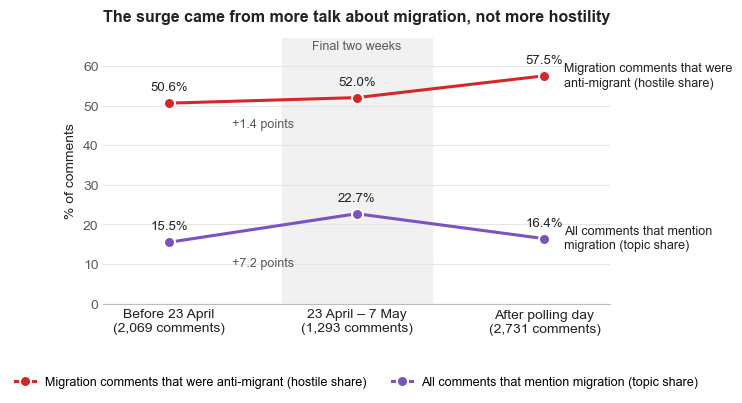

In [26]:
# Figure 6 and the table behind it. The anti-migrant share of all comments is the product of two parts: how much of the
# conversation mentions migration (topic share) and how much of that is anti-migrant (hostile share). Splitting it by
# period shows which part changed.
TOPIC_COLOUR = '#7b52c4'   # purple: migration talk (red keeps its meaning of anti-migrant hostility)

periods = {'Before 23 April': df_merged['date'] < SURGE_START.date(),
           '23 April – 7 May': (df_merged['date'] >= SURGE_START.date()) & (df_merged['date'] <= ELECTION_DAY.date()),
           'After polling day': df_merged['date'] > ELECTION_DAY.date()}
rows = []
for name, in_period in periods.items():
    sub = df_merged[in_period]
    mentions = sub['migration_flag'].astype(bool)
    hostile = sub['llm_mapped_label'] == 'Anti-migrant'
    rows.append({'Period': name, 'UK-relevant comments': len(sub), 'Mention migration (%)': 100 * mentions.mean(),
                 'Hostile share of migration comments (%)': 100 * hostile[mentions].mean(),
                 'Anti-migrant share of all comments (%)': 100 * hostile.mean()})
table2 = pd.DataFrame(rows)
print(table2.round(1).to_string(index=False))
table2.round(2).to_csv(OUTPUT_DIR / 'table2_topic_and_hostile_share.csv', index=False)

talk = table2['Mention migration (%)'].round(1).tolist()
hostile = table2['Hostile share of migration comments (%)'].round(1).tolist()
labels = [f"{p}\n({n:,} comments)" for p, n in zip(table2['Period'], table2['UK-relevant comments'])]
INK, MUTED, GRID = '#222222', '#5b5b5b', '#e6e6e6'
with plt.rc_context({'font.family': 'Arial', 'font.size': 10}):
    fig, ax = plt.subplots(figsize=(7.2, 4.4))
    ax.axvspan(0.6, 1.4, color='#f1f1f1', zorder=0)
    ax.text(1, 66.5, 'Final two weeks', ha='center', va='top', fontsize=9, color=MUTED)
    for ys, colour, name in [(hostile, ANTI_MIGRANT_COLOUR, 'Migration comments that were\nanti-migrant (hostile share)'),
                             (talk, TOPIC_COLOUR, 'All comments that mention\nmigration (topic share)')]:
        ax.plot(range(3), ys, color=colour, lw=2.2, marker='o', ms=8, mec='white', mew=1.5, zorder=3, label=name.replace('\n', ' '))
        for x, y in enumerate(ys):
            ax.annotate(f'{y:.1f}%', (x, y), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9.5, color=INK, zorder=4)
        ax.annotate(name, (2, ys[-1]), xytext=(14, 0), textcoords='offset points', va='center', fontsize=9, color=INK)
    ax.annotate(f'{talk[1] - talk[0]:+.1f} points', xy=(0.5, (talk[0] + talk[1]) / 2), xytext=(0.5, 9.5), ha='center', fontsize=9, color=MUTED)
    ax.annotate(f'{hostile[1] - hostile[0]:+.1f} points', xy=(0.5, (hostile[0] + hostile[1]) / 2), xytext=(0.5, 44.5), ha='center', fontsize=9, color=MUTED)
    ax.set_xlim(-0.35, 2.35); ax.set_ylim(0, 67)
    ax.set_xticks(range(3)); ax.set_xticklabels(labels, color=INK)
    ax.set_ylabel('% of comments', color=INK)
    ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color('#bdbdbd')
    ax.tick_params(axis='y', colors=MUTED, length=0); ax.tick_params(axis='x', length=0)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.36), ncol=2, frameon=False, fontsize=9, handlelength=1.6)
    ax.set_title('The surge came from more talk about migration, not more hostility', fontsize=11.5, fontweight='bold',
                 color=INK, loc='left', pad=12)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'figure_table2_as_chart.png', dpi=300, bbox_inches='tight')
    plt.show()

### Surge accounts
The **surge accounts** posted at least one comment labelled Anti-migrant between 23 April and polling day; the **control** is every other account that commented in the same threads during that fortnight. Each indicator is compared with the control rather than judged in isolation, because ordinary users also cluster, repeat themselves and post in bursts.

In [27]:
# Surge accounts: every account with at least one comment labelled Anti-migrant between 23 April and polling day
# (inclusive), excluding the accounts in EXCLUDED_ACCOUNTS.
# 1. Define our two strict conditions
is_anti_migrant = df_merged['llm_mapped_label'] == 'Anti-migrant'
is_two_week_window = (df_merged['created_utc_comment'] >= SURGE_START) & (df_merged['created_utc_comment'] < ELECTION_DAY + pd.Timedelta(days=1))

# 2. Apply both conditions and extract the unique author names
surge_users = df_merged[is_anti_migrant & is_two_week_window]['author_comment'].dropna().unique()
surge_users = [user for user in surge_users if user not in EXCLUDED_ACCOUNTS]

print(f"Total unique accounts responsible for the surge: {len(surge_users)}")

Total unique accounts responsible for the surge: 121


In [28]:
# Account audit: the creation date and current status (deleted or suspended) of every account in the dataset, through
# the Reddit API. Network or rate-limit errors are recorded as 'ERROR' rather than as deleted. With
# RUN_ACCOUNT_AUDIT = False the saved audit (AUDIT_FILE) is summarised instead.
if RUN_ACCOUNT_AUDIT:
    print("Identifying user groups...")

    surge_set = set(surge_users)

    # Get Non-Surge Users (Everyone else!)
    all_users = df_merged['author_comment'].dropna().unique()
    non_surge_users = [user for user in all_users if user not in surge_set and user not in EXCLUDED_ACCOUNTS]

    print(f"Total Surge Accounts: {len(surge_users)}")
    print(f"Total Non-Surge (Control) Accounts: {len(non_surge_users)}")

    # Combine them into a dictionary so we only need one API loop
    user_targets = {user: 'Surge Account' for user in surge_users}
    for user in non_surge_users:
        user_targets[user] = 'Non-Surge Account'

    if MAX_USERS:
        # Test mode: half surge, half non-surge accounts
        test_users = list(surge_users)[:MAX_USERS // 2]
        test_users += non_surge_users[:MAX_USERS - len(test_users)]
        user_targets = {user: user_targets[user] for user in test_users}
        print(f"TEST MODE: only checking {len(user_targets)} accounts")

    # ==========================================
    # RUN THE AUDIT LOOP
    # ==========================================
    user_data = []
    total_to_check = len(user_targets)

    print(f"\nFetching data for {total_to_check} users. Grab a coffee, this will take a while due to rate limits...")

    # Enumerate allows us to keep a count (i) as we loop
    for i, (username, group_label) in enumerate(user_targets.items(), 1):

        # Print a progress update every 100 accounts
        if i % 100 == 0:
            print(f"Processed {i}/{total_to_check} accounts...")

        try:
            user = reddit.redditor(username)

            # Accessing an attribute triggers the API call
            created_utc = user.created_utc
            creation_date = datetime.fromtimestamp(created_utc)

            user_data.append({
                'username': username,
                'created_at': creation_date,
                'comment_karma': getattr(user, 'comment_karma', 0),
                'group': group_label  # used by the account-age chart
            })
        except (prawcore.exceptions.NotFound, prawcore.exceptions.Forbidden, AttributeError):
            # Deleted, suspended or shadowbanned accounts (suspended accounts have no creation date)
            user_data.append({
                'username': username,
                'created_at': 'DELETED/BANNED',
                'comment_karma': 0,
                'group': group_label
            })
        except Exception as e:
            # anything else (network trouble, Reddit being down) is not evidence of a ban
            print(f"   Could not check {username}: {e}")
            user_data.append({
                'username': username,
                'created_at': 'ERROR',
                'comment_karma': 0,
                'group': group_label
            })

    # ==========================================
    # SAVE THE EVIDENCE
    # ==========================================
    df_full_audit = pd.DataFrame(user_data)
    df_full_audit.to_csv(AUDIT_FILE, index=False)

    print("\n--- AUDIT COMPLETE ---")
    print(f"Saved results to {AUDIT_FILE.name}")

else:
    df_full_audit = pd.read_csv(AUDIT_FILE)
    print(f"RUN_ACCOUNT_AUDIT is False: using the saved audit of {len(df_full_audit)} accounts ({AUDIT_FILE.name}).")

# Status of each group's accounts when audited (October 2026); group membership follows the current surge list
audit_now = df_full_audit[~df_full_audit['username'].isin(EXCLUDED_ACCOUNTS)].copy()
audit_now['group'] = np.where(audit_now['username'].isin(set(surge_users)), 'Surge Account', 'Non-Surge Account')
audit_now['status'] = audit_now['created_at'].astype(str).map(
    lambda s: 'deleted or suspended' if s == 'DELETED/BANNED' else 'not checked (error)' if s == 'ERROR' else 'active')
print(pd.crosstab(audit_now['group'], audit_now['status']).to_string())

RUN_ACCOUNT_AUDIT is False: using the saved audit of 3350 accounts (combined_users_audit_results.csv).
status             active  deleted or suspended
group                                          
Non-Surge Account    3129                    94
Surge Account         115                     6


### Complete comment histories (Arctic Shift)
Reddit's API returns at most an account's 1,000 most recent comments, with no date filter, and since 2025 users can hide their comment history; about half of the accounts studied had done so by October 2026. Complete histories for the study period were therefore taken from Arctic Shift (Heitmann, 2026), a public research archive that collects comments through Reddit's API shortly after they are posted and checks them again 36 hours later. It includes accounts that have since hidden their history or been deleted.

In [29]:
# Downloads every comment that each surge and control account posted in the study period from the Arctic Shift API
# (https://arctic-shift.photon-reddit.com), about one request a second for three accounts at a time. When the server
# times out on a very active account, the rest of its period is fetched a week at a time. Progress is saved after each
# account, so an interrupted download resumes where it stopped. Runs only when RUN_ARCTIC_SHIFT_PULL = True.
import time
import threading
import urllib.request
import urllib.parse
from concurrent.futures import ThreadPoolExecutor

ARCTIC_API = 'https://arctic-shift.photon-reddit.com/api'
ARCTIC_HEADERS = {'User-Agent': 'academic-research (astroturfing study)'}
ARCTIC_FIELDS = 'id,author,created_utc,subreddit,link_id,parent_id,body,score,retrieved_on'
ARCTIC_STATUS = ARCTIC_DIR / 'pull_status.csv'

in_fortnight = (df_merged['created_utc_comment'] >= SURGE_START) & (df_merged['created_utc_comment'] < ELECTION_DAY + pd.Timedelta(days=1))
control_accounts = sorted(set(df_merged.loc[in_fortnight, 'author_comment'].dropna()) - set(surge_users) - EXCLUDED_ACCOUNTS - {'[deleted]'})
targets = [(u, 'Surge Account') for u in sorted(surge_users)] + [(u, 'Non-Surge Account') for u in control_accounts]
print(f"{len(surge_users)} surge accounts and {len(control_accounts)} control accounts")


def arctic_request(endpoint, params, retries=6, timeout=90):
    # returns the 'data' list, or None after the given number of failed attempts
    url = f'{ARCTIC_API}/{endpoint}?' + urllib.parse.urlencode(params)
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=ARCTIC_HEADERS), timeout=timeout) as response:
                data = json.load(response)['data']
            if data is not None:
                return data
            time.sleep(20 * (attempt + 1))   # the server asked for a pause ('Timeout. Maybe slow down a bit')
        except urllib.error.HTTPError as e:
            time.sleep(int(e.headers.get('X-RateLimit-Reset', 30)) + 2 if e.code == 429 else 15 * (attempt + 1))
        except Exception:
            if retries == 1:
                return None
            time.sleep(15 * (attempt + 1))
    return None


def fetch_account(name, start, end):
    # pages through the account's comments in date order, 100 at a time
    rows, after = [], start
    while True:
        batch = arctic_request('comments/search', {'author': name, 'after': after, 'before': end, 'limit': 100, 'sort': 'asc',
                                                   'fields': ARCTIC_FIELDS}, retries=1, timeout=20)
        time.sleep(0.4)
        if batch is None:   # timed out: fetch the rest a week at a time, with retries
            for week in range(after, end, 7 * 86400):
                w_after = week
                while True:
                    part = arctic_request('comments/search', {'author': name, 'after': w_after, 'before': min(week + 7 * 86400, end),
                                                              'limit': 100, 'sort': 'asc', 'fields': ARCTIC_FIELDS})
                    if part is None:
                        raise RuntimeError('no response from Arctic Shift')
                    time.sleep(0.4)
                    rows += part
                    if len(part) < 100:
                        break
                    w_after = int(part[-1]['created_utc'])
            return rows
        rows += batch
        if len(batch) < 100:
            return rows
        last = int(batch[-1]['created_utc'])
        after = last if last > after else after + 1


if RUN_ARCTIC_SHIFT_PULL:
    ARCTIC_DIR.mkdir(parents=True, exist_ok=True)
    start = int(pd.Timestamp(ANALYSIS_START, tz='UTC').timestamp())
    end = int((pd.Timestamp(ANALYSIS_END, tz='UTC') + pd.Timedelta(days=1)).timestamp())
    done = set(pd.read_csv(ARCTIC_STATUS)['username']) if ARCTIC_STATUS.exists() else set()
    lock = threading.Lock()

    def pull_one(item):
        name, group = item
        try:
            rows = fetch_account(name, start, end)
        except Exception as e:
            print(f"   account skipped ({e}); run the cell again to retry")
            return
        with lock:
            if rows:
                d = pd.DataFrame(rows).drop_duplicates('id').rename(columns={'id': 'comment_id', 'author': 'username'})
                d['created_at'] = (pd.to_datetime(d['created_utc'], unit='s').dt.tz_localize('UTC')
                                   .dt.tz_convert('Europe/London').dt.tz_localize(None))   # UK time, as in the thread data
                d['group'] = group
                d.to_csv(ARCTIC_RAW, mode='a', header=not ARCTIC_RAW.exists(), index=False)
            pd.DataFrame([{'username': name, 'group': group, 'status': 'ok', 'comments': len(rows)}]).to_csv(
                ARCTIC_STATUS, mode='a', header=not ARCTIC_STATUS.exists(), index=False)

    todo = [t for t in targets if t[0] not in done]
    print(f"{len(todo)} accounts to download")
    with ThreadPoolExecutor(max_workers=3) as pool:
        list(tqdm(pool.map(pull_one, todo), total=len(todo), desc='Arctic Shift'))
else:
    print(f"RUN_ARCTIC_SHIFT_PULL is False: using the saved download ({ARCTIC_RAW.name}).")

121 surge accounts and 627 control accounts
RUN_ARCTIC_SHIFT_PULL is False: using the saved download (arctic_shift_comments_8Mar_to_8Jun.csv).


In [30]:
# Deletion check for every archived comment. (A) Arctic Shift re-checks each comment 36 hours after it is posted and
# records whether it had gone, and whether it was deleted by its author ('deleted') or removed by moderators or Reddit
# ('removed'). (B) The Reddit API gives each comment's status at the time of the check (October 2026). Both parts
# resume if interrupted. Runs only when RUN_DELETION_CHECK = True.
if RUN_DELETION_CHECK:
    ids = pd.read_csv(ARCTIC_RAW, usecols=['comment_id'])['comment_id'].drop_duplicates().tolist()

    # (A) Arctic Shift, 500 comments per request
    done = set(pd.read_csv(DELETION_ARCTIC_FILE)['comment_id']) if DELETION_ARCTIC_FILE.exists() else set()
    todo = [i for i in ids if i not in done]
    for k in tqdm(range(0, len(todo), 500), desc='Arctic Shift status'):
        data = arctic_request('comments/ids', {'ids': ','.join(todo[k:k + 500])}, timeout=120)
        if data is None:
            continue
        meta = [(c['id'], c.get('_meta') or {}) for c in data]
        pd.DataFrame([{'comment_id': i, 'was_deleted_within_36h': bool(m.get('was_deleted_later')), 'removal_type_36h': m.get('removal_type'),
                       'edited_within_36h': bool(m.get('is_edited')), 'was_initially_deleted': bool(m.get('was_initially_deleted'))}
                      for i, m in meta]).to_csv(DELETION_ARCTIC_FILE, mode='a', header=not DELETION_ARCTIC_FILE.exists(), index=False)
        time.sleep(1)

    # (B) Reddit API, 100 comments per request
    done = set(pd.read_csv(DELETION_REDDIT_FILE)['comment_id']) if DELETION_REDDIT_FILE.exists() else set()
    todo = [i for i in ids if i not in done]
    for k in tqdm(range(0, len(todo), 100), desc='Reddit status'):
        batch = todo[k:k + 100]
        found = {c.id: c for c in reddit.info(fullnames=['t1_' + i for i in batch])}
        rows = []
        for i in batch:
            c = found.get(i)
            if c is None:
                status = 'not returned'
            elif c.body == '[deleted]':
                status = 'deleted by user'
            elif c.body == '[removed]' or getattr(c, 'removed_by_category', None):
                status = 'removed (moderators/Reddit)'
            elif c.author is None:
                status = 'account deleted (comment kept)'
            else:
                status = 'still live'
            rows.append({'comment_id': i, 'status_now': status, 'removed_by_category': getattr(c, 'removed_by_category', None) if c else None,
                         'edited_ever': bool(getattr(c, 'edited', False)) if c else None, 'score_now': getattr(c, 'score', None) if c else None})
        pd.DataFrame(rows).to_csv(DELETION_REDDIT_FILE, mode='a', header=not DELETION_REDDIT_FILE.exists(), index=False)
else:
    print(f"RUN_DELETION_CHECK is False: using the saved checks ({DELETION_ARCTIC_FILE.name}, {DELETION_REDDIT_FILE.name}).")

RUN_DELETION_CHECK is False: using the saved checks (deletion_flags_arctic_36h.csv, deletion_status_reddit_now.csv).


In [31]:
# Prepares the archived comments for analysis (study period only, excluded accounts removed) and checks the archive's
# completeness against the other sources available: the collected threads and, where present, earlier downloads of the
# same accounts through the Reddit API. If the archive holds (nearly) every comment those sources found, it can be
# treated as complete.
if RUN_ARCTIC_SHIFT_PULL or not TIMELINE_FILE.exists():
    raw = pd.read_csv(ARCTIC_RAW, low_memory=False).drop_duplicates('comment_id')
    raw = raw[~raw['username'].isin(EXCLUDED_ACCOUNTS)]
    raw['created_at'] = pd.to_datetime(raw['created_at'])
    raw = raw[(raw['created_at'] >= ANALYSIS_START) & (raw['created_at'] < ANALYSIS_END + pd.Timedelta(days=1))]
    raw[['username', 'comment_id', 'parent_id', 'link_id', 'created_at', 'subreddit', 'body', 'score', 'group']].to_csv(TIMELINE_FILE, index=False)

df_timeline = pd.read_csv(TIMELINE_FILE, parse_dates=['created_at'], low_memory=False)
df_timeline = df_timeline[~df_timeline['username'].isin(EXCLUDED_ACCOUNTS)]
print(f"Complete histories: {len(df_timeline):,} comments from {df_timeline['username'].nunique()} accounts")
print(df_timeline.groupby('group')['username'].nunique().rename('accounts with comments').to_string(), '\n')

arctic_ids = set(df_timeline['comment_id'])
accounts = set(df_timeline['username'])


def coverage(label, ids_df, id_col, user_col, time_col):
    d = ids_df[ids_df[user_col].isin(accounts)].copy()
    d[time_col] = pd.to_datetime(d[time_col], errors='coerce')
    d = d[(d[time_col] >= ANALYSIS_START) & (d[time_col] < ANALYSIS_END + pd.Timedelta(days=1))].drop_duplicates(id_col)
    found = d[id_col].isin(arctic_ids).mean() if len(d) else np.nan
    print(f"{label:55s} {len(d):7,} comments in the period -> {found:6.1%} also in the archive")
    return {'source': label, 'comments_in_period': len(d), 'share_found_in_arctic_shift': found}


checks = [coverage('Collected election threads', df_combined, 'comment_id', 'author_comment', 'created_utc_comment')]
for label, path in [('Reddit API, each account\'s latest 250 comments (October 2026)', OUTPUT_DIR / 'user_historical_timeline_SYMMETRIC.csv'),
                    ('Reddit API, latest 1,000 comments x 3 sort orders (October 2026)', OUTPUT_DIR / 'repull_1000_multisort' / 'timeline_1000_multisort.csv'),
                    ('Earlier files (June 2026)', OUTPUT_DIR / 'june_recovery' / 'recovered_comments_8Mar_to_8Jun.csv')]:
    if path.exists():
        checks.append(coverage(label, pd.read_csv(path, usecols=['comment_id', 'username', 'created_at'], low_memory=False),
                               'comment_id', 'username', 'created_at'))
pd.DataFrame(checks).to_csv(HISTORY_RESULTS_DIR / 'arctic_shift_coverage_check.csv', index=False)

Complete histories: 484,804 comments from 747 accounts
group
Non-Surge Account    626
Surge Account        121 

Collected election threads                                2,011 comments in the period -> 100.0% also in the archive


Reddit API, each account's latest 250 comments (October 2026)  10,547 comments in the period ->  99.9% also in the archive


Reddit API, latest 1,000 comments x 3 sort orders (October 2026)  97,844 comments in the period -> 100.0% also in the archive
Earlier files (June 2026)                                28,305 comments in the period -> 100.0% also in the archive


### Account age (Figure 7)
A cluster of newly created ('newborn') accounts is a common sign of inauthentic activity.

--- Data Summary ---
                   Created in Past Year  Created in Past 3 Months
group                                                            
Non-Surge Account                  10.4                       2.4
Surge Account                       8.7                       0.0
(accounts with a creation date: {'Non-Surge Account': 3129, 'Surge Account': 115})

With the control used in the rest of RQ3 (accounts active in the final two weeks):
                   Created in Past Year  Created in Past 3 Months
group                                                            
Non-Surge Account                  12.5                       2.5
Surge Account                       8.7                       0.0


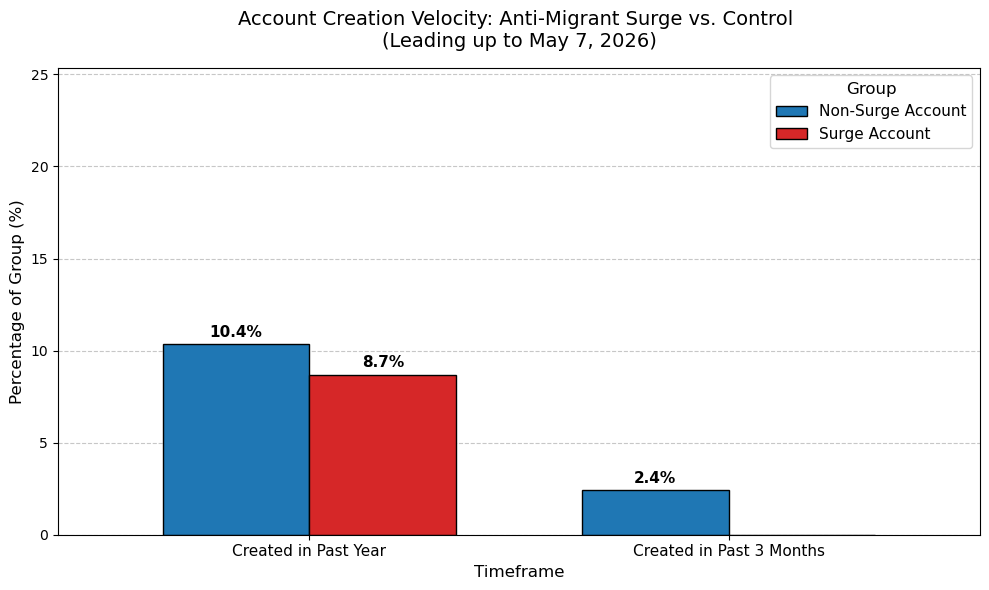

In [32]:
# Figure 7: share of surge and control accounts created in the year (from 7 May 2025) and in the three months (from
# 7 February 2026) before polling day. The control here is every other account in the dataset. Deleted, suspended and
# unchecked accounts have no creation date and are left out. The same shares for the control used in the rest of
# RQ3 (accounts that commented in the final two weeks) are printed underneath.
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD AND PREP THE DATA
# ==========================================
df_audit = audit_now.drop(columns='status')   # the audit, with the excluded accounts removed (cell above)

# Filter out deleted (and un-checkable) accounts
df_clean = df_audit[~df_audit['created_at'].isin(['DELETED/BANNED', 'ERROR'])].copy()

# Convert to standard datetime
df_clean['created_at'] = pd.to_datetime(df_clean['created_at'])

# ==========================================
# 2. DEFINE THE TIMEFRAMES
# ==========================================
# Election Date: May 7, 2026
cutoff_1_year = pd.to_datetime('2025-05-07')
cutoff_3_months = pd.to_datetime('2026-02-07')

# Create True/False columns for both thresholds
df_clean['Created in Past Year'] = df_clean['created_at'] >= cutoff_1_year

# Note: Accounts created in the past 3 months are technically ALSO in the past year.
# This metric isolates just the immediate run-up.
df_clean['Created in Past 3 Months'] = df_clean['created_at'] >= cutoff_3_months

# ==========================================
# 3. CALCULATE PROPORTIONS
# ==========================================
timeframe_rates = df_clean.groupby('group')[['Created in Past Year', 'Created in Past 3 Months']].mean() * 100

print("--- Data Summary ---")
print(timeframe_rates.round(1))
print(f"(accounts with a creation date: {df_clean['group'].value_counts().to_dict()})")

# The same shares with the control used in the rest of RQ3: accounts that commented in the final two weeks
in_fortnight = (df_merged['created_utc_comment'] >= SURGE_START) & (df_merged['created_utc_comment'] < ELECTION_DAY + pd.Timedelta(days=1))
fortnight_accounts = set(df_merged.loc[in_fortnight, 'author_comment'].dropna())
fortnight_rates = df_clean[df_clean['username'].isin(fortnight_accounts)].groupby('group')[['Created in Past Year', 'Created in Past 3 Months']].mean() * 100
print("\nWith the control used in the rest of RQ3 (accounts active in the final two weeks):")
print(fortnight_rates.round(1))

# ==========================================
# 4. VISUALIZATION (Clustered Bar Chart)
# ==========================================
plt.figure(figsize=(10, 6))

# Plotting both columns. Pandas automatically clusters them when given multiple columns.
ax = timeframe_rates.T.plot(
    kind='bar',
    color=[ANTI_MIGRANT_COLOUR if g == 'Surge Account' else CONTROL_COLOUR for g in timeframe_rates.index], # Red = Surge, Blue = Non-Surge
    width=0.7,
    edgecolor='black',
    ax=plt.gca()
)

# Formatting the chart
plt.title('Account Creation Velocity: Anti-Migrant Surge vs. Control \n(Leading up to May 7, 2026)', fontsize=14, pad=15)
plt.ylabel('Percentage of Group (%)', fontsize=12)
plt.xlabel('Timeframe', fontsize=12)
plt.xticks(rotation=0, fontsize=11)

# Add headroom for labels
plt.ylim(0, timeframe_rates.max().max() + 15)

# Add the exact percentage text on top of every bar
for p in ax.patches:
    height = p.get_height()
    # Only print the label if the bar actually exists (> 0%)
    if height > 0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=11, fontweight='bold', xytext=(0, 3),
                    textcoords='offset points')

# Clean up background grid
ax.yaxis.grid(True, linestyle='--', alpha=0.7)
ax.set_axisbelow(True)

# Customize the legend
plt.legend(title='Group', fontsize=11, title_fontsize=12)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'figure6_account_creation.png', dpi=300, bbox_inches='tight')
plt.show()

### Network
Do the surge accounts reply to and interact with one another more than chance would predict? The E-I index is calculated from the collected threads and then from the accounts' complete histories, and a network of strong ties shows where the surge accounts sit (Figure 8).

#### Reply networks in the collected threads (E-I index)
The E-I index (Krackhardt & Stern, 1988) is (external − internal) / (external + internal) replies: −1 means a group replies only to its own members, +1 only to outsiders. Here it is calculated from the reply links inside the collected threads, which covers every commenter, including those who have since hidden their profiles; below, it is recalculated from the accounts' complete comment histories.

In [33]:
# E-I index from the collected threads. Each comment's parent is looked up through the Reddit API (cached in
# THREAD_REPLIES_FILE), giving who replied to whom. The surge group is compared with 1,000 random groups of the same
# size drawn from the other accounts that commented in the final two weeks, since people in the same threads reply to
# one another anyway. p = share of random groups with an E-I as low as, or lower than, the surge group's.
if THREAD_REPLIES_FILE.exists():
    df_thread_links = pd.read_csv(THREAD_REPLIES_FILE, parse_dates=['created_utc_comment'])
    print(f"Loaded {len(df_thread_links)} saved reply links from {THREAD_REPLIES_FILE.name}")
else:
    # 1. Which comment (or post) was each comment replying to?
    comment_ids = df_merged['comment_id'].astype(str).tolist()
    parent_rows = []
    for start in tqdm(range(0, len(comment_ids), 100), desc="Looking up reply links"):
        batch = ['t1_' + cid for cid in comment_ids[start:start + 100]]
        for c in reddit.info(fullnames=batch):
            parent_rows.append({'comment_id': c.id, 'parent_id': c.parent_id})
    df_parents = pd.DataFrame(parent_rows)

    # 2. Who wrote each parent comment? (parents outside the dataset are looked up as well)
    fullname_to_author = dict(zip('t1_' + df_merged['comment_id'].astype(str), df_merged['author_comment']))
    unknown_parents = [p for p in df_parents['parent_id'].unique() if p.startswith('t1_') and p not in fullname_to_author]
    for start in tqdm(range(0, len(unknown_parents), 100), desc="Looking up parent authors"):
        for c in reddit.info(fullnames=unknown_parents[start:start + 100]):
            fullname_to_author[c.fullname] = str(c.author) if c.author else None
    df_parents['parent_author'] = df_parents['parent_id'].map(fullname_to_author)
    df_parents['reply_to'] = np.where(df_parents['parent_id'].str.startswith('t1_'), 'comment', 'post')

    df_thread_links = df_merged[['comment_id', 'author_comment', 'created_utc_comment']].merge(
        df_parents, on='comment_id', how='left', validate='one_to_one')
    df_thread_links.to_csv(THREAD_REPLIES_FILE, index=False)
    print(f"Saved {len(df_thread_links)} reply links to {THREAD_REPLIES_FILE.name}")

# 3. Keep comment-to-comment replies between two known, different, human accounts (and only comments in df_merged)
df_thread_links = df_thread_links[df_thread_links['comment_id'].isin(df_merged['comment_id'])]
replies = df_thread_links[(df_thread_links['reply_to'] == 'comment')].dropna(subset=['author_comment', 'parent_author'])
replies = replies[(replies['author_comment'] != replies['parent_author'])
                  & (~replies['author_comment'].isin(EXCLUDED_ACCOUNTS)) & (~replies['parent_author'].isin(EXCLUDED_ACCOUNTS))
                  & (replies['parent_author'] != 'None')]
print(f"{len(replies)} comment-to-comment replies between different accounts "
      f"({(df_thread_links['reply_to'] == 'post').sum()} comments replied directly to the post)\n")


def thread_ei(edges, group):
    from_group = edges[edges['author_comment'].isin(group)]
    internal = int(from_group['parent_author'].isin(group).sum())
    external = len(from_group) - internal
    total = internal + external
    return ((external - internal) / total if total else np.nan), internal, external


rng = np.random.default_rng(42)
surge_set = set(surge_users)
in_final_two_weeks = (df_merged['created_utc_comment'] >= SURGE_START) & (df_merged['created_utc_comment'] < ELECTION_DAY + pd.Timedelta(days=1))
control_pool = sorted(set(df_merged.loc[in_final_two_weeks, 'author_comment'].dropna()) - surge_set - EXCLUDED_ACCOUNTS)
group_size = min(len(surge_set), len(control_pool))

thread_ei_results = []
for label, start, end in [('April 23 - May 7', SURGE_START, ELECTION_DAY),
                                          (f"Whole dataset ({replies['created_utc_comment'].min():%d %b} - {replies['created_utc_comment'].max():%d %b})", replies['created_utc_comment'].min(), replies['created_utc_comment'].max())]:
    window = replies[(replies['created_utc_comment'] >= start) & (replies['created_utc_comment'] < pd.Timestamp(end).normalize() + pd.Timedelta(days=1))]
    observed, internal, external = thread_ei(window, surge_set)
    random_eis = np.array([thread_ei(window, set(rng.choice(control_pool, size=group_size, replace=False)))[0] for _ in range(1000)])
    random_eis = random_eis[~np.isnan(random_eis)]
    if np.isnan(observed) or len(random_eis) == 0:
        print(f"--- {label} ---\nNot enough replies to compare in this window (surge group E-I: {observed}).\n")
        continue
    p_value = (np.sum(random_eis <= observed) + 1) / (len(random_eis) + 1)

    print(f"--- {label} ---")
    print(f"Surge accounts' replies: {internal} to other surge accounts, {external} to everyone else")
    print(f"Surge group E-I: {observed:.3f}")
    print(f"Random groups of window commenters: mean E-I {random_eis.mean():.3f} "
          f"(middle 95%: {np.percentile(random_eis, 2.5):.3f} to {np.percentile(random_eis, 97.5):.3f})")
    print(f"p = {p_value:.3f}  (share of random groups with an E-I as low as or lower than the surge group)\n")
    thread_ei_results.append({'window': label, 'surge_ei': observed, 'internal': internal, 'external': external,
                              'random_mean_ei': random_eis.mean(), 'p_value': p_value})


pd.DataFrame(thread_ei_results).to_csv(OUTPUT_DIR / 'thread_ei_index_vs_random_groups.csv', index=False)

Loaded 6136 saved reply links from thread_reply_links.csv
3828 comment-to-comment replies between different accounts (1681 comments replied directly to the post)

--- April 23 - May 7 ---
Surge accounts' replies: 69 to other surge accounts, 129 to everyone else
Surge group E-I: 0.303
Random groups of window commenters: mean E-I 0.785 (middle 95%: 0.617 to 0.928)
p = 0.001  (share of random groups with an E-I as low as or lower than the surge group)



--- Whole dataset (08 Mar - 08 Jun) ---
Surge accounts' replies: 76 to other surge accounts, 252 to everyone else
Surge group E-I: 0.537
Random groups of window commenters: mean E-I 0.852 (middle 95%: 0.735 to 0.945)
p = 0.001  (share of random groups with an E-I as low as or lower than the surge group)



In [34]:
# Robustness checks for the thread-based E-I index:
#   B. Did the surge accounts already reply to one another before 23 April?
#   C. Stance-matched comparison: do accounts that posted Anti-migrant comments before 23 April cluster in the same way
#      over the same weeks? If so, in-group replying reflects shared opinion rather than anything specific to the surge.
# Each group is compared with 1,000 random groups of other commenters from the same period. The cell also reports how
# much more often a reply is labelled Anti-migrant when the comment it answers was; genuine agreement, and the LLM being
# shown the earlier comment as context, can both produce this without any coordination.
rng = np.random.default_rng(42)


def compare_with_random(label, edges, group, pool):
    observed, internal, external = thread_ei(edges, group)
    size = min(len(group), len(pool))
    if np.isnan(observed) or size == 0:
        print(f"{label}\n   not enough replies to compare\n")
        return None
    random_eis = np.array([thread_ei(edges, set(rng.choice(pool, size=size, replace=False)))[0] for _ in range(1000)])
    random_eis = random_eis[~np.isnan(random_eis)]
    p_value = (np.sum(random_eis <= observed) + 1) / (len(random_eis) + 1)
    print(f"{label}\n   {len(group)} accounts: {internal} in-group vs {external} out-group replies -> E-I {observed:+.3f}"
          f" | random groups {random_eis.mean():+.3f} | p = {p_value:.3f}\n")
    return {'comparison': label, 'accounts': len(group), 'internal': internal, 'external': external,
            'ei': observed, 'random_mean_ei': random_eis.mean(), 'p_value': p_value}


window_end = ELECTION_DAY + pd.Timedelta(days=1)
replies_window = replies[(replies['created_utc_comment'] >= SURGE_START) & (replies['created_utc_comment'] < window_end)]
replies_before = replies[replies['created_utc_comment'] < SURGE_START]

is_before = df_merged['created_utc_comment'] < SURGE_START
is_window = (df_merged['created_utc_comment'] >= SURGE_START) & (df_merged['created_utc_comment'] < window_end)
commenters_before = set(df_merged.loc[is_before, 'author_comment'].dropna()) - EXCLUDED_ACCOUNTS
commenters_window = set(df_merged.loc[is_window, 'author_comment'].dropna()) - EXCLUDED_ACCOUNTS
anti_before = set(df_merged.loc[is_before & (df_merged['llm_mapped_label'] == 'Anti-migrant'), 'author_comment'].dropna()) - EXCLUDED_ACCOUNTS

robustness_rows = [
    compare_with_random('A. Surge accounts, replies made 23 April - 7 May (as above)',
                        replies_window, surge_set, sorted(commenters_window - surge_set)),
    compare_with_random('B. The same surge accounts, replies made BEFORE 23 April',
                        replies_before, surge_set, sorted(commenters_before - surge_set)),
    compare_with_random('C. Stance-matched: accounts posting Anti-migrant comments BEFORE 23 April, replies before 23 April',
                        replies_before, anti_before, sorted(commenters_before - anti_before)),
]
print(f"Surge accounts that commented at all before 23 April: {len(surge_set & commenters_before)} of {len(surge_set)}")

# How often is a reply labelled Anti-migrant, depending on what it replied to?
labels_by_id = dict(zip(df_merged['comment_id'].astype(str), df_merged['llm_mapped_label']))
reply_labels = replies.assign(
    reply_is_anti=replies['comment_id'].astype(str).map(labels_by_id).eq('Anti-migrant'),
    parent_is_anti=replies['parent_id'].astype(str).str[3:].map(labels_by_id).eq('Anti-migrant'),
)
after_anti = reply_labels[reply_labels['parent_is_anti']]
after_other = reply_labels[~reply_labels['parent_is_anti']]
print(f"\nReplies TO an Anti-migrant comment that are labelled Anti-migrant themselves: "
      f"{after_anti['reply_is_anti'].mean():.1%} (of {len(after_anti)})")
print(f"Replies to any other comment that are labelled Anti-migrant: {after_other['reply_is_anti'].mean():.1%} (of {len(after_other)})")

pd.DataFrame([r for r in robustness_rows if r]).to_csv(OUTPUT_DIR / 'thread_ei_robustness_checks.csv', index=False)

A. Surge accounts, replies made 23 April - 7 May (as above)
   121 accounts: 69 in-group vs 129 out-group replies -> E-I +0.303 | random groups +0.785 | p = 0.001



B. The same surge accounts, replies made BEFORE 23 April
   121 accounts: 2 in-group vs 49 out-group replies -> E-I +0.922 | random groups +0.893 | p = 0.660



C. Stance-matched: accounts posting Anti-migrant comments BEFORE 23 April, replies before 23 April
   134 accounts: 89 in-group vs 167 out-group replies -> E-I +0.305 | random groups +0.895 | p = 0.001

Surge accounts that commented at all before 23 April: 30 of 121

Replies TO an Anti-migrant comment that are labelled Anti-migrant themselves: 40.3% (of 159)
Replies to any other comment that are labelled Anti-migrant: 8.5% (of 3669)


#### Reply networks in the complete histories
The E-I index is recalculated from every reply the accounts made anywhere on Reddit, then compared with three baselines: random groups of control accounts; groups matched to each surge account's mix of subreddits and level of activity (plus a within-subreddit test); and a stance-matched group of control accounts that posted Anti-migrant comments outside the final two weeks.

In [35]:
# E-I index from the complete histories: every reply in the window whose parent comment is in the archive (self-replies
# excluded), for the final two weeks and the whole study period, compared with 1,000 random groups of the same size
# drawn from the control accounts.
N_RANDOM_GROUPS = 1000
WINDOWS = [('23 April - 7 May', SURGE_START, ELECTION_DAY), ('8 March - 8 June', ANALYSIS_START, ANALYSIS_END)]

id_to_author = dict(zip('t1_' + df_timeline['comment_id'].astype(str), df_timeline['username']))


def reply_edges(df, window_start, window_end):
    # every reply made in the window whose parent comment is in the archive, minus self-replies
    w = df[(df['created_at'] >= window_start) & (df['created_at'] < window_end + pd.Timedelta(days=1))]
    edges = pd.DataFrame({'author': w['username'].values, 'parent_author': w['parent_id'].map(id_to_author).values}).dropna()
    return edges[edges['author'] != edges['parent_author']]


def ei_for_group(edges, group):
    from_group = edges[edges['author'].isin(group)]
    internal = int(from_group['parent_author'].isin(group).sum())
    external = len(from_group) - internal
    total = internal + external
    return ((external - internal) / total if total else np.nan), internal, external


accounts_with_history = set(df_timeline['username'])
surge_set = set(surge_users) & accounts_with_history
in_fortnight = (df_merged['created_utc_comment'] >= SURGE_START) & (df_merged['created_utc_comment'] < ELECTION_DAY + pd.Timedelta(days=1))
control_pool = sorted((set(df_merged.loc[in_fortnight, 'author_comment'].dropna()) - set(surge_users) - EXCLUDED_ACCOUNTS) & accounts_with_history)
print(f"Surge accounts: {len(surge_set)} | control accounts: {len(control_pool)}\n")

rng = np.random.default_rng(42)
ei_comparison = []
for label, start, end in WINDOWS:
    edges = reply_edges(df_timeline, start, end)
    observed, internal, external = ei_for_group(edges, surge_set)
    random_eis = np.array([ei_for_group(edges, set(rng.choice(control_pool, size=len(surge_set), replace=False)))[0]
                           for _ in range(N_RANDOM_GROUPS)])
    random_eis = random_eis[~np.isnan(random_eis)]
    p_value = (np.sum(random_eis <= observed) + 1) / (len(random_eis) + 1)
    print(f"--- {label} ---")
    print(f"Surge group E-I: {observed:+.3f}  ({internal} in-group vs {external} out-group replies)")
    print(f"Random control groups: mean E-I {random_eis.mean():+.3f} (middle 95%: {np.percentile(random_eis, 2.5):+.3f} to {np.percentile(random_eis, 97.5):+.3f})")
    print(f"p = {p_value:.3f}\n")
    ei_comparison.append({'window': label, 'surge_ei': observed, 'internal': internal, 'external': external,
                          'random_mean_ei': random_eis.mean(), 'p_value': p_value})
pd.DataFrame(ei_comparison).to_csv(HISTORY_RESULTS_DIR / 'ei_index_vs_random_groups.csv', index=False)

Surge accounts: 121 | control accounts: 626



--- 23 April - 7 May ---
Surge group E-I: +0.299  (540 in-group vs 1000 out-group replies)
Random control groups: mean E-I +0.709 (middle 95%: +0.568 to +0.824)
p = 0.001



--- 8 March - 8 June ---
Surge group E-I: +0.349  (1778 in-group vs 3681 out-group replies)
Random control groups: mean E-I +0.710 (middle 95%: +0.585 to +0.805)
p = 0.001



In [36]:
# Subreddit-matched comparison. Surge accounts may simply post in the same few subreddits, where people reply to one
# another more often anyway. Each 'matched group' therefore replaces every surge account with a control account with a
# similar mix of subreddits (cosine similarity of the share of comments in each subreddit) and similar activity, chosen
# at random among the closest matches; this is repeated 1,000 times. A second test compares like with like directly:
# replies inside one subreddit only, surge accounts active there against random groups of other accounts active there.
from sklearn.preprocessing import normalize

N_MATCHED_GROUPS = 1000
rng = np.random.default_rng(42)
N_CANDIDATES, N_CLOSEST_ACTIVITY = 6, 3     # 6 most similar subreddit mixes, then the 3 closest in activity among them

win = df_timeline[(df_timeline['created_at'] >= ANALYSIS_START) & (df_timeline['created_at'] < ANALYSIS_END + pd.Timedelta(days=1))]
sub_counts = win.groupby(['username', 'subreddit']).size().unstack(fill_value=0)
surge_m = sorted(set(surge_users) & set(sub_counts.index))
pool_m = sorted((set(sub_counts.index) - set(surge_users) - EXCLUDED_ACCOUNTS) & set(control_pool))
profile = normalize(sub_counts.div(sub_counts.sum(axis=1), axis=0).values)          # unit-length subreddit-share vectors
row = {u: i for i, u in enumerate(sub_counts.index)}
activity = np.log1p(sub_counts.sum(axis=1))
sim = profile[[row[u] for u in surge_m]] @ profile[[row[u] for u in pool_m]].T     # surge x control cosine similarity

candidates = []
for k, u in enumerate(surge_m):
    top = np.argsort(-sim[k])[:N_CANDIDATES]
    closest = top[np.argsort(np.abs(activity[[pool_m[j] for j in top]].values - activity[u]))[:N_CLOSEST_ACTIVITY]]
    candidates.append(closest)

def matched_group():
    used, group = set(), set()
    for k in rng.permutation(len(surge_m)):
        options = [j for j in candidates[k] if j not in used] or [j for j in np.argsort(-sim[k]) if j not in used][:1]
        j = rng.choice(options); used.add(j); group.add(pool_m[j])
    return group

print(f"Matching {len(surge_m)} surge accounts to {len(pool_m)} control accounts by subreddit mix and activity")
best = np.array([sim[k][candidates[k]].mean() for k in range(len(surge_m))])
print(f"Average subreddit-mix similarity of a surge account to its matches: {best.mean():.2f} "
      f"(to a random control account: {sim.mean():.2f}; 1 = identical mix)")
top_subs = win[win['username'].isin(surge_m)]['subreddit'].value_counts(normalize=True).head(6).index
example = matched_group()
print('\nShare of comments in the surge group\'s top subreddits:')
print(pd.DataFrame({'surge accounts': win[win['username'].isin(surge_m)]['subreddit'].value_counts(normalize=True).reindex(top_subs),
                    'one matched group': win[win['username'].isin(example)]['subreddit'].value_counts(normalize=True).reindex(top_subs),
                    'all control accounts': win[win['username'].isin(pool_m)]['subreddit'].value_counts(normalize=True).reindex(top_subs)}).mul(100).round(1).to_string(), '\n')

matched_results = []
for label, start, end in WINDOWS:
    edges = reply_edges(df_timeline, start, end)
    observed, internal, external = ei_for_group(edges, set(surge_m))
    matched = np.array([ei_for_group(edges, matched_group())[0] for _ in range(N_MATCHED_GROUPS)])
    matched = matched[~np.isnan(matched)]
    p_value = (np.sum(matched <= observed) + 1) / (len(matched) + 1)
    print(f"--- {label} ---")
    print(f"Surge group E-I: {observed:.3f}  ({internal} in-group vs {external} out-group replies)")
    print(f"Subreddit-matched groups: mean E-I {matched.mean():.3f} (middle 95%: {np.percentile(matched, 2.5):.3f} to {np.percentile(matched, 97.5):.3f})")
    print(f"p = {p_value:.3f}  (share of matched groups with an E-I as low as or lower than the surge group)\n")
    matched_results.append({'window': label, 'surge_ei': observed, 'matched_mean_ei': matched.mean(),
                            'matched_2.5%': np.percentile(matched, 2.5), 'matched_97.5%': np.percentile(matched, 97.5), 'p_value': p_value})
pd.DataFrame(matched_results).to_csv(HISTORY_RESULTS_DIR / 'ei_index_vs_subreddit_matched_groups.csv', index=False)

# ---- Within each of the surge accounts' eight most-used subreddits ----
print('--- Within-subreddit check (replies inside each subreddit, 8 March - 8 June) ---')
edges_sub = win.assign(parent_author=win['parent_id'].map(id_to_author)).dropna(subset=['parent_author'])
edges_sub = edges_sub[edges_sub['username'] != edges_sub['parent_author']].rename(columns={'username': 'author'})
within = []
for sub in win[win['username'].isin(surge_m)]['subreddit'].value_counts().head(8).index:
    e = edges_sub[edges_sub['subreddit'] == sub][['author', 'parent_author']]
    active = set(win[win['subreddit'] == sub]['username'])
    s_here = set(surge_m) & active
    pool_here = sorted(active & set(pool_m))
    obs, i_n, x_n = ei_for_group(e, s_here)
    if np.isnan(obs) or len(pool_here) < len(s_here): continue
    rand = np.array([ei_for_group(e, set(rng.choice(pool_here, len(s_here), replace=False)))[0] for _ in range(N_MATCHED_GROUPS)])
    rand = rand[~np.isnan(rand)]
    pv = (np.sum(rand <= obs) + 1) / (len(rand) + 1)
    within.append({'subreddit': sub, 'surge_accounts_active': len(s_here), 'other_accounts_active': len(pool_here),
                   'surge_in_group_replies': i_n, 'surge_out_group_replies': x_n, 'surge_ei': round(obs, 3),
                   'random_same_subreddit_mean_ei': round(rand.mean(), 3), 'p_value': round(pv, 3)})
within = pd.DataFrame(within)
print(within.to_string(index=False))
within.to_csv(HISTORY_RESULTS_DIR / 'ei_index_within_subreddit.csv', index=False)

Matching 121 surge accounts to 626 control accounts by subreddit mix and activity
Average subreddit-mix similarity of a surge account to its matches: 0.52 (to a random control account: 0.05; 1 = identical mix)

Share of comments in the surge group's top subreddits:
                  surge accounts  one matched group  all control accounts
subreddit                                                                
ukpolitics                  27.4               20.5                  13.0
AskBrits                     4.3                4.4                   3.6
unitedkingdom                3.9                6.2                   5.7
Scotland                     3.8                4.2                   6.4
badunitedkingdom             3.6                0.5                   0.2
uknews                       2.1                4.2                   4.3 



--- 23 April - 7 May ---
Surge group E-I: 0.299  (540 in-group vs 1000 out-group replies)
Subreddit-matched groups: mean E-I 0.649 (middle 95%: 0.561 to 0.731)
p = 0.001  (share of matched groups with an E-I as low as or lower than the surge group)



--- 8 March - 8 June ---
Surge group E-I: 0.349  (1778 in-group vs 3681 out-group replies)
Subreddit-matched groups: mean E-I 0.666 (middle 95%: 0.602 to 0.731)
p = 0.001  (share of matched groups with an E-I as low as or lower than the surge group)

--- Within-subreddit check (replies inside each subreddit, 8 March - 8 June) ---


        subreddit  surge_accounts_active  other_accounts_active  surge_in_group_replies  surge_out_group_replies  surge_ei  random_same_subreddit_mean_ei  p_value
       ukpolitics                     89                    328                    1459                     2495     0.262                          0.656    0.001
         AskBrits                     63                    325                      16                       45     0.475                          0.718    0.112
    unitedkingdom                     71                    359                      72                      167     0.397                          0.697    0.015
         Scotland                     40                    276                      98                      499     0.672                          0.773    0.145
 badunitedkingdom                      7                     10                     103                       84    -0.102                          0.849    0.001
           uknews     

In [37]:
# Stance-matched comparison. Some control accounts also posted Anti-migrant comments in the collected threads, but not
# in the final two weeks. If they also reply to one another far more than random groups of the same size do, the surge
# accounts' clustering is what anti-migrant commenters do generally (opinion homophily), not something that began with
# the surge. 'times_more_than_chance' compares groups of different sizes fairly: the share of a group's replies that go
# to fellow members, divided by the same share for random groups of the same size (the E-I index depends on group size).
rng = np.random.default_rng(42)
anti_other = set(df_merged.loc[(df_merged['llm_mapped_label'] == 'Anti-migrant')
                               & ~((df_merged['created_utc_comment'] >= SURGE_START) & (df_merged['created_utc_comment'] < ELECTION_DAY + pd.Timedelta(days=1))),
                               'author_comment'].dropna())
stance_group = (anti_other & set(control_pool)) - set(surge_users) - EXCLUDED_ACCOUNTS
rest_pool = sorted(set(control_pool) - stance_group)
print(f"Control accounts with Anti-migrant comments outside the final two weeks: {len(stance_group)}")
stance_rows = []
for label, start, end in WINDOWS:
    edges = reply_edges(df_timeline, start, end)
    for name, grp in [('Surge accounts', set(surge_users) & set(df_timeline['username'])), ('Stance-matched (Anti-migrant, not surge)', stance_group)]:
        obs, i_n, x_n = ei_for_group(edges, grp)
        sims_r = [ei_for_group(edges, set(rng.choice(rest_pool, len(grp), replace=False))) for _ in range(N_RANDOM_GROUPS)]
        rand = np.array([r[0] for r in sims_r]); ok = ~np.isnan(rand)
        rand_share = np.array([r[1] / (r[1] + r[2]) for r in sims_r if r[1] + r[2]])
        pv = (np.sum(rand[ok] <= obs) + 1) / (ok.sum() + 1)
        stance_rows.append({'window': label, 'group': name, 'accounts': len(grp), 'in_group': i_n, 'out_group': x_n, 'ei': round(obs, 3),
                            'random_same_size_mean_ei': round(rand[ok].mean(), 3), 'p_value': round(pv, 3),
                            'in_group_reply_share_%': round(100 * i_n / (i_n + x_n), 1), 'random_same_size_share_%': round(100 * rand_share.mean(), 1),
                            'times_more_than_chance': round((i_n / (i_n + x_n)) / rand_share.mean(), 1)})
stance_tbl = pd.DataFrame(stance_rows)
print(stance_tbl.to_string(index=False))
stance_tbl.to_csv(HISTORY_RESULTS_DIR / 'ei_index_stance_matched_histories.csv', index=False)

Control accounts with Anti-migrant comments outside the final two weeks: 30


          window                                    group  accounts  in_group  out_group    ei  random_same_size_mean_ei  p_value  in_group_reply_share_%  random_same_size_share_%  times_more_than_chance
23 April - 7 May                           Surge accounts       121       540       1000 0.299                     0.721    0.001                    35.1                      14.0                     2.5
23 April - 7 May Stance-matched (Anti-migrant, not surge)        30        84        512 0.718                     0.936    0.017                    14.1                       3.2                     4.4
8 March - 8 June                           Surge accounts       121      1778       3681 0.349                     0.739    0.001                    32.6                      13.0                     2.5
8 March - 8 June Stance-matched (Anti-migrant, not surge)        30       455       2267 0.666                     0.940    0.004                    16.7                       3.0     

#### Who interacts with whom (Figure 8)
A network of strong ties between all the accounts, built from their complete histories, shows whether the surge accounts form a separate cluster or sit within wider communities.

585 accounts with at least one strong tie (106 surge, 27 other anti-migrant, 452 other); 5,031 ties; 15 communities (modularity 0.42)
   accounts  surge  other anti-migrant                     named after  share of the community's ties formed there
1       169     50                  10                    r/ukpolitics                                        0.97
2       163     17                   3                      r/Scotland                                        0.91
3       154     19                  10      r/uknews & r/unitedkingdom                                        0.55
4        30      5                   3                    r/ukpolitics                                        0.75
5        21      2                   0                        r/london                                        0.82
6        17      6                   0              r/badunitedkingdom                                        0.87
7        12      3                   0  r/unitedkingdom & r/u

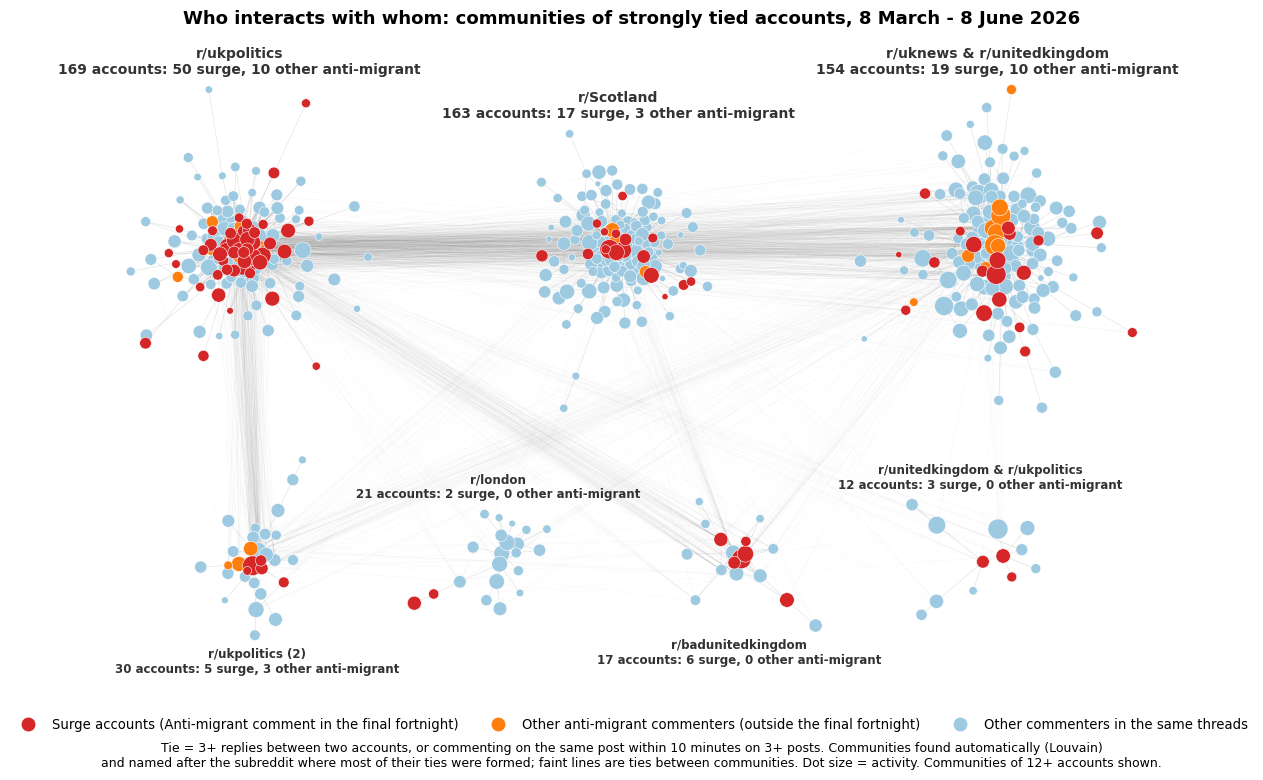

In [38]:
# Figure 8: who interacts with whom across Reddit, 8 March - 8 June 2026. Two accounts are tied if they exchanged 3+
# replies, or commented on the same post within 10 minutes of each other on 3+ different posts. Communities are found
# with the Louvain method (Blondel et al., 2008; fixed seed) and named after the subreddit in which most of each
# community's ties were formed. Red: surge accounts; orange: other anti-migrant commenters (control accounts with
# Anti-migrant comments outside the final two weeks); light blue: all other accounts. No usernames are shown.
# Dots sit in slightly different places within each community on each run, because Python orders sets differently in
# each session; the communities, ties and counts are the same every time. The saved output is the version in the paper.
import networkx as nx
from collections import Counter, defaultdict
from matplotlib.lines import Line2D

TIE_MIN_REPLIES, TIE_MIN_SHARED_POSTS, ARRIVAL_WINDOW_MIN = 3, 3, 10
OTHER_ANTI_COLOUR, OTHER_COLOUR = '#ff7f0e', '#9ecae1'

# 1. Replies between different accounts, and the subreddit each was made in
rep = pd.DataFrame({'a': df_timeline['username'].values, 'b': df_timeline['parent_id'].map(id_to_author).values,
                    'subreddit': df_timeline['subreddit'].values, 'link_id': df_timeline['link_id'].values}).dropna()
rep = rep[rep['a'] != rep['b']]
rep['u'] = np.where(rep['a'] < rep['b'], rep['a'], rep['b'])
rep['v'] = np.where(rep['a'] < rep['b'], rep['b'], rep['a'])
venues = defaultdict(Counter)   # (account, account) -> interactions in each subreddit
for (u, v, sub), n in rep.groupby(['u', 'v', 'subreddit']).size().items():
    venues[(u, v)][sub] += n


def arrivals(df, skip=frozenset()):
    # Pairs of accounts that commented on the same post within ARRIVAL_WINDOW_MIN minutes of each other, counted once
    # per post, with the subreddits where this happened. 'skip' holds (post, account, account) combinations to ignore.
    df = df.sort_values(['link_id', 'created_at'])
    secs = df['created_at'].values.astype('datetime64[s]').astype(np.int64)
    users, posts, subs = df['username'].values, df['link_id'].values, df['subreddit'].values
    counts, where = Counter(), defaultdict(Counter)
    bounds = np.flatnonzero(np.r_[True, posts[1:] != posts[:-1], True])
    for b0, b1 in zip(bounds[:-1], bounds[1:]):
        if b1 - b0 < 2:
            continue
        seen = set()
        for i in range(b0, b1):
            j = i + 1
            while j < b1 and secs[j] - secs[i] <= ARRIVAL_WINDOW_MIN * 60:
                if users[i] != users[j]:
                    pair = (users[i], users[j]) if users[i] < users[j] else (users[j], users[i])
                    if (posts[i],) + pair not in skip:
                        seen.add(pair)
                j += 1
        for pair in seen:
            counts[pair] += 1
            where[pair][subs[b0]] += 1
    return counts, where


# 2. Commenting on the same post within minutes of each other
co_posts, co_where = arrivals(df_timeline)
for pair, subs_here in co_where.items():
    venues[pair].update(subs_here)
edges_all = pd.merge(rep.groupby(['u', 'v']).size().rename('replies').reset_index(),
                     pd.DataFrame([(u, v, n) for (u, v), n in co_posts.items()], columns=['u', 'v', 'co_posts']),
                     on=['u', 'v'], how='outer').fillna(0)
edges_all[['replies', 'co_posts']] = edges_all[['replies', 'co_posts']].astype(int)

# 3. Strong ties, groups and communities
strong = edges_all[(edges_all['replies'] >= TIE_MIN_REPLIES) | (edges_all['co_posts'] >= TIE_MIN_SHARED_POSTS)]
G = nx.Graph()
G.add_weighted_edges_from(zip(strong['u'], strong['v'], strong['replies'] + strong['co_posts']))
anti_outside = set(df_merged.loc[(df_merged['llm_mapped_label'] == 'Anti-migrant') & ~in_fortnight, 'author_comment'].dropna())
kind = {n: 'surge' if n in surge_set else 'anti' if n in anti_outside else 'other' for n in G}
nx.set_node_attributes(G, kind, 'kind')
communities = nx.community.louvain_communities(G, weight='weight', seed=42)
n_kind = Counter(kind.values())
print(f"{G.number_of_nodes()} accounts with at least one strong tie ({n_kind['surge']} surge, {n_kind['anti']} other anti-migrant, "
      f"{n_kind['other']} other); {G.number_of_edges():,} ties; {len(communities)} communities "
      f"(modularity {nx.community.modularity(G, communities, weight='weight'):.2f})")


def community_name(members):
    # the subreddit in which most of the community's ties were formed (and the second, if the first has under 60%)
    where = Counter()
    for a, b in G.subgraph(members).edges():
        where.update(venues[(a, b) if a < b else (b, a)])
    total = sum(where.values())
    top = where.most_common(2)
    name = f'r/{top[0][0]}'
    if len(top) > 1 and top[0][1] / total < 0.6 and top[1][1] / total >= 0.15:
        name += f' & r/{top[1][0]}'
    return name, top[0][1] / total


rows = []
for c in sorted(communities, key=len, reverse=True):
    name, share = community_name(c)
    rows.append({'accounts': len(c), 'surge': sum(kind[n] == 'surge' for n in c), 'other anti-migrant': sum(kind[n] == 'anti' for n in c),
                 'named after': name, "share of the community's ties formed there": round(share, 2)})
community_table = pd.DataFrame(rows)
community_table.index = community_table.index + 1
print(community_table.head(8).to_string())
community_table.to_csv(HISTORY_RESULTS_DIR / 'network_communities.csv')

# Where do the surge accounts' strong ties go, compared with the accounts available to them?
tie_to = Counter(kind[b] for u, v in G.edges() for a, b in ((u, v), (v, u)) if kind[a] == 'surge')
total = sum(tie_to.values())
print(f"\nSurge accounts' strong ties: {tie_to['surge'] / total:.0%} to other surge accounts, {tie_to['anti'] / total:.0%} to other "
      f"anti-migrant commenters, {tie_to['other'] / total:.0%} to everyone else")
print(f"Share of the accounts in the network: surge {n_kind['surge'] / len(kind):.0%}, other anti-migrant {n_kind['anti'] / len(kind):.0%}, "
      f"everyone else {n_kind['other'] / len(kind):.0%}")
assortativity = nx.attribute_assortativity_coefficient(G.subgraph([n for n in G if kind[n] != 'anti']), 'kind')
print(f"Assortativity, surge vs other accounts: {assortativity:.3f} (0 = mixing at random, 1 = ties only within each group)")

# 4. Figure: the largest connected part of the network, communities of 12+ accounts, each laid out in its own area
H = G.subgraph(max(nx.connected_components(G), key=len)).copy()
shown = [c for c in sorted([c & set(H) for c in communities if c & set(H)], key=len, reverse=True) if len(c) >= 12]
H = H.subgraph(set().union(*shown)).copy()
cid = {n: i for i, c in enumerate(shown) for n in c}
big = [i for i, c in enumerate(shown) if len(c) >= 60]
small = [i for i, c in enumerate(shown) if len(c) < 60]
centre = {i: np.array([k * 4.4, 3.2]) for k, i in enumerate(big)}                                     # large communities on top
centre.update({i: np.array([0.2 + k * 8.4 / max(len(small) - 1, 1), -0.4]) for k, i in enumerate(small)})   # smaller ones below
pos = {}
for i, c in enumerate(shown):
    sub_pos = nx.spring_layout(H.subgraph(c), weight='weight', seed=11, k=1.2 / np.sqrt(len(c)), iterations=300)
    xy = np.array(list(sub_pos.values()))
    xy = (xy - xy.mean(0)) / (np.abs(xy - xy.mean(0)).max() + 1e-9)
    radius = 1.85 if len(c) >= 60 else 0.55 + 0.02 * len(c)
    for n, v in zip(sub_pos, xy):
        pos[n] = centre[i] + v * radius
activity = df_timeline.groupby('username').size()
colours = {'surge': ANTI_MIGRANT_COLOUR, 'anti': OTHER_ANTI_COLOUR, 'other': OTHER_COLOUR}

fig, ax = plt.subplots(figsize=(14, 10))
within = [(u, v) for u, v in H.edges() if cid[u] == cid[v]]
between = [(u, v) for u, v in H.edges() if cid[u] != cid[v]]
nx.draw_networkx_edges(H, pos, edgelist=between, ax=ax, width=0.25, alpha=0.05, edge_color='grey')
nx.draw_networkx_edges(H, pos, edgelist=within, ax=ax, width=0.4, alpha=0.25, edge_color='grey')
for k, z in [('other', 1), ('anti', 2), ('surge', 3)]:
    nodes = [n for n in H if kind[n] == k]
    nx.draw_networkx_nodes(H, pos, nodelist=nodes, ax=ax, node_color=colours[k], edgecolors='white', linewidths=0.4,
                           node_size=[8 + 3 * np.sqrt(activity.get(n, 1)) for n in nodes]).set_zorder(z)
used_names = Counter()
for i, c in enumerate(shown):
    name, _ = community_name(c)
    used_names[name] += 1
    if used_names[name] > 1:
        name += f' ({used_names[name]})'
    n_s, n_a = sum(kind[n] == 'surge' for n in c), sum(kind[n] == 'anti' for n in c)
    if len(c) >= 60 or small.index(i) % 2 == 1:   # labels above the large communities; alternately below/above the small ones
        y, va = max(pos[n][1] for n in c) + 0.15, 'bottom'
    else:
        y, va = min(pos[n][1] for n in c) - 0.15, 'top'
    ax.text(centre[i][0], y, f'{name}\n{len(c)} accounts: {n_s} surge, {n_a} other anti-migrant', fontsize=10 if len(c) >= 60 else 8.5,
            fontweight='bold', color='#333333', ha='center', va=va).set_zorder(5)
ax.legend(handles=[Line2D([0], [0], marker='o', ls='', color=ANTI_MIGRANT_COLOUR, ms=9, label='Surge accounts (Anti-migrant comment in the final fortnight)'),
                   Line2D([0], [0], marker='o', ls='', color=OTHER_ANTI_COLOUR, ms=9, label='Other anti-migrant commenters (outside the final fortnight)'),
                   Line2D([0], [0], marker='o', ls='', color=OTHER_COLOUR, ms=9, label='Other commenters in the same threads')],
          loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=9.5, frameon=False)
ax.set_title('Who interacts with whom: communities of strongly tied accounts, 8 March - 8 June 2026', fontsize=13, fontweight='bold')
ax.text(0.5, -0.075, 'Tie = 3+ replies between two accounts, or commenting on the same post within 10 minutes on 3+ posts. Communities found automatically (Louvain)\n'
        'and named after the subreddit where most of their ties were formed; faint lines are ties between communities. Dot size = activity. Communities of 12+ accounts shown.',
        transform=ax.transAxes, ha='center', va='top', fontsize=9)
ax.set_aspect('equal')
ax.axis('off')
plt.tight_layout()
plt.savefig(HISTORY_RESULTS_DIR / 'figure7_interaction_network.png', dpi=220, bbox_inches='tight')
plt.show()

In [39]:
# Arriving together: do surge accounts comment on the same posts within 10 minutes of one another more often than other
# accounts do? Posts in which the two accounts replied to each other (conversations) and the collected election threads
# (where surge accounts overlap by construction) are left out. For the surge accounts and the stance-matched group, the
# density of pairs that arrived together on 3+ posts is compared with random control groups of the same size.
collected_threads = set('t3_' + df_combined['parent_post_id'].astype(str).str.replace('t3_', '', regex=False))
conversations = set(zip(rep['link_id'], rep['u'], rep['v']))
arrived, _ = arrivals(df_timeline[~df_timeline['link_id'].isin(collected_threads)], skip=conversations)
arrived = pd.DataFrame([(u, v, n) for (u, v), n in arrived.items()], columns=['u', 'v', 'n'])
arrived = arrived[arrived['n'] >= 3]


def density(group):
    group = set(group)
    return (arrived['u'].isin(group) & arrived['v'].isin(group)).sum() / (len(group) * (len(group) - 1) / 2)


def cross_density(a, b):
    a, b = set(a), set(b)
    hits = ((arrived['u'].isin(a) & arrived['v'].isin(b)) | (arrived['u'].isin(b) & arrived['v'].isin(a))).sum()
    return hits / (len(a) * len(b))


rng = np.random.default_rng(42)
rows = []
for name, group in [('Surge accounts', surge_set), ('Stance-matched (Anti-migrant, not surge)', stance_group)]:
    observed = density(group)
    null = np.array([density(rng.choice(control_pool, len(group), replace=False)) for _ in range(N_RANDOM_GROUPS)])
    rows.append({'group': name, 'accounts': len(group), 'density': round(observed, 4), 'random_same_size_density': round(null.mean(), 4),
                 'times_random': round(observed / null.mean(), 1), 'p_value': round((np.sum(null >= observed) + 1) / (len(null) + 1), 3)})
arrival_tbl = pd.DataFrame(rows)
print(arrival_tbl.to_string(index=False))
arrival_tbl.to_csv(HISTORY_RESULTS_DIR / 'arriving_together_tests.csv', index=False)
rest_of_control = set(control_pool) - set(stance_group)
print(f"\nDensity of arriving together: within the surge group {density(surge_set):.3f} | surge with the stance-matched group "
      f"{cross_density(surge_set, stance_group):.3f} | surge with the other control accounts {cross_density(surge_set, rest_of_control):.3f}")

                                   group  accounts  density  random_same_size_density  times_random  p_value
                          Surge accounts       121   0.0293                    0.0090           3.2    0.001
Stance-matched (Anti-migrant, not surge)        30   0.1264                    0.0085          14.9    0.001

Density of arriving together: within the surge group 0.029 | surge with the stance-matched group 0.052 | surge with the other control accounts 0.011


### Behaviour
Posting activity, link sharing, wording and deletions, drawn from the coordination and authenticity indicators of the EU DisinfoLab's detection tree (Romero Vicente, 2024). Table 3 in the paper proposes Reddit-specific additions to the tree based on these results.

In [40]:
# Posting activity across all of Reddit: each account's comments per day before 23 April, in the final two weeks and
# after polling day; a z-score of its final-fortnight rate against its own earlier days (standard deviation floored at 1,
# so that very quiet accounts cannot produce extreme scores); and its busiest 24 hours. Surge and control accounts are
# compared with Mann-Whitney U tests.
from scipy.stats import mannwhitneyu

days = pd.date_range(ANALYSIS_START, ANALYSIS_END, freq='D')
daily = (df_timeline.groupby([df_timeline['created_at'].dt.floor('D'), 'username']).size()
         .unstack(fill_value=0).reindex(days, fill_value=0))
account_group = df_timeline.groupby('username')['group'].first()
before = daily.loc[:SURGE_START - pd.Timedelta(days=1)]
fortnight = daily.loc[SURGE_START:ELECTION_DAY]
after = daily.loc[ELECTION_DAY + pd.Timedelta(days=1):]
per = pd.DataFrame({'group': account_group, 'per_day_before': before.mean(), 'per_day_final_two_weeks': fortnight.mean(),
                    'per_day_after': after.mean()})
per['z_score'] = (per['per_day_final_two_weeks'] - per['per_day_before']) / before.std().clip(lower=1)
per['busiest_24h'] = (df_timeline.set_index('created_at').sort_index().groupby('username')['comment_id']
                      .rolling('24h').count().groupby(level=0).max())
per.to_csv(HISTORY_RESULTS_DIR / 'posting_activity_per_account.csv')

print('Medians (comments per day unless stated):')
print(per.groupby('group')[['per_day_before', 'per_day_final_two_weeks', 'per_day_after', 'z_score', 'busiest_24h']].median().round(2).to_string())
s, c = per[per['group'] == 'Surge Account'], per[per['group'] != 'Surge Account']
for col in ['per_day_before', 'per_day_final_two_weeks', 'z_score', 'busiest_24h']:
    print(f"  {col:25s} surge vs control: Mann-Whitney p = {mannwhitneyu(s[col], c[col]).pvalue:.3f}")
print(f"\nAccounts much busier in the final two weeks than their own baseline (z > 2): "
      f"surge {(s['z_score'] > 2).mean():.1%} ({(s['z_score'] > 2).sum()}), control {(c['z_score'] > 2).mean():.1%} ({(c['z_score'] > 2).sum()})")
print(f"Surge accounts' share of the two groups' comments: {before[s.index].sum().sum() / before.sum().sum():.1%} before 23 April, "
      f"{fortnight[s.index].sum().sum() / fortnight.sum().sum():.1%} in the final two weeks")

Medians (comments per day unless stated):
                   per_day_before  per_day_final_two_weeks  per_day_after  z_score  busiest_24h
group                                                                                          
Non-Surge Account            3.93                      4.8           4.55     0.24         27.0
Surge Account                4.35                      5.2           4.94     0.24         30.0
  per_day_before            surge vs control: Mann-Whitney p = 0.207
  per_day_final_two_weeks   surge vs control: Mann-Whitney p = 0.176
  z_score                   surge vs control: Mann-Whitney p = 0.620
  busiest_24h               surge vs control: Mann-Whitney p = 0.159

Accounts much busier in the final two weeks than their own baseline (z > 2): surge 3.3% (4), control 3.0% (19)
Surge accounts' share of the two groups' comments: 19.6% before 23 April, 18.8% in the final two weeks


In [41]:
# The five websites each group links to most, from every link in the complete histories.
# 1. The complete histories (prepared above)
df_history = df_timeline[['username', 'group', 'body']].copy()

# 2. Strict Domain Extraction Pattern (Bypasses markdown formatting issues)
domain_pattern = r'https?://(?:www\.)?([^/\s>\]\)]+)'

def get_clean_domain(text):
    if pd.isnull(text):
        return None
    match = re.search(domain_pattern, text)
    if match:
        domain = match.group(1).lower()
        # Drop port numbers if they happen to exist (e.g., localhost:8080)
        return domain.split(':')[0]
    return None

# Apply domain extraction safely
df_history['shared_domain'] = df_history['body'].apply(get_clean_domain)

# 3. Separate the datasets to compare behavior
df_links = df_history[df_history['shared_domain'].notnull()]

print("--- LINK SHARING FORENSIC RESULTS ---")
for name, group in df_links.groupby('group'):
    total_links = len(group)
    if total_links == 0:
        print(f"\nNo links found for the {name} cohort.")
        continue

    print(f"\nTop Domains Shared by {name} Cohort (Total Links: {total_links}):")
    top_domains = group['shared_domain'].value_counts().head(5)

    for domain, count in top_domains.items():
        percentage = (count / total_links) * 100
        print(f" -> {domain}: {count} times ({percentage:.1f}% of cohort links)")

--- LINK SHARING FORENSIC RESULTS ---

Top Domains Shared by Non-Surge Account Cohort (Total Links: 13292):
 -> preview.redd.it: 2495 times (18.8% of cohort links)
 -> en.wikipedia.org: 685 times (5.2% of cohort links)
 -> reddit.com: 678 times (5.1% of cohort links)
 -> bbc.co.uk: 546 times (4.1% of cohort links)
 -> youtu.be: 472 times (3.6% of cohort links)

Top Domains Shared by Surge Account Cohort (Total Links: 4700):
 -> preview.redd.it: 1452 times (30.9% of cohort links)
 -> en.wikipedia.org: 233 times (5.0% of cohort links)
 -> bbc.co.uk: 231 times (4.9% of cohort links)
 -> reddit.com: 185 times (3.9% of cohort links)
 -> gov.uk: 168 times (3.6% of cohort links)


In [42]:
# Coordinated link sharing (after Giglietto et al., 2020):
#  1. Co-sharing: the same link posted by two different accounts within 60 seconds, 1 hour or 24 hours, summarised as an
#     E-I index (are surge accounts' co-sharing partners other surge accounts?) and compared with random groups.
#  2. Sharer codes: share links carry a code tied to whoever pressed 'share' (Reddit /s/ links, X ?t=, YouTube ?si=,
#     Instagram igsh=, Spotify si=, TikTok _t/_r), so the same code under two accounts means one person passed the link
#     on to the other. UTM campaign tags are checked in the same way (platform share-button defaults are ignored).
#  3. Sources: the share of each account's links that point to each type of source, surge vs control.
from urllib.parse import urlsplit, parse_qs
from scipy.stats import mannwhitneyu

LINKS_DIR = HISTORY_RESULTS_DIR / 'link_coordination'
LINKS_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
df_l = df_timeline.dropna(subset=['body'])
surge_l, control_l = set(df_l.loc[df_l['group'] == 'Surge Account', 'username']), set(df_l.loc[df_l['group'] != 'Surge Account', 'username'])

URL = re.compile(r'https?://[^\s\)\]>"\'*]+')
SKIP_HOSTS = ('preview.redd.it', 'i.redd.it', 'v.redd.it', 'giphy.com', 'media.giphy.com', 'i.imgur.com', 'emoji')
FINGERPRINTS = [('reddit share link', lambda h, p, q: 'reddit.com' in h and '/s/' in p, lambda h, p, q: p),
                ('X share code', lambda h, p, q: h in ('x.com', 'twitter.com') and 't' in q, lambda h, p, q: q['t'][0]),
                ('YouTube share code', lambda h, p, q: 'youtu' in h and 'si' in q, lambda h, p, q: q['si'][0]),
                ('Instagram share code', lambda h, p, q: 'instagram' in h and 'igsh' in q, lambda h, p, q: q['igsh'][0]),
                ('Spotify share code', lambda h, p, q: 'spotify' in h and 'si' in q, lambda h, p, q: q['si'][0]),
                ('UTM campaign tag', lambda h, p, q: any(k.lower() in ('utm_campaign', 'utm_content', 'utm_id') for k in q)
                                       and not any('share' in v[0].lower() for k, v in q.items() if k.lower().startswith('utm_')),
                 lambda h, p, q: h + ' | ' + '&'.join(f'{k}={v[0]}' for k, v in sorted(q.items()) if k.lower().startswith('utm_'))),
                ('TikTok share code', lambda h, p, q: 'tiktok' in h and ('_t' in q or '_r' in q), lambda h, p, q: (q.get('_t') or q.get('_r'))[0])]
CATEGORIES = {
    'UK government / Parliament / official stats': ['gov.uk', 'parliament.uk', 'ons.gov.uk', 'nhs.uk', 'police.uk', 'legislation.gov.uk', 'gov.scot', 'gov.wales', 'europa.eu', 'echr.coe.int'],
    'Broadcasters & broadsheets': ['bbc.', 'theguardian.com', 'independent.co.uk', 'news.sky.com', 'sky.com', 'itv.com', 'channel4.com', 'ft.com', 'thetimes.', 'telegraph.co.uk', 'inews.co.uk', 'economist.com', 'reuters.com', 'apnews.com', 'scotsman.com', 'heraldscotland.com', 'politico.', 'newstatesman.com', 'spectator.co.uk', 'theconversation.com', 'lbc.co.uk', 'cityam.com', 'standard.co.uk', 'bloomberg.com', 'nytimes.com', 'cnn.com', 'aljazeera.com'],
    'Tabloids': ['dailymail.co.uk', 'express.co.uk', 'thesun.co.uk', 'mirror.co.uk', 'metro.co.uk', 'dailystar.co.uk', 'dailyrecord.co.uk', 'manchestereveningnews.co.uk', 'birminghammail.co.uk', 'walesonline.co.uk', 'liverpoolecho.co.uk', 'chroniclelive.co.uk'],
    'Right-wing / alternative media & campaign groups': ['gbnews.com', 'gbnews.uk', 'spiked-online.com', 'unherd.com', 'conservativewoman.co.uk', 'order-order.com', 'guido', 'migrationwatchuk.org', 'breitbart.com', 'rmx.news', 'remix', 'europeanconservative.com', 'rebelnews', 'reformparty.uk', 'reformuk', 'voiceofeurope', 'thepostmillennial', 'dailysceptic.org', 'freespeechunion', 'talktv', 'thecritic.co.uk', 'brusselssignal'],
    'Left / progressive alternative media': ['novaramedia.com', 'doubledown.news', 'bylinetimes.com', 'thecanary.co', 'leftfootforward.org', 'declassifieduk.org', 'tribunemag.co.uk', 'opendemocracy.net', 'hopenothate.org.uk', 'jacobin.com', 'morningstaronline.co.uk', 'theskwawkbox'],
    'Social media & video': ['x.com', 'twitter.com', 'youtube.com', 'youtu.be', 'tiktok.com', 'facebook.com', 'instagram.com', 'rumble.com', 'bsky.app', 'threads.net', 't.me', 'substack.com', 'spotify.com'],
    'Wikipedia': ['wikipedia.org'],
    'Reddit': ['reddit.com', 'redd.it'],
}
TRACKING = {'si', 't', 's', 'igsh', 'igshid', 'share', 'ref', 'ref_src', 'fbclid', 'gclid', '_t', '_r', 'context', 'feature', 'smid', 'mibextid',
            'cmpid', 'at_medium', 'at_campaign', 'ito', 'dicbo', 'sh', 'share_id', 'utm', 'rdt', 'width', 'height', 'format', 'auto', 'crop'}


def category(host):
    for cat, keys in CATEGORIES.items():
        if any(k in host for k in keys):
            return cat
    return 'Other'


# Every link, normalised (tracking parameters removed) so that the same page counts as the same link
rows, prints = [], []
for r in df_l.itertuples():
    for raw in URL.findall(str(r.body).replace('\\_', '_')):
        raw = raw.rstrip('.,;:!?')
        try:
            s = urlsplit(raw)
        except ValueError:
            continue
        host = s.netloc.lower().split(':')[0].removeprefix('www.').removeprefix('m.').removeprefix('old.').removeprefix('np.')
        if not host or any(k in host for k in SKIP_HOSTS):
            continue
        q = parse_qs(s.query)
        for name, test, token in FINGERPRINTS:
            try:
                if test(host, s.path, q):
                    prints.append({'username': r.username, 'group': r.group, 'type': name, 'code': token(host, s.path, q), 'created_at': r.created_at, 'comment_id': r.comment_id})
            except Exception:
                pass
        path = s.path.rstrip('/').lower()
        keep = sorted((k, v[0]) for k, v in q.items() if k.lower() not in TRACKING and not k.lower().startswith('utm_'))
        if keep:
            path += '?' + '&'.join(f'{k}={v}' for k, v in keep)   # e.g. YouTube v=, playlist list=, page id=
        if host == 'youtu.be':
            host, path = 'youtube.com', '/watch?v=' + s.path.strip('/')
        if host in ('x.com', 'twitter.com'):
            host = 'x.com'
        rows.append({'username': r.username, 'group': r.group, 'created_at': r.created_at, 'comment_id': r.comment_id,
                     'host': host, 'url_norm': host + path, 'category': category(host)})
links = pd.DataFrame(rows)
print(f"{len(links):,} links from {links['username'].nunique()} accounts: surge {(links['group'] == 'Surge Account').sum():,}, "
      f"control {(links['group'] != 'Surge Account').sum():,}")


# 1. Co-sharing
def cosharing_pairs(links, seconds):
    pairs = {}
    for url, g in links.sort_values('created_at').groupby('url_norm'):
        if g['username'].nunique() < 2:
            continue
        t = g['created_at'].values.astype('datetime64[s]').astype(np.int64)
        u = g['username'].values
        for i in range(len(g)):
            j = i + 1
            while j < len(g) and t[j] - t[i] <= seconds:
                if u[i] != u[j]:
                    pairs.setdefault(tuple(sorted((u[i], u[j]))), set()).add(url)
                j += 1
    return pairs


def cosharing_ei(pairs, group):
    inside = sum(1 for a, b in pairs if a in group and b in group)
    outside = sum(1 for a, b in pairs if (a in group) != (b in group))
    return inside, outside, (outside - inside) / (inside + outside) if inside + outside else np.nan


summary = []
pool = sorted(control_l & set(links['username']))
surge_with_links = surge_l & set(links['username'])
for label, secs in [('60 seconds', 60), ('1 hour', 3600), ('24 hours', 86400)]:
    pairs = cosharing_pairs(links, secs)
    inside, outside, e = cosharing_ei(pairs, surge_l)
    rand = np.array([cosharing_ei(pairs, set(rng.choice(pool, len(surge_with_links), replace=False)))[2] for _ in range(1000)])
    rand = rand[~np.isnan(rand)]
    p = (np.sum(rand <= e) + 1) / (len(rand) + 1) if len(rand) and not np.isnan(e) else np.nan
    print(f"\nCo-sharing within {label}: {len(pairs)} account pairs shared at least one link")
    print(f"   surge-surge pairs {inside}, surge-other {outside} -> E-I {e:+.3f} | random groups mean {np.nanmean(rand) if len(rand) else np.nan:+.3f} | p = {p:.3f}")
    summary.append({'check': f'co-sharing within {label}', 'surge_surge_pairs': inside, 'surge_other_pairs': outside, 'surge_EI': e,
                    'random_mean_EI': np.nanmean(rand) if len(rand) else np.nan, 'p_value': p})

# 2. Sharer codes and campaign tags
fp = pd.DataFrame(prints).drop_duplicates(['comment_id', 'type', 'code'])   # markdown links repeat the same URL
shared = fp.groupby(['type', 'code']).filter(lambda g: g['username'].nunique() > 1)
print(f"\nShare links carrying a sharer code or campaign tag: {len(fp)} ({fp['type'].value_counts().to_dict()})")
codes = shared.groupby(['type', 'code']).agg(accounts=('username', 'nunique'), surge_accounts=('username', lambda x: len(set(x) & surge_l)),
                                             first=('created_at', 'min'), last=('created_at', 'max')).reset_index()
print(f"   the same code under more than one account: {len(codes)}")
if len(codes):
    print(codes.to_string(index=False, max_colwidth=90))

# 3. Where links point (per-account shares, so that one prolific sharer cannot dominate; accounts with 3+ links)
acc_links = links.groupby(['username', 'group', 'category']).size().unstack(fill_value=0)
acc_links = acc_links.div(acc_links.sum(axis=1), axis=0)
acc_links = acc_links[links.groupby('username').size().reindex(acc_links.index.get_level_values(0)).values >= 3]
is_surge_row = acc_links.index.get_level_values(1) == 'Surge Account'
print(f"\nWhere links point (average share per account; accounts with 3+ links: surge {is_surge_row.sum()}, control {(~is_surge_row).sum()})")
cat_rows = []
for cat in acc_links.columns:
    s, c = acc_links[is_surge_row][cat], acc_links[~is_surge_row][cat]
    p = mannwhitneyu(s, c).pvalue
    cat_rows.append({'category': cat, 'surge_mean_share': s.mean(), 'control_mean_share': c.mean(), 'p_value': p})
    print(f"   {cat:50s} surge {s.mean():6.1%}  control {c.mean():6.1%}  p = {p:.3f}")
pd.DataFrame(cat_rows).to_csv(LINKS_DIR / 'link_categories_surge_vs_control.csv', index=False)
pd.DataFrame(summary).to_csv(LINKS_DIR / 'link_coordination_summary.csv', index=False)

22,194 links from 607 accounts: surge 5,131, control 17,063



Co-sharing within 60 seconds: 1 account pairs shared at least one link
   surge-surge pairs 0, surge-other 0 -> E-I +nan | random groups mean +0.830 | p = nan



Co-sharing within 1 hour: 32 account pairs shared at least one link
   surge-surge pairs 2, surge-other 12 -> E-I +0.714 | random groups mean +0.849 | p = 0.241



Co-sharing within 24 hours: 144 account pairs shared at least one link
   surge-surge pairs 10, surge-other 58 -> E-I +0.706 | random groups mean +0.857 | p = 0.058

Share links carrying a sharer code or campaign tag: 800 ({'YouTube share code': 406, 'reddit share link': 329, 'UTM campaign tag': 21, 'Instagram share code': 21, 'Spotify share code': 14, 'X share code': 9})
   the same code under more than one account: 1
            type                                                                                       code  accounts  surge_accounts               first                last
UTM campaign tag toolstation.com | utm_campaign=googleshoppingfeed&utm_medium=feed&utm_source=googleshop...         2               1 2026-03-30 11:50:43 2026-05-10 08:51:29

Where links point (average share per account; accounts with 3+ links: surge 86, control 388)
   Broadcasters & broadsheets                         surge  15.9%  control  13.5%  p = 0.099
   Left / progressive alternative media 

In [43]:
# Copy-paste and near-identical wording across different accounts.
#   Phase 1: identical comments (ignoring case and surrounding spaces) posted by more than one account.
#   Phase 2: near-identical comments, with sentence-embedding cosine similarity of 0.85 or more (all-MiniLM-L6-v2;
#            Reimers & Gurevych, 2019). Quoted lines are removed first, since a reply quoting its parent would otherwise
#            look near-identical to it; only comments of 5+ words are compared (identical short replies are covered by
#            Phase 1), and each distinct text is embedded once. The pairs are saved, and reused unless
#            RUN_SIMILARITY_EMBEDDINGS = True.
import torch
from sentence_transformers import SentenceTransformer

SEMANTIC_MATCHES_FILE = HISTORY_RESULTS_DIR / 'semantic_matches_across_accounts.csv'
SIMILARITY_THRESHOLD, MIN_WORDS_SEMANTIC = 0.85, 5

df = df_timeline.dropna(subset=['body'])[['username', 'comment_id', 'subreddit', 'body']].copy()
df['body'] = df['body'].astype(str)
df = df[~df['body'].isin(['[deleted]', '[removed]'])].reset_index(drop=True)

print('--- Phase 1: Exact Duplicate Detection ---')
df['cleaned_body'] = df['body'].str.lower().str.strip()
dups = df[df.duplicated(subset=['cleaned_body'], keep=False)]
grouped = dups.groupby('cleaned_body')['username'].apply(lambda x: list(set(x))).reset_index()
grouped['unique_account_count'] = grouped['username'].apply(len)
coordinated_exact = grouped[grouped['unique_account_count'] > 1].sort_values('unique_account_count', ascending=False)
surge_set_sim = set(surge_users)
coordinated_exact['surge_accounts'] = coordinated_exact['username'].apply(lambda us: len(set(us) & surge_set_sim))
coordinated_exact.to_csv(HISTORY_RESULTS_DIR / 'exact_duplicates_across_accounts.csv', index=False)
words = coordinated_exact['cleaned_body'].str.split().str.len()
print(f"{len(coordinated_exact)} identical comments were posted by more than one account "
      f"({(words >= MIN_WORDS_SEMANTIC).sum()} of them 5+ words long; {(coordinated_exact['surge_accounts'] >= 2).sum()} posted by 2+ surge accounts)")

print('\n--- Phase 2: Semantic Homogeneity Detection ---')
# Quoted lines (starting '>') are removed, so a reply that quotes its parent is not counted as a match
def strip_quotes(text):
    return '\n'.join(l for l in str(text).splitlines() if not l.lstrip().startswith(('>', '&gt;'))).strip()
df['unquoted'] = df['body'].map(strip_quotes).str.lower()
long = df[df['unquoted'].str.split().str.len() >= MIN_WORDS_SEMANTIC].copy()
texts = long['unquoted'].drop_duplicates().tolist()
text_index = {t: i for i, t in enumerate(texts)}
long['text_id'] = long['unquoted'].map(text_index)
print(f"{len(long):,} comments with {MIN_WORDS_SEMANTIC}+ words, {len(texts):,} distinct texts")
if SEMANTIC_MATCHES_FILE.exists() and not RUN_SIMILARITY_EMBEDDINGS:
    results_df = pd.read_csv(SEMANTIC_MATCHES_FILE)
    print(f"Using the saved Phase 2 results: {len(results_df):,} near-identical pairs across different accounts")
else:
    device = 'mps' if torch.backends.mps.is_available() else 'cpu'
    model = SentenceTransformer('all-MiniLM-L6-v2', device=device)
    emb = torch.from_numpy(model.encode(texts, batch_size=256, normalize_embeddings=True, show_progress_bar=True))
    # embeddings are returned to the CPU and compared there in blocks of 4,096 x 65,536 texts, each pair once
    pairs = []
    Q, C = 4096, 65536
    for qs in range(0, len(texts), Q):
        q = emb[qs:qs + Q]
        for cs in range(qs, len(texts), C):
            sims = q @ emb[cs:cs + C].T
            hit = torch.nonzero(sims >= SIMILARITY_THRESHOLD)
            if len(hit):
                i = hit[:, 0] + qs
                j = hit[:, 1] + cs
                keep = j > i
                if keep.any():
                    pairs.append(torch.stack([i[keep], j[keep], (sims[hit[:, 0], hit[:, 1]][keep] * 1000).round().int()], 1).cpu())
    pairs = torch.cat(pairs).numpy() if pairs else np.empty((0, 3), dtype=int)
    print(f"{len(pairs):,} pairs of distinct texts with similarity >= {SIMILARITY_THRESHOLD}")

    # Expand text pairs back to the comments (and accounts) that posted them, keeping pairs from different accounts
    inst = long[['text_id', 'username', 'subreddit', 'comment_id', 'body']]
    pt = pd.DataFrame(pairs, columns=['t1', 't2', 'score'])
    m = pt.merge(inst.add_suffix('_1'), left_on='t1', right_on='text_id_1').merge(inst.add_suffix('_2'), left_on='t2', right_on='text_id_2')
    m = m[m['username_1'] != m['username_2']]
    results_df = pd.DataFrame({'similarity_score': (m['score'] / 1000).round(3), 'user_1': m['username_1'], 'subreddit_1': m['subreddit_1'],
                               'comment_id_1': m['comment_id_1'], 'body_1': m['body_1'], 'user_2': m['username_2'], 'subreddit_2': m['subreddit_2'],
                               'comment_id_2': m['comment_id_2'], 'body_2': m['body_2']}).sort_values('similarity_score', ascending=False)
    results_df.to_csv(SEMANTIC_MATCHES_FILE, index=False)
    print(f"Found {len(results_df):,} near-identical pairs across different accounts; saved to {SEMANTIC_MATCHES_FILE.name}")

--- Phase 1: Exact Duplicate Detection ---


1261 identical comments were posted by more than one account (67 of them 5+ words long; 125 posted by 2+ surge accounts)

--- Phase 2: Semantic Homogeneity Detection ---


445,043 comments with 5+ words, 443,456 distinct texts
Using the saved Phase 2 results: 1,370 near-identical pairs across different accounts


In [44]:
# Sorts the near-identical pairs into Surge-Surge, Surge-Non-Surge and Non-Surge-Non-Surge.
def compare_surge_vs_baseline(matches_file, surge_usernames_list):
    print(f"Loading pairs from {matches_file.name}...")
    try:
        df = pd.read_csv(matches_file)
    except FileNotFoundError:
        print(f"Error: Could not find '{matches_file}'. Run the previous script first.")
        return

    if df.empty:
        print("No high-similarity pairs to compare.")
        return

    # a set, for fast look-ups
    surge_set = set(surge_usernames_list)

    def categorize_pair(row):
        u1_is_surge = row['user_1'] in surge_set
        u2_is_surge = row['user_2'] in surge_set

        if u1_is_surge and u2_is_surge:
            return 'Surge <-> Surge'
        elif u1_is_surge or u2_is_surge:
            return 'Surge <-> Non-Surge'
        else:
            return 'Non-Surge <-> Non-Surge'

    # Apply categorization to every pair
    df['pair_type'] = df.apply(categorize_pair, axis=1)

    # Calculate statistics
    stats_table = df.groupby('pair_type').agg(
        pair_count=('similarity_score', 'count'),
        avg_similarity=('similarity_score', 'mean'),
        max_similarity=('similarity_score', 'max')
    ).reset_index()

    # Calculate percentages
    total_pairs = len(df)
    stats_table['percentage_of_total_matches'] = (stats_table['pair_count'] / total_pairs * 100).round(2)

    # Display Results
    print("\n📊 --- NETWORK HOMOGENEITY COMPARISON REPORT ---")
    print("-" * 75)
    print(stats_table.to_string(index=False))
    print("-" * 75)
    print(f"Total High-Similarity Pairs Analyzed: {total_pairs}\n")

    # Save categorized data to a new file for deeper inspection
    df.to_csv(HISTORY_RESULTS_DIR / 'categorized_network_similarity.csv', index=False)
    print("Full breakdown saved to categorized_network_similarity.csv")

    # Isolate just the pure surge coordination
    surge_to_surge = df[df['pair_type'] == 'Surge <-> Surge']
    surge_to_surge.to_csv(HISTORY_RESULTS_DIR / 'pure_surge_coordination.csv', index=False)

surge_accounts = list(surge_users)

# Run the comparison
compare_surge_vs_baseline(SEMANTIC_MATCHES_FILE, surge_accounts)

Loading pairs from semantic_matches_across_accounts.csv...

📊 --- NETWORK HOMOGENEITY COMPARISON REPORT ---
---------------------------------------------------------------------------
              pair_type  pair_count  avg_similarity  max_similarity  percentage_of_total_matches
Non-Surge <-> Non-Surge         937        0.897828           1.000                        68.39
    Surge <-> Non-Surge         391        0.889276           1.000                        28.54
        Surge <-> Surge          42        0.896071           0.987                         3.07
---------------------------------------------------------------------------
Total High-Similarity Pairs Analyzed: 1370

Full breakdown saved to categorized_network_similarity.csv


In [45]:
# Puts the pair counts in proportion. If pairs formed at random among the comments compared, the expected share of each
# pair type would follow from each group's share of those comments; a ratio well above 1 for Surge-Surge pairs would
# suggest that surge accounts echo one another unusually often.
cat = pd.read_csv(HISTORY_RESULTS_DIR / 'categorized_network_similarity.csv') if (HISTORY_RESULTS_DIR / 'categorized_network_similarity.csv').exists() else pd.DataFrame()
if len(cat):
    p_s = long['username'].isin(set(surge_users)).mean()
    expected = {'Surge <-> Surge': p_s ** 2, 'Surge <-> Non-Surge': 2 * p_s * (1 - p_s), 'Non-Surge <-> Non-Surge': (1 - p_s) ** 2}
    obs = cat['pair_type'].value_counts(normalize=True)
    table = pd.DataFrame({'observed_share_%': obs.mul(100).round(2), 'expected_if_random_%': pd.Series(expected).mul(100).round(2)})
    table['ratio_observed_to_expected'] = (table['observed_share_%'] / table['expected_if_random_%']).round(2)
    print(f"Surge accounts wrote {p_s:.1%} of the comments compared.")
    print(table.to_string())
    ss = cat[cat['pair_type'] == 'Surge <-> Surge']
    n_account_pairs = ss[['user_1', 'user_2']].apply(lambda r: tuple(sorted(r)), axis=1).nunique() if len(ss) else 0
    print(f"\nSurge <-> Surge pairs: {len(ss)}, from {n_account_pairs} pairs of accounts ({len(set(ss['user_1']) | set(ss['user_2']))} accounts)")

Surge accounts wrote 19.1% of the comments compared.
                         observed_share_%  expected_if_random_%  ratio_observed_to_expected
Non-Surge <-> Non-Surge             68.39                 65.46                        1.04
Surge <-> Non-Surge                 28.54                 30.89                        0.92
Surge <-> Surge                      3.07                  3.64                        0.84

Surge <-> Surge pairs: 42, from 35 pairs of accounts (40 accounts)


In [46]:
# Near-identical wording between different surge accounts, using only comments of 15+ words (so that stock phrases such
# as "This." do not count), with quoted lines removed. The pairs are saved for qualitative reading; only counts are
# printed here. The saved pairs are reused unless RUN_SIMILARITY_EMBEDDINGS = True.
LONG_PAIRS_FILE = HISTORY_RESULTS_DIR / 'identified_long_surge_similarities.csv'

surge_df = df_timeline[df_timeline['group'] == 'Surge Account'].dropna(subset=['body']).copy()
surge_df['body'] = surge_df['body'].astype(str).map(strip_quotes)
long_surge_df = surge_df[surge_df['body'].str.split().str.len() >= 15]
print(f"Surge accounts' comments: {len(surge_df):,}, of which {len(long_surge_df):,} have 15+ words")

if LONG_PAIRS_FILE.exists() and not RUN_SIMILARITY_EMBEDDINGS:
    long_pairs = pd.read_csv(LONG_PAIRS_FILE)
else:
    from sentence_transformers import SentenceTransformer, util
    model = SentenceTransformer('all-MiniLM-L6-v2')
    sentences, usernames = long_surge_df['body'].tolist(), long_surge_df['username'].tolist()
    subreddits, comment_ids = long_surge_df['subreddit'].tolist(), long_surge_df['comment_id'].tolist()
    paraphrases = util.paraphrase_mining(model, sentences, query_chunk_size=2000, corpus_chunk_size=50000, show_progress_bar=True)
    long_pairs = pd.DataFrame([{'similarity_score': round(score, 3), 'username_A': usernames[i], 'comment_A': sentences[i],
                                'subreddit_A': subreddits[i], 'comment_id_A': comment_ids[i], 'username_B': usernames[j],
                                'comment_B': sentences[j], 'subreddit_B': subreddits[j], 'comment_id_B': comment_ids[j]}
                               for score, i, j in paraphrases if score >= 0.85 and usernames[i] != usernames[j]],
                              columns=['similarity_score', 'username_A', 'comment_A', 'subreddit_A', 'comment_id_A',
                                       'username_B', 'comment_B', 'subreddit_B', 'comment_id_B'])
    long_pairs.sort_values('similarity_score', ascending=False).to_csv(LONG_PAIRS_FILE, index=False)

print(f"Near-identical long comments (similarity >= 0.85) between different surge accounts: {len(long_pairs)} pairs, "
      f"involving {pd.concat([long_pairs['username_A'], long_pairs['username_B']]).nunique()} accounts")
print('Similarity scores:', ', '.join(f'{s:.2f}' for s in long_pairs['similarity_score']))

Surge accounts' comments: 92,227, of which 62,306 have 15+ words
Near-identical long comments (similarity >= 0.85) between different surge accounts: 8 pairs, involving 14 accounts
Similarity scores: 0.96, 0.93, 0.88, 0.86, 0.86, 0.86, 0.85, 0.85


In [47]:
# Deleted and removed comments: the share of each group's comments deleted by their authors or removed by moderators or
# Reddit, within 36 hours (Arctic Shift's second look at each comment) and when re-checked through the Reddit API in
# October 2026, by period. Quietly deleting election-period comments would suggest a campaign covering its tracks; a high
# removal rate would point to rule-breaking content.
from scipy.stats import mannwhitneyu, chi2_contingency
DEL_A, DEL_B = DELETION_ARCTIC_FILE, DELETION_REDDIT_FILE

dl = df_timeline[['username', 'comment_id', 'created_at', 'group']].copy()
if DEL_A.exists():
    dl = dl.merge(pd.read_csv(DEL_A).drop_duplicates('comment_id'), on='comment_id', how='left')
    dl['user_deleted_36h'] = dl['was_deleted_within_36h'].astype('boolean').fillna(False).astype(bool) & (dl['removal_type_36h'] == 'deleted')
    dl['removed_36h'] = dl['was_deleted_within_36h'].astype('boolean').fillna(False).astype(bool) & (dl['removal_type_36h'] != 'deleted')
if DEL_B.exists():
    dl = dl.merge(pd.read_csv(DEL_B).drop_duplicates('comment_id'), on='comment_id', how='left')
    dl['user_deleted_by_oct'] = dl['status_now'] == 'deleted by user'
    dl['removed_by_oct'] = dl['status_now'] == 'removed (moderators/Reddit)'
measures = [m for m in ['user_deleted_36h', 'removed_36h', 'user_deleted_by_oct', 'removed_by_oct'] if m in dl]
dl['period'] = np.select([dl['created_at'] < SURGE_START, dl['created_at'] < ELECTION_DAY + pd.Timedelta(days=1)],
                         ['1. before 23 Apr', '2. final two weeks'], '3. after polling day')
dl.to_csv(HISTORY_RESULTS_DIR / 'deletion_status_per_comment.csv', index=False)

print('Share of comments taken down (all comments pooled):')
pooled = dl.groupby(['group', 'period'])[measures].mean().mul(100).round(2)
print(pooled.to_string(), '\n')
for m in measures:
    t = pd.crosstab(dl['group'], dl[m]); p = chi2_contingency(t)[1] if t.shape == (2, 2) else np.nan
    per_acc = dl.groupby(['username', 'group'])[m].mean().reset_index()
    s, c = per_acc[per_acc['group'] == 'Surge Account'][m], per_acc[per_acc['group'] != 'Surge Account'][m]
    print(f"{m:22s} surge {dl.loc[dl['group'] == 'Surge Account', m].mean():6.2%} vs control {dl.loc[dl['group'] != 'Surge Account', m].mean():6.2%} "
          f"(chi-square p = {p:.3g}) | per-account medians {s.median():.2%} vs {c.median():.2%} (Mann-Whitney p = {mannwhitneyu(s, c).pvalue:.3g})")

# Did anyone clear out their election-fortnight comments in particular?
acc = dl.groupby(['username', 'group', 'period'])[measures[-2] if len(measures) > 1 else measures[0]].mean().unstack('period')
if '2. final two weeks' in acc and '1. before 23 Apr' in acc:
    acc['jump'] = acc['2. final two weeks'] - acc['1. before 23 Apr']
    print('\nAccounts whose final-fortnight comments were user-deleted far more than their earlier ones (jump of 50+ points):')
    jumped = acc[acc['jump'] >= 0.5].groupby(level='group').size()
    print(jumped.to_string() if len(jumped) else '   none')

# (Anti-migrant and other comments are not compared here: the thread comments were collected in October, so comments
#  deleted before then were never collected, which would bias that comparison.)

Share of comments taken down (all comments pooled):
                                        user_deleted_36h  removed_36h  user_deleted_by_oct  removed_by_oct
group             period                                                                                  
Non-Surge Account 1. before 23 Apr                  1.32         1.23                 1.82            1.68
                  2. final two weeks                1.19         1.58                 1.39            1.74
                  3. after polling day              1.25         1.17                 1.65            1.34
Surge Account     1. before 23 Apr                  0.85         1.04                 1.07            1.21
                  2. final two weeks                1.06         1.63                 1.27            1.80
                  3. after polling day              1.06         1.35                 1.22            1.91 

user_deleted_36h       surge  0.96% vs control  1.27% (chi-square p = 1.07e-14) | per-acco

user_deleted_by_oct    surge  1.16% vs control  1.68% (chi-square p = 1.01e-29) | per-account medians 0.30% vs 0.24% (Mann-Whitney p = 0.75)
removed_by_oct         surge  1.57% vs control  1.56% (chi-square p = 0.969) | per-account medians 0.95% vs 0.60% (Mann-Whitney p = 0.0105)

Accounts whose final-fortnight comments were user-deleted far more than their earlier ones (jump of 50+ points):
   none


### Supplementary: traces of individually recruited accounts
Not reported in the paper. If the surge involved commenters recruited individually rather than a coordinated network, the coordination tests above would not detect them. Two of their other likely traces are tested here: posting concentrated in working hours, and several accounts written by one person.

In [48]:
# Accounts with 50+ comments in the study period are scored.
#  1. Working-hours signature: share of comments posted in UK working hours (Monday-Friday 09:00-17:59, excluding the
#     bank holidays of 3 April, 6 April, 4 May and 25 May 2026), and how much busier an account is on working days.
#  2. Several accounts, one writer: character 2-4-gram TF-IDF profiles of each account's text with every word of four or
#     more letters masked, so that punctuation, short function words, capitalisation and layout dominate over topic.
#     Pairs whose style is more similar than their shared subreddits predict (top 0.1% of control-control pairs) are
#     then checked for posting in the same threads (3+) while rarely being active in the same hour (under half of chance).
# Only aggregate counts are printed.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from scipy.stats import mannwhitneyu

BANK_HOLIDAYS = pd.to_datetime(['2026-04-03', '2026-04-06', '2026-05-04', '2026-05-25']).date
counts = df_timeline.groupby('username').size()
tl = df_timeline[df_timeline['username'].isin(counts[counts >= 50].index)].dropna(subset=['body']).copy()
groups = tl.groupby('username')['group'].first()

# 1. Working hours
workday = (tl['created_at'].dt.dayofweek < 5) & ~tl['created_at'].dt.date.isin(BANK_HOLIDAYS)
tl['office_hours'] = workday & tl['created_at'].dt.hour.between(9, 17)
tl['workday'] = workday
calendar = pd.Series(pd.date_range(ANALYSIS_START, ANALYSIS_END))
n_work = ((calendar.dt.dayofweek < 5) & ~calendar.dt.date.isin(BANK_HOLIDAYS)).sum()
n_off = len(calendar) - n_work
w = tl.groupby('username').agg(share_office_hours=('office_hours', 'mean'), share_on_workdays=('workday', 'mean'))
w['weekday_vs_weekend_rate'] = (w['share_on_workdays'] / n_work) / ((1 - w['share_on_workdays']).clip(lower=1e-3) / n_off)
w['group'] = groups
srg, ctrl = w[w['group'] == 'Surge Account'], w[w['group'] != 'Surge Account']
print(f"Accounts with 50+ comments: surge {len(srg)}, control {len(ctrl)}")
for col in ['share_office_hours', 'weekday_vs_weekend_rate']:
    print(f"  {col:25s} surge median {srg[col].median():.3f} | control median {ctrl[col].median():.3f} | "
          f"Mann-Whitney p = {mannwhitneyu(srg[col], ctrl[col]).pvalue:.3f}")
both = (w['share_office_hours'] > ctrl['share_office_hours'].quantile(.95)) & (w['weekday_vs_weekend_rate'] > ctrl['weekday_vs_weekend_rate'].quantile(.95))
print(f"  beyond the control's 95th percentile on both: surge {int(both[srg.index].sum())} of {len(srg)}, control {int(both[ctrl.index].sum())} of {len(ctrl)}")

# 2. Writing style
tl['unquoted'] = tl['body'].map(lambda b: re.sub(r'https?://\S+', ' ', strip_quotes(b)))
texts = tl[tl['unquoted'].str.split().str.len() >= 5].groupby('username')['unquoted'].apply(lambda s: '\n'.join(s.head(400))[:80000])
accts = list(texts.index)
masked = texts.map(lambda t: re.sub(r'\b[A-Za-z]{4,}\b', lambda m: 'X' if m.group()[0].islower() else 'C', t))
S = TfidfVectorizer(analyzer='char', ngram_range=(2, 4), min_df=5, sublinear_tf=True).fit_transform(masked)
style = (S @ S.T).toarray()
subs = tl.groupby(['username', 'subreddit']).size().unstack(fill_value=0).reindex(accts)
topic = normalize(subs.values) @ normalize(subs.values).T
iu = np.triu_indices(len(accts), 1)
is_s = np.array([groups[a] == 'Surge Account' for a in accts])
pair_type = np.where(is_s[iu[0]] & is_s[iu[1]], 'surge-surge', np.where(is_s[iu[0]] | is_s[iu[1]], 'surge-control', 'control-control'))
cc = pair_type == 'control-control'
slope, intercept = np.polyfit(topic[iu][cc], style[iu][cc], 1)
resid = style[iu] - (intercept + slope * topic[iu])
outlier = resid > np.quantile(resid[cc], 0.999)
posts = tl.groupby('username')['link_id'].apply(set)
hours = tl.assign(h=tl['created_at'].dt.floor('h')).groupby('username')['h'].apply(set)
n_hours = len(pd.date_range(ANALYSIS_START, ANALYSIS_END + pd.Timedelta(days=1), freq='h'))
full_combination = 0
for k in np.flatnonzero(outlier):
    a, b = accts[iu[0][k]], accts[iu[1][k]]
    overlap = len(hours[a] & hours[b]) / max(len(hours[a]) * len(hours[b]) / n_hours, 1e-9)
    full_combination += int(len(posts[a] & posts[b]) >= 3 and overlap < 0.5)
print(f"\nWriting-style outlier pairs (top 0.1% of control-control pairs), observed vs expected by chance:")
for t in ['surge-surge', 'surge-control', 'control-control']:
    print(f"  {t:16s} {int((outlier & (pair_type == t)).sum()):3d} vs {(pair_type == t).sum() * 0.001:.1f}")
print(f"Outlier pairs that also share 3+ threads and are rarely active in the same hour: {full_combination}")

Accounts with 50+ comments: surge 114, control 573
  share_office_hours        surge median 0.362 | control median 0.344 | Mann-Whitney p = 0.467
  weekday_vs_weekend_rate   surge median 1.143 | control median 1.106 | Mann-Whitney p = 0.933
  beyond the control's 95th percentile on both: surge 2 of 114, control 14 of 573



Writing-style outlier pairs (top 0.1% of control-control pairs), observed vs expected by chance:
  surge-surge        6 vs 6.4
  surge-control     71 vs 65.3
  control-control  164 vs 163.9
Outlier pairs that also share 3+ threads and are rarely active in the same hour: 0
